<a href="https://colab.research.google.com/github/diego-giustini/Breast_cancer_explainability/blob/main/cineca1809_DualEffNet_1024_explainability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Metadata

In [ ]:
## ### COLAB ONLY
#from google.colab import drive
#drive.mount('/content/drive')
#
##%pip install captum
#%pip install pydicom
#%pip install opencv-python
#%pip install torchinfo
#%pip install efficientnet_pytorch
#
#
#%cd /content
#%cd 'drive/MyDrive/progetto'
#%ls
#dataset_folder = './' # COLAB

dataset_folder = '../dataset' # CINECA

In [ ]:
%pwd

'/leonardo/home/userexternal/fpatrizi/progetto'

In [ ]:
import os
import pandas as pd
import numpy as np

def load_and_filter_data(root, csv_name):
    """
    Loads annotation CSV and processes .dicom images under root
    Only includes study folders that contain at least 4 images.
    Returns merged DataFrame.
    """
    # Load the annotation CSV
    try:
        df = pd.read_csv(os.path.join(root, csv_name))
        print("Dataset file loaded")
    except FileNotFoundError:
        print(f"Error: The file was not found at the specified path: {csv_name}")
        return None
    except Exception as e:
        print(f"Error while loading the file: {e}")
        return None

    image_root = os.path.join(root, 'images')
    ext = '.dicom'
    name_images = []

    # Walk through folders and collect valid studies (4 or 2 images per study)
    for folder in os.listdir(image_root):
        folder_path = os.path.join(image_root, folder)
        if os.path.isdir(folder_path):
            dicom_files = [f for f in os.listdir(folder_path) if f.lower().endswith(ext)]
            if (len(dicom_files) == 2 or len(dicom_files) == 4):
                for file in dicom_files:
                    image_id = file[:-6]  # remove '.dicom'
                    name_images.append([folder, image_id])

    if not name_images:
        print("No valid images found with 4 .dicom files per study.")
        return None

    print(f"Number of images: {len(name_images)} for a total of valid studies of {int(len(name_images)/4)}")

    images_df = pd.DataFrame(name_images, columns=['study_id', 'image_id'])

    # Merge with CSV data
    data = images_df.merge(df, how='left').drop_duplicates(ignore_index=True)
    print(f"Total rows after merging: {len(data)}, number of image pairs: {len(data)/2}")

    return data


In [ ]:
data = load_and_filter_data(dataset_folder, 'breast-level_annotations.csv').dropna(how='any')
#data = load_and_filter_data(dataset_folder, 'finding_annotations.csv').dropna(how='any')
display(data.head())

# STUDIES WITH ODD NUM OF IMAGES
counts = data['study_id'].value_counts()
study_ids_not_4 = counts[(counts != 4) & (counts != 2)].index
df_twice = data[data['study_id'].isin(study_ids_not_4)]
print("Number of studies with odd number of images: ", len(df_twice))

Dataset file loaded
Number of images: 18044 for a total of valid studies of 4511
Total rows after merging: 18044, number of image pairs: 9022.0


,study_id,image_id,series_id,laterality,view_position,height,width,breast_birads,breast_density,split
0,07b2966671cd768f41e0e9e86d57c5af,3112a3eaf434e3d258fa6b3ca0d2594a,dc1ab299687139d51b2509dddf5bb019,R,MLO,3518,2800,BI-RADS 1,DENSITY C,test
1,07b2966671cd768f41e0e9e86d57c5af,0a92a7a55bb12b03279d7149346e5ac1,dc1ab299687139d51b2509dddf5bb019,L,CC,3518,2800,BI-RADS 1,DENSITY C,test
2,07b2966671cd768f41e0e9e86d57c5af,f3c064090883a7c5d54e2af318bad9ef,dc1ab299687139d51b2509dddf5bb019,R,CC,3518,2800,BI-RADS 1,DENSITY C,test
3,07b2966671cd768f41e0e9e86d57c5af,4109290b0d3e25758091b68fa8d8262f,dc1ab299687139d51b2509dddf5bb019,L,MLO,3518,2800,BI-RADS 1,DENSITY C,test
4,7fa92fe99afa3c1ef30affa7e360bfe6,e33042fdc56b214e3c800aea4fb604d5,99defc80212355e355a6f80b888bdde9,L,MLO,3518,2800,BI-RADS 1,DENSITY C,training


Number of studies with odd number of images:  0


In [ ]:
data['class'] = data['breast_birads'].str[-1].astype(int)
data['binary_class'] = np.where(data['class'] >= 3, 1, 0)
data['density'] = data['breast_density'].str[-1]
display(data)
data['class'] = data['breast_birads'].str[-1].astype(int)
display(data[data['class'] > 2])
print('# pairs of images with label 1: ', len(data[data['class'] > 2]) / 2)

,study_id,image_id,series_id,laterality,view_position,height,width,breast_birads,breast_density,split,class,binary_class,density
0,07b2966671cd768f41e0e9e86d57c5af,3112a3eaf434e3d258fa6b3ca0d2594a,dc1ab299687139d51b2509dddf5bb019,R,MLO,3518,2800,BI-RADS 1,DENSITY C,test,1,0,C
1,07b2966671cd768f41e0e9e86d57c5af,0a92a7a55bb12b03279d7149346e5ac1,dc1ab299687139d51b2509dddf5bb019,L,CC,3518,2800,BI-RADS 1,DENSITY C,test,1,0,C
2,07b2966671cd768f41e0e9e86d57c5af,f3c064090883a7c5d54e2af318bad9ef,dc1ab299687139d51b2509dddf5bb019,R,CC,3518,2800,BI-RADS 1,DENSITY C,test,1,0,C
3,07b2966671cd768f41e0e9e86d57c5af,4109290b0d3e25758091b68fa8d8262f,dc1ab299687139d51b2509dddf5bb019,L,MLO,3518,2800,BI-RADS 1,DENSITY C,test,1,0,C
4,7fa92fe99afa3c1ef30affa7e360bfe6,e33042fdc56b214e3c800aea4fb604d5,99defc80212355e355a6f80b888bdde9,L,MLO,3518,2800,BI-RADS 1,DENSITY C,training,1,0,C
...,...,...,...,...,...,...,...,...,...,...,...,...,...
18039,aa77c26c541b854aba1d5e695256ff4d,be14b94bc1ccf2160ee18f5a7322f10c,ed19c783019276b2bfd8c1b4de66b442,L,CC,3518,2800,BI-RADS 1,DENSITY D,training,1,0,D
18040,671284109c3d764f4e94256b4224c2fd,f61f6ea747428864685c92127466ca47,605519c354eb9cab55be33cd1e2f38aa,L,MLO,3518,2800,BI-RADS 1,DENSITY D,training,1,0,D
18041,671284109c3d764f4e94256b4224c2fd,1176a356c1d5571f4aefeff8fbf5bb4b,605519c354eb9cab55be33cd1e2f38aa,R,CC,3518,2800,BI-RADS 1,DENSITY D,training,1,0,D
18042,671284109c3d764f4e94256b4224c2fd,511213c38b732b3d0ea8e56456ee7877,605519c354eb9cab55be33cd1e2f38aa,R,MLO,3518,2800,BI-RADS 1,DENSITY D,training,1,0,D


,study_id,image_id,series_id,laterality,view_position,height,width,breast_birads,breast_density,split,class,binary_class,density
8,766e22cf0c8162e9fb44fc601fb6ee94,922a9c30e31806274c342ef5ce566be8,9f354e3a639f797b5099c6ab34cbbe43,L,MLO,3518,2800,BI-RADS 3,DENSITY C,training,3,1,C
9,766e22cf0c8162e9fb44fc601fb6ee94,c6748f2e0790cca1d48a24a989c6e1c6,9f354e3a639f797b5099c6ab34cbbe43,R,MLO,3518,2800,BI-RADS 3,DENSITY C,training,3,1,C
10,766e22cf0c8162e9fb44fc601fb6ee94,d7b13c6b2c47e38281ad5148a0d7355e,9f354e3a639f797b5099c6ab34cbbe43,R,CC,3518,2800,BI-RADS 3,DENSITY C,training,3,1,C
11,766e22cf0c8162e9fb44fc601fb6ee94,dc934bafd05c7487d5908800f75a6149,9f354e3a639f797b5099c6ab34cbbe43,L,CC,3518,2800,BI-RADS 3,DENSITY C,training,3,1,C
22,8a1fc2dbdfedf989393590e9ff4a5c22,6eb9494ffecd8972c597c49749159aca,3a6f12e4ddbedd977c3930ac333d55ab,L,CC,3518,2800,BI-RADS 4,DENSITY C,training,4,1,C
...,...,...,...,...,...,...,...,...,...,...,...,...,...
17967,5b9cb37e9512dd60d4938f3d964ec1d8,50c59bcafdae0aca9af54cb36bc43e32,3153c4dce2a4a47f8d9d05a54abdb7bb,L,CC,3580,2812,BI-RADS 5,DENSITY C,training,5,1,C
17997,e165de82e91293d6993918776874821d,fa62bfb18ecd5fe37a4cc21b957a4eed,84458165e9f3608e6d4b241769ba9907,R,MLO,3518,2800,BI-RADS 3,DENSITY C,training,3,1,C
17998,e165de82e91293d6993918776874821d,223646dfc19e2605828b0262bc68a4db,84458165e9f3608e6d4b241769ba9907,R,CC,3518,2800,BI-RADS 3,DENSITY C,training,3,1,C
18001,1e2b0ce2c5a93c643834c98803e6ac2d,22fba1258f27256a9f1d090b0ddca9c7,0f96e90a98025d532e86eea4af730ee6,L,MLO,2812,2012,BI-RADS 3,DENSITY C,test,3,1,C


# pairs of images with label 1:  874.0


In [ ]:
display(data['split'].value_counts())
#display(data[[ 'binary_class', 'split']].groupby('binary_class').value_counts())
display(data[['class', 'binary_class', 'split']].groupby('split').mean())

split
training    14404
test         3640
Name: count, dtype: int64

,class,binary_class
split,,
test,1.482967,0.095055
training,1.488198,0.097334


In [ ]:
# Filter by height/width
display(data['height'].value_counts())
print('width: ', data['width'].value_counts().index.to_list())
#display(data['width'].value_counts())
#data_filtered = data[data['width'].isin([2800, 2012])].reset_index(drop=True).drop(columns = ['series_id', 'breast_birads', 'breast_density'])
data_filtered = data[data['width'].isin([2800])].reset_index(drop=True).drop(columns = ['series_id', 'breast_birads', 'breast_density'])

data_unfiltered = data.reset_index(drop=True).drop(columns = ['series_id', 'breast_birads', 'breast_density'])
display(data_unfiltered[[ 'binary_class', 'split']].groupby('binary_class').value_counts())
display(data_unfiltered[['class', 'binary_class', 'split']].groupby('split').mean())

print('Filtered: ')
display(data_filtered['height'].value_counts())
print('width: ', data_filtered['width'].value_counts().index.to_list())

display(data_filtered)
display(data_filtered[[ 'binary_class', 'split']].groupby('binary_class').value_counts())
display(data_filtered[['class', 'binary_class', 'split']].groupby('split').mean())

height
3518    13812
2812     3404
3580      828
Name: count, dtype: int64

width:  [2800, 2012, 2812, 2718, 2702, 2750, 2606, 2670, 2654, 2686, 2766, 2734, 2622, 2638, 2798, 2782, 2772, 2736, 2675, 2742, 2681, 2706, 2712, 2730, 2754, 2694, 2724, 2621, 2700, 2657, 2639, 2663, 2687, 2597, 2615, 2669, 2790, 2549, 2633, 2579, 2585, 2555, 2808, 2778, 2748, 2760, 2802, 2609, 2645, 2603, 2627, 2543, 2651, 2531, 2567, 2796, 2784]


binary_class  split   
0             training    13002
              test         3294
1             training     1402
              test          346
Name: count, dtype: int64

,class,binary_class
split,,
test,1.482967,0.095055
training,1.488198,0.097334


Filtered: 


height
3518    13812
Name: count, dtype: int64

width:  [2800]


,study_id,image_id,laterality,view_position,height,width,split,class,binary_class,density
0,07b2966671cd768f41e0e9e86d57c5af,3112a3eaf434e3d258fa6b3ca0d2594a,R,MLO,3518,2800,test,1,0,C
1,07b2966671cd768f41e0e9e86d57c5af,0a92a7a55bb12b03279d7149346e5ac1,L,CC,3518,2800,test,1,0,C
2,07b2966671cd768f41e0e9e86d57c5af,f3c064090883a7c5d54e2af318bad9ef,R,CC,3518,2800,test,1,0,C
3,07b2966671cd768f41e0e9e86d57c5af,4109290b0d3e25758091b68fa8d8262f,L,MLO,3518,2800,test,1,0,C
4,7fa92fe99afa3c1ef30affa7e360bfe6,e33042fdc56b214e3c800aea4fb604d5,L,MLO,3518,2800,training,1,0,C
...,...,...,...,...,...,...,...,...,...,...
13807,aa77c26c541b854aba1d5e695256ff4d,be14b94bc1ccf2160ee18f5a7322f10c,L,CC,3518,2800,training,1,0,D
13808,671284109c3d764f4e94256b4224c2fd,f61f6ea747428864685c92127466ca47,L,MLO,3518,2800,training,1,0,D
13809,671284109c3d764f4e94256b4224c2fd,1176a356c1d5571f4aefeff8fbf5bb4b,R,CC,3518,2800,training,1,0,D
13810,671284109c3d764f4e94256b4224c2fd,511213c38b732b3d0ea8e56456ee7877,R,MLO,3518,2800,training,1,0,D


binary_class  split   
0             training    9978
              test        2538
1             training    1046
              test         250
Name: count, dtype: int64

,class,binary_class
split,,
test,1.456958,0.089670
training,1.459724,0.094884


In [ ]:
# One row for each breast

# Function to combine rows
def combine_images(group):
    #display(group)
    if (len(group[group['view_position'] == 'CC']) != 1 or len(group[group['view_position'] == 'MLO']) != 1):
        return None
    cc_image = group[group['view_position'] == 'CC']['image_id'].iloc[0]
    mlo_image = group[group['view_position'] == 'MLO']['image_id'].iloc[0]

    # Take the first row of the group and add the new columns
    first_row = group.iloc[0].copy()
    first_row['CC'] = cc_image
    first_row['MLO'] = mlo_image
    return first_row

# Group by study_id and laterality, then apply the function

#data_combined = data_unfiltered.groupby(['study_id', 'laterality']).apply(combine_images).reset_index(drop=True).drop(columns = ['image_id', 'view_position'])
data_combined = data_filtered.groupby(['study_id', 'laterality']).apply(combine_images).reset_index(drop=True).drop(columns = ['image_id', 'view_position'])

# Display the resulting DataFrame
display(data_combined)

display(data_combined['split'].value_counts())
display(data_combined[[ 'binary_class', 'split']].groupby('binary_class').value_counts())
display(data_combined[['class', 'binary_class', 'split']].groupby('split').mean())

/tmp/ipykernel_2751977/3680811224.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data_combined = data_filtered.groupby(['study_id', 'laterality']).apply(combine_images).reset_index(drop=True).drop(columns = ['image_id', 'view_position'])


,study_id,laterality,height,width,split,class,binary_class,density,CC,MLO
0,0025a5dc99fd5c742026f0b2b030d3e9,L,3518.0,2800.0,test,1.0,0.0,C,451562831387e2822923204cf8f0873e,2ddfad7286c2b016931ceccd1e2c7bbc
1,0025a5dc99fd5c742026f0b2b030d3e9,R,3518.0,2800.0,test,1.0,0.0,C,fcf12c2803ba8dc564bf1287c0c97d9a,47c8858666bcce92bcbd57974b5ce522
2,0028fb2c7f0b3a5cb9a80cb0e1cdbb91,L,3518.0,2800.0,training,2.0,0.0,C,3704f91985dcbc69f6ac2803523d1ecb,7fc1f1bb8bb1a7efaf7104e49c4d8b86
3,0028fb2c7f0b3a5cb9a80cb0e1cdbb91,R,3518.0,2800.0,training,2.0,0.0,C,c4ce68631bf70949570ded31a3c69e60,16e58fc1d65fa7587247e6224ee96527
4,0034765af074f93ed33d5e8399355caf,L,3518.0,2800.0,training,2.0,0.0,C,68f09c18925a66ef2840d4a62f237b31,b664cf1e7c968896144a3a2005cd3eb4
...,...,...,...,...,...,...,...,...,...,...
6901,e6fa141614271c910ed141d8a83cd047,R,3518.0,2800.0,training,2.0,0.0,C,8688f561a70666cf276bcb1216e2d799,9773b6aa61dbcd7aceb5bc7dd364483e
6902,e70610ed4047bdef68a83b693eeae613,L,3518.0,2800.0,training,3.0,1.0,C,56fc4476e431eac2f1bc6291b9c78210,28df19fab3181eeb9dfcc55be3210f8a
6903,e70610ed4047bdef68a83b693eeae613,R,3518.0,2800.0,training,1.0,0.0,C,d62657074dd288e8887bf595e816de32,37f381bdbdaa688f7cf34fe65d2d6eaa
6904,e7125fbcbb6f8002e601b99417e731bf,L,3518.0,2800.0,test,1.0,0.0,C,14818b4cf92347187deebe4801780450,d6ad6e057e52c5710dbde88a30d998ad


split
training    5511
test        1394
Name: count, dtype: int64

binary_class  split   
0.0           training    4988
              test        1269
1.0           training     523
              test         125
Name: count, dtype: int64

,class,binary_class
split,,
test,1.456958,0.089670
training,1.459626,0.094901


In [ ]:
# Balanced Dataset
risky = data_combined[data_combined['binary_class'] == 1].reset_index(drop=True)

balanced = pd.concat([risky, data_combined[data_combined['binary_class'] == 0].sample(n=len(risky)).reset_index(drop=True)], axis=0)
print('BALANCED DATASET')
display(balanced.describe())
print()

label_ratio = 3
unbalanced = pd.concat([risky, data_combined[data_combined['binary_class'] == 0].sample(n=len(risky) * label_ratio).reset_index(drop=True)], axis=0)
print('UNBALANCED DATASET')

display(unbalanced.describe())


BALANCED DATASET


,height,width,class,binary_class
count,1296.0,1296.0,1296.000000,1296.000000
mean,3518.0,2800.0,2.381944,0.500000
std,0.0,0.0,1.250154,0.500193
min,3518.0,2800.0,1.000000,0.000000
25%,3518.0,2800.0,1.000000,0.000000
50%,3518.0,2800.0,2.500000,0.500000
75%,3518.0,2800.0,3.000000,1.000000
max,3518.0,2800.0,5.000000,1.000000



UNBALANCED DATASET


,height,width,class,binary_class
count,2592.0,2592.0,2592.000000,2592.000000
mean,3518.0,2800.0,1.807099,0.250000
std,0.0,0.0,1.095859,0.433096
min,3518.0,2800.0,1.000000,0.000000
25%,3518.0,2800.0,1.000000,0.000000
50%,3518.0,2800.0,1.000000,0.000000
75%,3518.0,2800.0,2.250000,0.250000
max,3518.0,2800.0,5.000000,1.000000


# CHOOSE DATASET SIZE/CLASS BALANCE AND LOAD RELATED IMAGES

In [ ]:
dataset = balanced
#dataset = unbalanced #ratio 3-to-1 for binary class
#dataset = data_combined #WHOLE dataset for oversampling
display(dataset.head())
dataset.describe()

,study_id,laterality,height,width,split,class,binary_class,density,CC,MLO
0,003700f3c960e0b9bca2b8437c3dbf05,L,3518.0,2800.0,training,4.0,1.0,C,51b47f9024ccad1356354f56ac916f29,3944b33b99c98e763763b9da54b4f41c
1,008b8e61390fcb4c0873258c15b0a53a,R,3518.0,2800.0,training,4.0,1.0,C,f1f79501410a98782c0a03b48e66df83,e13c80239d7714e3d964b5f3e37bcff6
2,00a369b4ec1e5e0ff34e6bd838e5f2d6,L,3518.0,2800.0,training,3.0,1.0,C,f3cbed97f4bb7897467e1e8bab45966e,2feab51140b38f9ec90e17b7006501b2
3,012e0595adba5173b6e60a97f9e84b6e,L,3518.0,2800.0,training,3.0,1.0,C,f6c7f3c3e03d612002800f20b1282309,edb7f6e44809405ec40a9c2537da62e6
4,012e0595adba5173b6e60a97f9e84b6e,R,3518.0,2800.0,training,3.0,1.0,C,202d1c29785f6327985ffda7100e2265,7adeb584564fc161d897a3fc719acd17


,height,width,class,binary_class
count,1296.0,1296.0,1296.000000,1296.000000
mean,3518.0,2800.0,2.381944,0.500000
std,0.0,0.0,1.250154,0.500193
min,3518.0,2800.0,1.000000,0.000000
25%,3518.0,2800.0,1.000000,0.000000
50%,3518.0,2800.0,2.500000,0.500000
75%,3518.0,2800.0,3.000000,1.000000
max,3518.0,2800.0,5.000000,1.000000


In [ ]:
# prompt: search in dataset for rows with same study_id

# Search in dataset for rows with same study_id
same_study_id_rows = dataset[dataset.duplicated(subset=['study_id'], keep=False)]
print(f"Number of rows with same study_id: {len(same_study_id_rows)}")
display(same_study_id_rows.head())


Number of rows with same study_id: 202


,study_id,laterality,height,width,split,class,binary_class,density,CC,MLO
3,012e0595adba5173b6e60a97f9e84b6e,L,3518.0,2800.0,training,3.0,1.0,C,f6c7f3c3e03d612002800f20b1282309,edb7f6e44809405ec40a9c2537da62e6
4,012e0595adba5173b6e60a97f9e84b6e,R,3518.0,2800.0,training,3.0,1.0,C,202d1c29785f6327985ffda7100e2265,7adeb584564fc161d897a3fc719acd17
6,02a306f125729d279538ea3dde4f262a,L,3518.0,2800.0,training,3.0,1.0,C,a35b8986274c675c008ec264d25bf0fd,62920323da267f6a7c30adf394aa05c4
24,09c1cd951e5569d928f49bdca14b8337,L,3518.0,2800.0,training,3.0,1.0,C,4222799fe0cfa6c38deebb89967baec9,7a53b6689ed19c4006227e46b158906f
30,0d8fc33c55f2f6af87ee3bd16614e208,R,3518.0,2800.0,test,4.0,1.0,C,dd0b143a10f7dd0cedb9de5f146005aa,c1b626dbe028a9872412d7646892e446


In [ ]:
import os
import numpy as np
import torch
import pydicom
import scipy.ndimage
import cv2
from torchvision.ops import masks_to_boxes
from concurrent.futures import ProcessPoolExecutor
from functools import partial
from tqdm import tqdm

def process_single_sample_with_info(row, root_dir, target_shape_cc, target_shape_mlo, special_ignore_value):
    try:
        study = row['study_id']
        cc_id = row['CC']
        mlo_id = row['MLO']
        laterality = row['laterality']

        cc_path = os.path.join(root_dir, 'images', study, cc_id + '.dicom')
        mlo_path = os.path.join(root_dir, 'images', study, mlo_id + '.dicom')

        if not (os.path.exists(cc_path) and os.path.exists(mlo_path)):
            return None

        if laterality not in ['L', 'R']:
            return None

        flip = (laterality == 'R')

        def process_image_with_info(path, target_shape, target_aspect, flip):
            ds = pydicom.dcmread(path)
            img = ds.pixel_array.astype(np.float32)

            slope = ds.get("RescaleSlope", 1.0)
            intercept = ds.get("RescaleIntercept", 0.0)
            img = img * slope + intercept

            if ds.PhotometricInterpretation == "MONOCHROME1":
                img = np.max(img) - img

            if flip:
                img = np.flip(img, axis=1)

            mask = ((img > img.min()) & (img != special_ignore_value)).astype(np.uint8)
            labeled_mask, num_labels = scipy.ndimage.label(mask)

            info = {}
            info['original_shape'] = img.shape
            info['original_max'] = float(img.max())

            if num_labels > 0:
                masks = np.stack([(labeled_mask == i).astype(np.uint8) for i in range(1, num_labels+1)])
                masks_tensor = torch.from_numpy(masks)
                boxes = masks_to_boxes(masks_tensor)
                areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
                largest_idx = areas.argmax()
                x_min, y_min, x_max, y_max = boxes[largest_idx].int().tolist()
                img_cropped = img[y_min:y_max, x_min:x_max]
            else:
                x_min, y_min, x_max, y_max = 0, 0, img.shape[1], img.shape[0]
                img_cropped = img

            info['crop_box'] = (x_min, y_min, x_max, y_max)

            h, w = img_cropped.shape
            cur_aspect = w / h
            if cur_aspect > target_aspect:
                new_h = int(w / target_aspect)
                pad_h = new_h - h
                pad_top = pad_h // 2
                pad_bottom = pad_h - pad_top
                pad_left = pad_right = 0
            else:
                new_w = int(h * target_aspect)
                pad_w = new_w - w
                pad_left = pad_w // 2
                pad_right = pad_w - pad_left
                pad_top = pad_bottom = 0

            padded = np.pad(
                img_cropped,
                ((pad_top, pad_bottom), (pad_left, pad_right)),
                mode='constant',
                constant_values=0
            )

            info['pad'] = (pad_left, pad_top, pad_right, pad_bottom)

            resized = cv2.resize(padded, (target_shape[1], target_shape[0]), interpolation=cv2.INTER_AREA)
            return resized, info

        cc_image, info_cc = process_image_with_info(cc_path, target_shape_cc, target_shape_cc[1] / target_shape_cc[0], flip)
        mlo_image, info_mlo = process_image_with_info(mlo_path, target_shape_mlo, target_shape_mlo[1] / target_shape_mlo[0], flip)

        if cc_image is not None and mlo_image is not None:
            return ((cc_id, mlo_id), (cc_image, mlo_image), (info_cc, info_mlo))

    except Exception as e:
        return None

def load_paired_images_with_info(
    df,
    root_dir,
    target_shape_cc=(512, 256),
    target_shape_mlo=(512, 256),
    special_ignore_value=2624,
    limit=None,
    num_workers=8
):
    total_rows = len(df) if limit is None else min(limit, len(df))
    df = df.head(total_rows)

    image_dict = {}
    info_dict = {}

    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        func = partial(
            process_single_sample_with_info,
            root_dir=root_dir,
            target_shape_cc=target_shape_cc,
            target_shape_mlo=target_shape_mlo,
            special_ignore_value=special_ignore_value
        )

        results = list(tqdm(executor.map(func, [row for _, row in df.iterrows()]),
                            total=total_rows, desc="Loading CC + MLO pairs with info"))

    for result in results:
        if result is not None:
            key, value, info = result
            image_dict[key] = value
            info_dict[key] = info

    print(f"\n✅ Loaded {len(image_dict)} image pairs with metadata.")
    return image_dict, info_dict


/leonardo/prod/opt/libraries/cineca-ai/4.3.0/none/cineca-ai-env/lib/python3.11/site-packages/transformers/utils/generic.py:462: UserWarning: torch.utils._pytree._register_pytree_node is deprecated. Please use torch.utils._pytree.register_pytree_node instead.
  _torch_pytree._register_pytree_node(


In [ ]:
resized_shape = (1024, 512)
#resized_shape = (512, 256)

# LOAD ONLY IMAGE PAIRS FOR DATASET
#image_dict = load_paired_images_from_df( df=dataset, root_dir=dataset_folder, limit= None, target_shape_cc = resized_shape, target_shape_mlo = resized_shape)
#image_dict = load_paired_images_from_df_parallel(df=dataset, root_dir=dataset_folder, num_workers=8, limit= None, target_shape_cc = resized_shape, target_shape_mlo = resized_shape)
image_dict, info_dict = load_paired_images_with_info(df=dataset, root_dir=dataset_folder, num_workers=8, limit= None, target_shape_cc = resized_shape, target_shape_mlo = resized_shape)
print(len(image_dict))

Loading CC + MLO pairs with info: 100%|████████████████████████████████████████████████████| 1296/1296 [03:43<00:00,  5.79it/s]


✅ Loaded 1296 image pairs with metadata.
1296


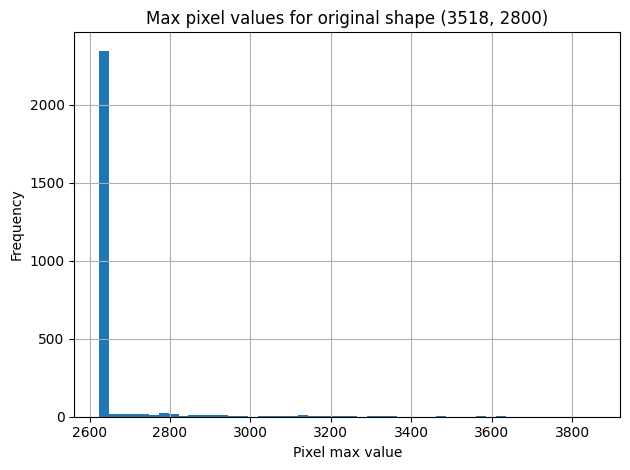

In [ ]:
from collections import defaultdict

def collect_max_pixel_histograms(info_dict):
    histograms = defaultdict(list)

    for (cc_id, mlo_id), (info_cc, info_mlo) in info_dict.items():
        for info in [info_cc, info_mlo]:
            shape = tuple(info['original_shape'])  # (H, W)
            max_val = info['original_max']
            histograms[shape].append(max_val)

    return histograms

import matplotlib.pyplot as plt

def plot_histograms(histograms):
    for shape, max_vals in histograms.items():
        plt.figure()
        plt.hist(max_vals, bins=50)
        plt.title(f"Max pixel values for original shape {shape}")
        plt.xlabel("Pixel max value")
        plt.ylabel("Frequency")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

histograms = collect_max_pixel_histograms(info_dict)
plot_histograms(histograms)

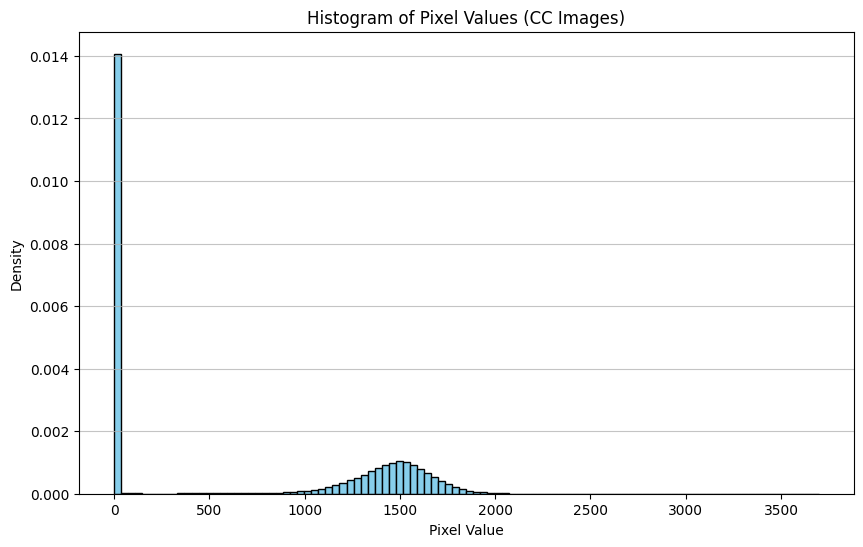

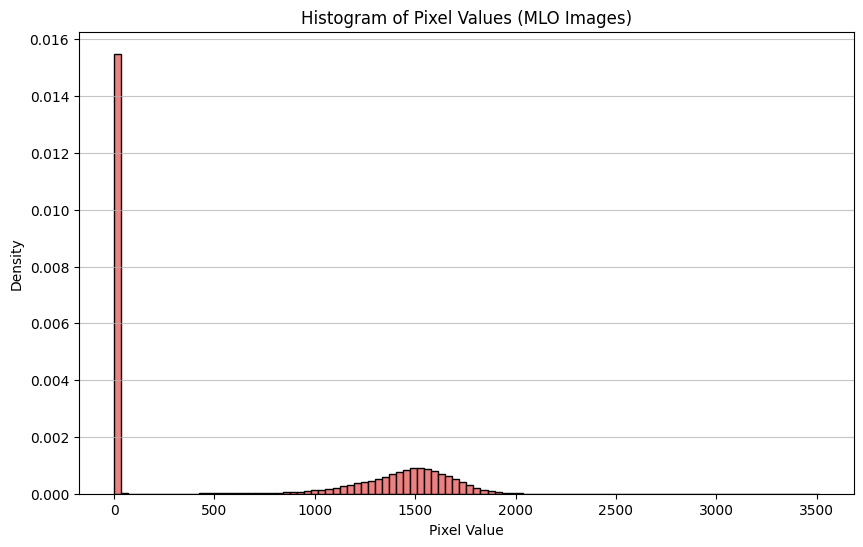

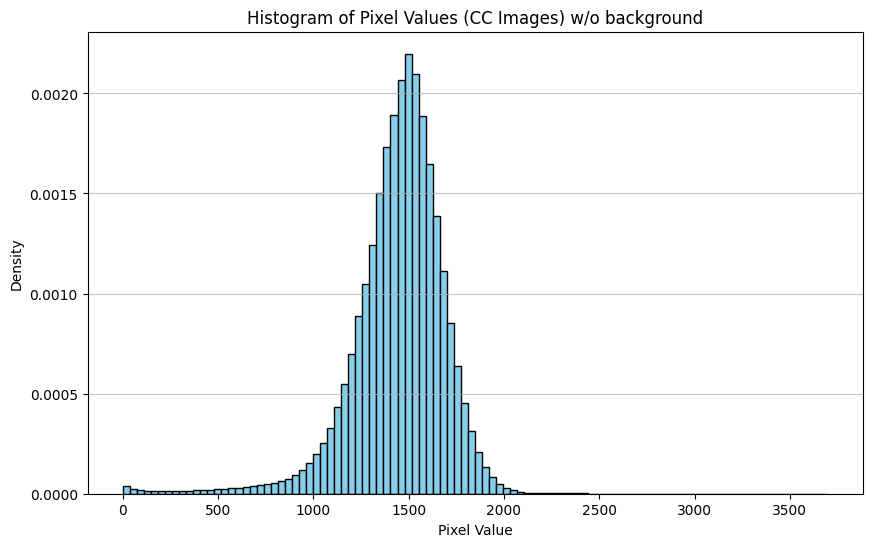

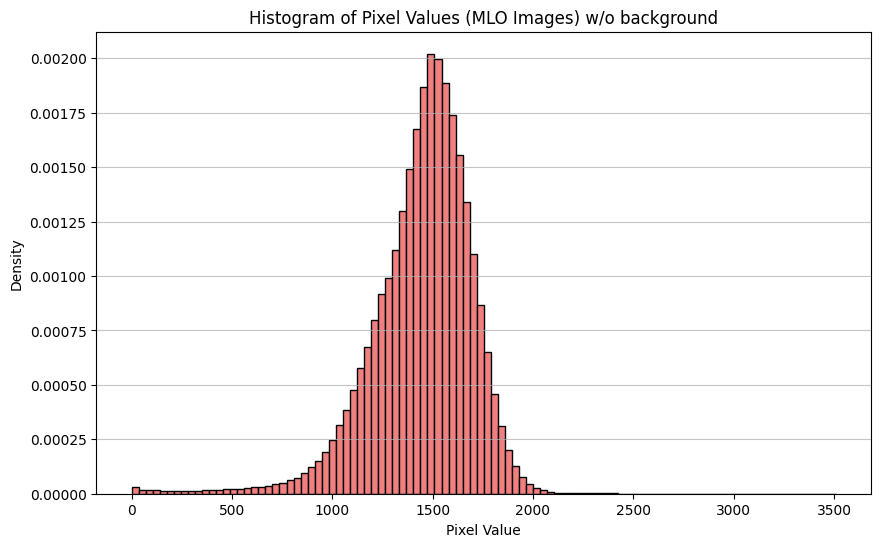

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_pixel_histograms_from_image_dict(image_dict, bins=100, remove_zero=True, density=True):
    """
    Plot histograms of pixel values from CC and MLO images in an image_dict.

    Args:
        image_dict (dict): {(cc_id, mlo_id): (cc_image, mlo_image)}
        bins (int): Number of bins for the histogram.
        remove_zero (bool): Whether to exclude background (zero) pixels.
        density (bool): Whether to normalize the histogram (density=True) or show counts.
    """
    cc_all_pixel_values = []
    mlo_all_pixel_values = []

    for (cc_id, mlo_id), (cc_image, mlo_image) in image_dict.items():
        cc_all_pixel_values.extend(cc_image.flatten())
        mlo_all_pixel_values.extend(mlo_image.flatten())

    cc_all_pixel_values = np.array(cc_all_pixel_values)
    mlo_all_pixel_values = np.array(mlo_all_pixel_values)


    # Plot CC histogram
    plt.figure(figsize=(10, 6))
    plt.hist(cc_all_pixel_values, bins=bins, density=density,
             color='skyblue', edgecolor='black')
    plt.title('Histogram of Pixel Values (CC Images)')
    plt.xlabel('Pixel Value')
    plt.ylabel('Density' if density else 'Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.show()

    # Plot MLO histogram
    plt.figure(figsize=(10, 6))
    plt.hist(mlo_all_pixel_values, bins=bins, density=density,
             color='lightcoral', edgecolor='black')
    plt.title('Histogram of Pixel Values (MLO Images)')
    plt.xlabel('Pixel Value')
    plt.ylabel('Density' if density else 'Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.show()

    if remove_zero:
        cc_all_pixel_values = cc_all_pixel_values[cc_all_pixel_values != 0]
        mlo_all_pixel_values = mlo_all_pixel_values[mlo_all_pixel_values != 0]

    # Plot CC histogram
    plt.figure(figsize=(10, 6))
    plt.hist(cc_all_pixel_values, bins=bins, density=density,
             color='skyblue', edgecolor='black')
    plt.title('Histogram of Pixel Values (CC Images) w/o background')
    plt.xlabel('Pixel Value')
    plt.ylabel('Density' if density else 'Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.show()

    # Plot MLO histogram
    plt.figure(figsize=(10, 6))
    plt.hist(mlo_all_pixel_values, bins=bins, density=density,
             color='lightcoral', edgecolor='black')
    plt.title('Histogram of Pixel Values (MLO Images) w/o background')
    plt.xlabel('Pixel Value')
    plt.ylabel('Density' if density else 'Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.show()

plot_pixel_histograms_from_image_dict(image_dict)

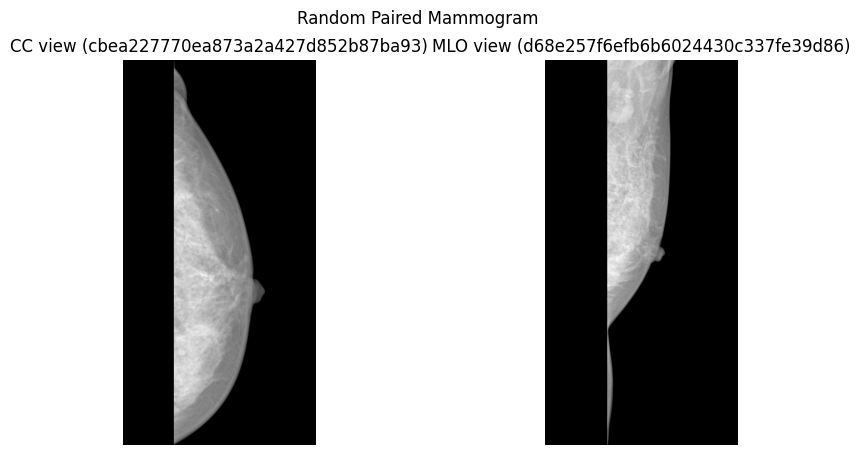

In [ ]:
import matplotlib.pyplot as plt
import random

# Pick a random key from the dict
random_key = random.choice(list(image_dict.keys()))
cc_id, mlo_id = random_key
cc_img, mlo_img = image_dict[random_key]

# Plot the images side-by-side
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cc_img, cmap='gray')
plt.title(f"CC view ({cc_id})")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mlo_img, cmap='gray')
plt.title(f"MLO view ({mlo_id})")
plt.axis('off')

plt.suptitle("Random Paired Mammogram")
plt.show()


# Datasets in pytorch

In [ ]:
from sklearn.model_selection import train_test_split

#for balanced dataset
#test_df = dataset[dataset['split'] == 'test'].reset_index(drop=True).drop(columns=['split'])

#for unbalanced dataset
at_risk = dataset[(dataset['split'] == 'test') & (dataset['binary_class'] == 1)].reset_index(drop=True)
test_df = pd.concat([at_risk, dataset[dataset['binary_class'] == 0].sample(n=len(at_risk), ignore_index = True).reset_index(drop=True)], axis=0).drop(columns=['split'])


train_df = dataset[dataset['split'] == 'training'].reset_index(drop=True).drop(columns=['split'])
val_df, test_df = train_test_split(test_df, test_size=0.5, stratify=test_df['binary_class'])

print(f"Dimensione totale del dataset: {len(dataset)}")
print(f"Dimensione del set di training: {len(train_df)}")
print(f"Dimensione del set di validation: {len(val_df)}")
print(f"Dimensione del set di test: {len(test_df)}")

print("\Distribuzione delle classi binarie nel training set:")
print(train_df['binary_class'].value_counts(normalize=True))

print("\nDistribuzione delle classi binarie nel validation set:")
print(val_df['binary_class'].value_counts(normalize=True))

print("\nDistribuzione delle classi binarie nel test set:")
print(test_df['binary_class'].value_counts(normalize=True))

display(train_df.head())
display(val_df.head())
display(test_df.head())

Dimensione totale del dataset: 1296
Dimensione del set di training: 1034
Dimensione del set di validation: 125
Dimensione del set di test: 125
\Distribuzione delle classi binarie nel training set:
binary_class
1.0    0.505803
0.0    0.494197
Name: proportion, dtype: float64

Distribuzione delle classi binarie nel validation set:
binary_class
0.0    0.504
1.0    0.496
Name: proportion, dtype: float64

Distribuzione delle classi binarie nel test set:
binary_class
1.0    0.504
0.0    0.496
Name: proportion, dtype: float64


,study_id,laterality,height,width,class,binary_class,density,CC,MLO
0,003700f3c960e0b9bca2b8437c3dbf05,L,3518.0,2800.0,4.0,1.0,C,51b47f9024ccad1356354f56ac916f29,3944b33b99c98e763763b9da54b4f41c
1,008b8e61390fcb4c0873258c15b0a53a,R,3518.0,2800.0,4.0,1.0,C,f1f79501410a98782c0a03b48e66df83,e13c80239d7714e3d964b5f3e37bcff6
2,00a369b4ec1e5e0ff34e6bd838e5f2d6,L,3518.0,2800.0,3.0,1.0,C,f3cbed97f4bb7897467e1e8bab45966e,2feab51140b38f9ec90e17b7006501b2
3,012e0595adba5173b6e60a97f9e84b6e,L,3518.0,2800.0,3.0,1.0,C,f6c7f3c3e03d612002800f20b1282309,edb7f6e44809405ec40a9c2537da62e6
4,012e0595adba5173b6e60a97f9e84b6e,R,3518.0,2800.0,3.0,1.0,C,202d1c29785f6327985ffda7100e2265,7adeb584564fc161d897a3fc719acd17


,study_id,laterality,height,width,class,binary_class,density,CC,MLO
46,4d100012e6e8bd1ce4ecee057eb5c118,L,3518.0,2800.0,1.0,0.0,C,dd65f3a938b26a398b7da90e16610c4c,76d80722e6c6bb330f4cb518e9900b36
99,5003d7a34c3a2cac23b9a881e5af642a,L,3518.0,2800.0,1.0,0.0,D,f8bd9329bf5a99b64598e5e6a72d53df,420742c859a1ddf1e00f88c7ebf542b9
11,3c0d66267d6fa130cf9440b90456e481,R,3518.0,2800.0,1.0,0.0,D,37d9111014b8528b01a81a8f6809aba1,7e3cbde7a75b862d819687e6bd52346c
89,948bf68244fa6c00dc9963dcd62cd14c,L,3518.0,2800.0,4.0,1.0,C,1513f5d691d471605b882f111d388d46,b6c7b7ecd66d7dba1fa601170b9b6ebf
44,b56e6049a2b9441ab9b06b6b81b7170d,L,3518.0,2800.0,2.0,0.0,D,9be186960040039d2265c301a29f8113,d0507762897bbdab0a027a0451b28476


,study_id,laterality,height,width,class,binary_class,density,CC,MLO
105,b57b97020df361371ae1877080433275,L,3518.0,2800.0,5.0,1.0,C,5fe8350c930a08ebc532cbb304f5642a,7a6c57ce6034053ca02a8cd32549db7f
63,73ddabe812dadcc6ece2c48a246f72f5,L,3518.0,2800.0,4.0,1.0,C,27a35305fa91c508fdb8dc2a7e7978ee,e8dfd88e396c4cc90611cd8b6a2278ac
6,0910d9262da2398810b2f2bc32b77088,L,3518.0,2800.0,3.0,1.0,C,eff50bb27749afa48947f9fcce83c929,c1bbd7498883deb078c151ee8ef2e3e2
93,a3efa110e27ffa4d5b2636e388a5c700,L,3518.0,2800.0,4.0,1.0,C,77f31b96295aff83e7a21df366da19b1,bef47f8667ef0dfb4f6deda2434da05d
74,805d72b89d7f73058bf420ef26caaff4,L,3518.0,2800.0,3.0,1.0,C,da5900a162abdc8ec0f535fbffa07f8f,219cc02d369ac35c640f01515fd18704


In [ ]:
import torch
from torch.utils.data import Dataset
import numpy as np
import matplotlib.pyplot as plt

class PairedImageDataset(Dataset):
    def __init__(self, dataframe, image_dict):
        """
        Args:
            dataframe (pd.DataFrame): Must contain 'CC', 'MLO', and 'binary_class' columns
            image_dict (dict): {(cc_id, mlo_id): (cc_image, mlo_image)}, each image is a NumPy array
        """
        self.df = dataframe.reset_index(drop=True)
        self.image_dict = image_dict
        self.missing = []
        self.data = self._load_all()  # Load all data once

        # Compute statistics per view
        self.cc_max, self.cc_mean, self.cc_std = self._compute_statistics(view="cc")
        self.mlo_max, self.mlo_mean, self.mlo_std = self._compute_statistics(view="mlo")

    def _load_all(self):
        data = []
        for idx in range(len(self.df)):
            row = self.df.iloc[idx]
            key = (row['CC'], row['MLO'])
            if key not in self.image_dict:
                print(f"Skipped image pair {key}: not found in image_dict.")
                self.missing.append(idx)
            else:
                cc_img, mlo_img = self.image_dict[key]
                label = row['binary_class']
                data.append((cc_img.astype(np.float32), mlo_img.astype(np.float32), label))
        return data

    def _compute_statistics(self, view="cc"):
        all_pixels = []
        for cc_img, mlo_img, _ in self.data:
            img = cc_img if view == "cc" else mlo_img
            img = img[img > 0]  # Exclude background
            all_pixels.append(img)
        all_pixels = np.concatenate(all_pixels)
        return all_pixels.max(), all_pixels.mean(), all_pixels.std()

    def get_flattened_pixels(self, view="cc"):
        """
        Return a flattened NumPy array of non-zero pixel values from either the CC or MLO view.
        """
        assert view in ["cc", "mlo", "both"], "view must be 'cc', 'mlo', or 'both'"
        all_pixels = []

        for cc_img, mlo_img, _ in self.data:
            if view in ["cc", "both"]:
                cc_pixels = cc_img[cc_img > 0].flatten()
                all_pixels.append(cc_pixels)
            if view in ["mlo", "both"]:
                mlo_pixels = mlo_img[mlo_img > 0].flatten()
                all_pixels.append(mlo_pixels)

        return np.concatenate(all_pixels) if all_pixels else np.array([])

    def plot_pixel_histogram(self, view="cc", bins=100):
        """
        Plot histogram of pixel values for the selected view.
        """
        pixels = self.get_flattened_pixels(view)
        if pixels.size == 0:
            print(f"No pixels found for view '{view}'.")
            return

        plt.figure(figsize=(8, 5))
        plt.hist(pixels, bins=bins, color='skyblue', edgecolor='black')
        plt.title(f"Pixel Value Histogram ({view.upper()})")
        plt.xlabel("Pixel Value")
        plt.ylabel("Frequency")
        plt.grid(True)
        plt.show()


    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        cc_img, mlo_img, label = self.data[idx]
        cc_tensor = torch.from_numpy(cc_img).unsqueeze(0)  # [1, H, W]
        mlo_tensor = torch.from_numpy(mlo_img).unsqueeze(0)
        label = torch.tensor(label, dtype=torch.float32).unsqueeze(0)
        return (cc_tensor, mlo_tensor), label


In [ ]:
train_dataset = PairedImageDataset(train_df, image_dict)
max_cc = train_dataset.cc_max
max_mlo = train_dataset.mlo_max
val_dataset   = PairedImageDataset(val_df, image_dict)
test_dataset  = PairedImageDataset(test_df, image_dict)
print('cc max: ', max_cc, 'mlo max: ', max_mlo)
print()
print('train dataset length: ', train_dataset.__len__())
print('vali dataset length: ', val_dataset.__len__())
print('test dataset length: ', test_dataset.__len__())

cc max:  3455.5027 mlo max:  3510.2402

train dataset length:  1034
vali dataset length:  125
test dataset length:  125


In [ ]:
 import matplotlib.pyplot as plt
 def plot_pixel_histograms_from_datasets(train_dataset, val_dataset, test_dataset):
     """
     Plots pixel value histograms for CC and MLO views from the entire dataset
     using the get_flattened_pixels() method of each dataset.
     """
     # Get flattened pixel arrays
     train_cc = train_dataset.get_flattened_pixels(view="cc")
     train_mlo = train_dataset.get_flattened_pixels(view="mlo")
     val_cc = val_dataset.get_flattened_pixels(view="cc")
     val_mlo = val_dataset.get_flattened_pixels(view="mlo")
     test_cc = test_dataset.get_flattened_pixels(view="cc")
     test_mlo = test_dataset.get_flattened_pixels(view="mlo")
     # Plot
     plt.figure(figsize=(12, 10))
     plt.subplot(3, 2, 1)
     plt.hist(train_cc, bins=100, density=True, color='skyblue', edgecolor='black')
     plt.title("Train - CC View")
     plt.xlabel("Pixel Value")
     plt.ylabel("Density")
     plt.grid(True)
     plt.subplot(3, 2, 2)
     plt.hist(train_mlo, bins=100, density=True, color='salmon', edgecolor='black')
     plt.title("Train - MLO View")
     plt.xlabel("Pixel Value")
     plt.ylabel("Density")
     plt.grid(True)
     plt.subplot(3, 2, 3)
     plt.hist(val_cc, bins=100, density=True, color='skyblue', edgecolor='black')
     plt.title("Validation - CC View")
     plt.xlabel("Pixel Value")
     plt.ylabel("Density")
     plt.grid(True)
     plt.subplot(3, 2, 4)
     plt.hist(val_mlo, bins=100, density=True, color='salmon', edgecolor='black')
     plt.title("Validation - MLO View")
     plt.xlabel("Pixel Value")
     plt.ylabel("Density")
     plt.grid(True)
     plt.subplot(3, 2, 5)
     plt.hist(test_cc, bins=100, density=True, color='skyblue', edgecolor='black')
     plt.title("Test - CC View")
     plt.xlabel("Pixel Value")
     plt.ylabel("Density")
     plt.grid(True)
     plt.subplot(3, 2, 6)
     plt.hist(test_mlo, bins=100, density=True, color='salmon', edgecolor='black')
     plt.title("Test - MLO View")
     plt.xlabel("Pixel Value")
     plt.ylabel("Density")
     plt.grid(True)
     plt.tight_layout()
     plt.show()

# plot_pixel_histograms_from_datasets(train_dataset, val_dataset, test_dataset)

In [ ]:
from torch.utils.data import DataLoader
import torchvision.transforms.v2 as v2
import torch
from torch.utils.data import WeightedRandomSampler
import numpy as np

batch_size = 16
oversampled_len = 1 #Default: 1. Higher values make the dataset 'bigger' but minority class images will be shown more times

# EfficientNet standard normalization
effnet_mean = [0.485, 0.456, 0.406]
effnet_std = [0.229, 0.224, 0.225]

# 1. Augmentation + normalization for training
train_transform = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomRotation(degrees=10),
    v2.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=effnet_mean, std=effnet_std)
])


# 2. Normalization only for validation/test
eval_transform = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=effnet_mean, std=effnet_std)
])


# 3. Collate function with clamping and normalization by max_value
def make_collate_with_transform(transform, max_value):
    def collate_fn(batch):
        cc_batch, mlo_batch, labels = [], [], []
        for (cc, mlo), label in batch:
            # Clamp and normalize
            cc = np.clip(cc, 0, max_value) / max_value
            mlo = np.clip(mlo, 0, max_value) / max_value
            # Expand to 3 channels
            cc = cc.expand(3, -1, -1)
            mlo = mlo.expand(3, -1, -1)
            cc_batch.append(cc)
            mlo_batch.append(mlo)
            labels.append(label)
        cc_batch = transform(torch.stack(cc_batch))
        mlo_batch = transform(torch.stack(mlo_batch))
        labels = torch.stack(labels)
        return (cc_batch, mlo_batch), labels
    return collate_fn

# Set your global max value for normalization
train_pixel_max = max(train_dataset.cc_max, train_dataset.mlo_max)

# Wrap collate functions
train_collate_fn = make_collate_with_transform(train_transform, train_pixel_max)
eval_collate_fn = make_collate_with_transform(eval_transform, train_pixel_max)


# 4. Weighted Random Sampler
train_labels = [label for (_, _, label) in train_dataset.data]

# Count number of each class and assign weight to each sample
class_counts = np.bincount(train_labels)  # [num_zeros, num_ones]
class_weights = 1. / class_counts         # inverse frequency
sample_weights = [class_weights[int(label)] for label in train_labels]

# Create sampler
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=int(len(train_dataset) * oversampled_len),  # Increase this for more samples per epoch (minority class sample will be shown multiple times)
    replacement=True
)


# 5. DataLoaders

## TRAIN LOADER WITH RANDOM SAMPLER FOR OVERSAMPLING
#train_loader = DataLoader(
#    train_dataset,
#    batch_size=batch_size,
#    sampler=sampler,
#    drop_last=True,
#    collate_fn=eval_collate_fn #CHANGE TO ADD/REMOVE AUGMENTATION (train: augmentation, eval: no augmentation)
#    #num_workers=8,
#    #prefetch_factor=2,  # default
#    #pin_memory=True
#)


# TRAIN LOADER WITHOUT RANDOM SAMPLER
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True,
    collate_fn=eval_collate_fn, #CHANGE TO ADD/REMOVE AUGMENTATION
    #num_workers=4,
    #prefetch_factor=1,  # default
    #pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    drop_last=False,
    collate_fn=eval_collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    drop_last=False,
    collate_fn=eval_collate_fn
)


print(len(train_loader), len(val_loader), len(test_loader))

64 8 8


In [ ]:
def unnormalize(img_tensor, mean, std):
    """
    Unnormalize a tensor image given mean and std (can be scalar or list per channel).
    """
    mean = torch.tensor(mean).view(-1, 1, 1)
    std = torch.tensor(std).view(-1, 1, 1)
    return img_tensor * std + mean

def show_paired_batch(dataloader, n=4, mean=0.5, std=0.5):
    """
    Show n samples from a DataLoader that returns (img1, img2), label.
    Unnormalizes before plotting.
    """
    (img1_batch, img2_batch), label_batch = next(iter(dataloader))
    n = min(n, img1_batch.size(0))

    fig, axs = plt.subplots(n, 2, figsize=(6, 3 * n))

    for i in range(n):
        for j, img_tensor in enumerate([img1_batch[i], img2_batch[i]]):
            img = img_tensor.detach().cpu()
            img = unnormalize(img, mean, std).clamp(0, 1)  # unnormalize and clip

            if img.shape[0] == 1:
                img = img.squeeze(0)
                cmap = 'gray'
            else:
                img = img.permute(1, 2, 0)
                cmap = None

            axs[i, j].imshow(img.numpy(), cmap=cmap)
            axs[i, j].axis('off')

        label = label_batch[i].item() if isinstance(label_batch[i], torch.Tensor) else label_batch[i]
        axs[i, 0].set_title(f"CC View - Label: {label}")
        axs[i, 1].set_title(f"MLO View - Label: {label}")

    plt.tight_layout()
    plt.show()


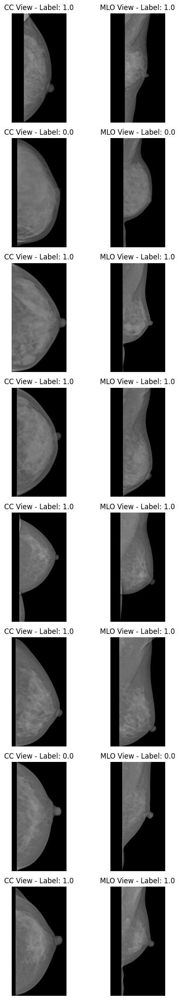

In [ ]:
show_paired_batch(train_loader, n=8, mean=effnet_mean, std=effnet_std)


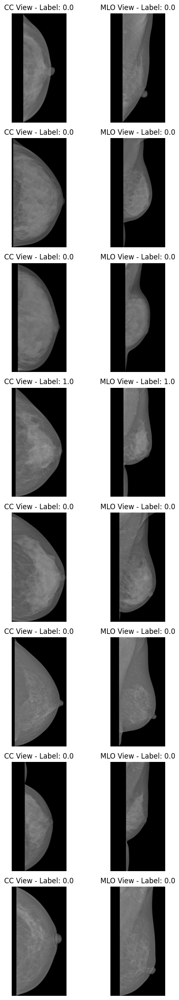

In [ ]:
show_paired_batch(val_loader, n=8, mean=effnet_mean, std=effnet_std)

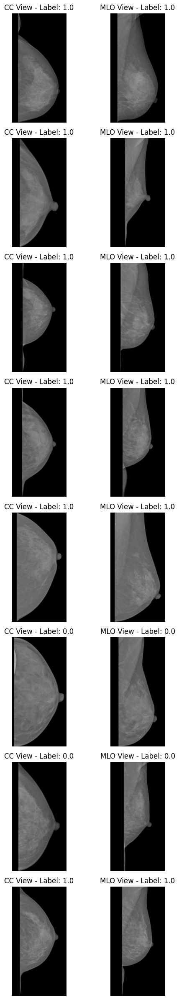

In [ ]:
show_paired_batch(test_loader, n=8, mean=effnet_mean, std=effnet_std)

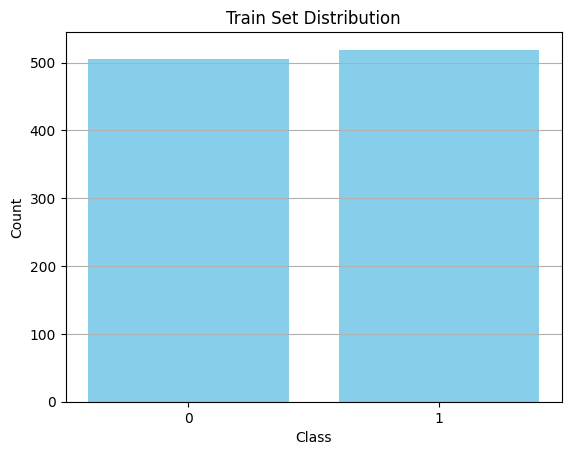

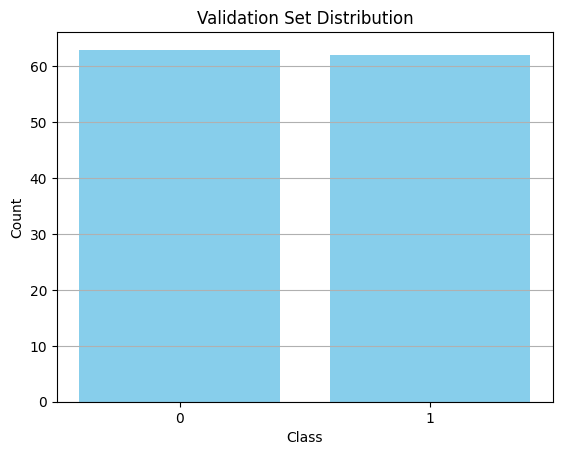

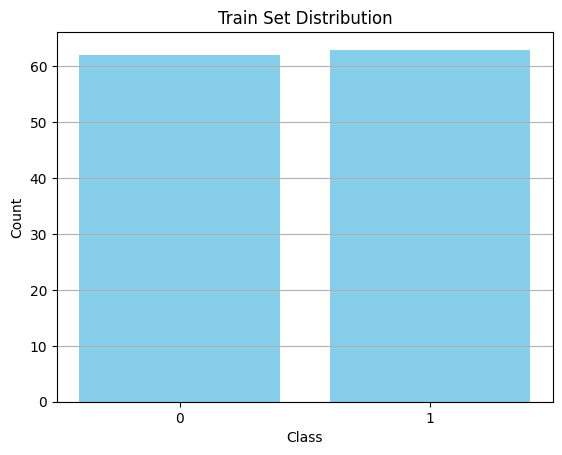

In [ ]:
import torch
from collections import Counter
import matplotlib.pyplot as plt

def plot_class_distribution_from_loader(loader, label_names=None, title="Class Distribution"):
    all_labels = []

    for _, labels in loader:
        if isinstance(labels, torch.Tensor):
            labels = labels.view(-1).cpu().numpy()
        else:
            labels = [l.item() for l in labels]
        all_labels.extend(labels)

    counts = Counter(all_labels)
    classes = sorted(counts.keys())
    values = [counts[c] for c in classes]

    class_names = [label_names.get(c, str(c)) for c in classes] if label_names else [str(c) for c in classes]

    plt.bar(class_names, values, color='skyblue')
    plt.title(title)
    plt.xlabel("Class")
    plt.ylabel("Count")
    plt.grid(True, axis='y')
    plt.show()

# Example usage:
label_map = {0: '0', 1: '1'}
plot_class_distribution_from_loader(train_loader, label_map, "Train Set Distribution")
plot_class_distribution_from_loader(val_loader, label_map, "Validation Set Distribution")
plot_class_distribution_from_loader(test_loader, label_map, "Train Set Distribution")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def get_all_channels_filtered(dataloader, view="cc", only_first_batch=True):
    """
    Extracts per-channel non-background pixel values from the first batch of a dataloader.

    Args:
        dataloader (DataLoader): PyTorch dataloader
        view (str): 'cc' or 'mlo'

    Returns:
        List of 3 arrays, one per RGB channel
    """
    channel_values = [[], [], []]
    for (cc_batch, mlo_batch), _ in dataloader:
        batch = cc_batch if view == "cc" else mlo_batch
        for ch in range(3):
            data = batch[:, ch, :, :]
            flat = data.flatten().numpy()
            filtered = flat[flat > flat.min()]  # Remove background
            channel_values[ch].append(filtered)
        if only_first_batch:
            break  # Only first batch
    return [np.concatenate(c) for c in channel_values]

def plot_overlay_histograms(data, title, subplot_idx):
    channel_colors = ['red', 'green', 'blue']
    channel_labels = ['Channel 0 (R)', 'Channel 1 (G)', 'Channel 2 (B)']
    plt.subplot(3, 2, subplot_idx)
    for i in range(3):
        plt.hist(data[i], bins=100, color=channel_colors[i],
                 label=channel_labels[i], density=True, alpha=0.5, edgecolor='black')
    plt.title(title)
    plt.xlabel("Pixel Value")
    plt.ylabel("Density")
    plt.grid(True)
    plt.legend()

def plot_rgb_channel_histograms_from_loaders(train_loader, val_loader, test_loader, only_first_batch=True):
    """
    Plots overlaid RGB histograms from CC and MLO views of the first batch in each loader.

    Args:
        train_loader, val_loader, test_loader: PyTorch DataLoaders
    """
    train_cc_ch = get_all_channels_filtered(train_loader, "cc", only_first_batch)
    train_mlo_ch = get_all_channels_filtered(train_loader, "mlo", only_first_batch)
    val_cc_ch = get_all_channels_filtered(val_loader, "cc", only_first_batch)
    val_mlo_ch = get_all_channels_filtered(val_loader, "mlo", only_first_batch)
    test_cc_ch = get_all_channels_filtered(test_loader, "cc", only_first_batch)
    test_mlo_ch = get_all_channels_filtered(test_loader, "mlo", only_first_batch)

    plt.figure(figsize=(12, 12))
    plot_overlay_histograms(train_cc_ch, "Train - CC View", 1)
    plot_overlay_histograms(train_mlo_ch, "Train - MLO View", 2)
    plot_overlay_histograms(val_cc_ch, "Validation - CC View", 3)
    plot_overlay_histograms(val_mlo_ch, "Validation - MLO View", 4)
    plot_overlay_histograms(test_cc_ch, "Test - CC View", 5)
    plot_overlay_histograms(test_mlo_ch, "Test - MLO View", 6)
    plt.tight_layout()
    plt.show()

print("First batch for train/val/test")
#plot_rgb_channel_histograms_from_loaders(train_loader, val_loader, test_loader) # show histogram only for first batch
#plot_rgb_channel_histograms_from_loaders(train_loader, val_loader, test_loader, only_first_batch = False) # show all normalized dataset

First batch for train/val/test


# MODEL

In [ ]:
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torchvision.models import densenet121, DenseNet121_Weights
from torchvision.models import vgg19_bn, VGG19_BN_Weights
from torchinfo import summary
import torch

model1 = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
#model2 = densenet121(weights=DenseNet121_Weights.DEFAULT)
model2 = vgg19_bn(weights=VGG19_BN_Weights.DEFAULT)

print(summary(model1, input_size=(1, 3, resized_shape[0], resized_shape[1]), device="cpu"))
print(summary(model2, input_size=(1, 3, resized_shape[0], resized_shape[1]), device="cpu"))

Layer (type:depth-idx)                                  Output Shape              Param #
EfficientNet                                            [1, 1000]                 --
├─Sequential: 1-1                                       [1, 1280, 32, 16]         --
│    └─Conv2dNormActivation: 2-1                        [1, 32, 512, 256]         --
│    │    └─Conv2d: 3-1                                 [1, 32, 512, 256]         864
│    │    └─BatchNorm2d: 3-2                            [1, 32, 512, 256]         64
│    │    └─SiLU: 3-3                                   [1, 32, 512, 256]         --
│    └─Sequential: 2-2                                  [1, 16, 512, 256]         --
│    │    └─MBConv: 3-4                                 [1, 16, 512, 256]         1,448
│    └─Sequential: 2-3                                  [1, 24, 256, 128]         --
│    │    └─MBConv: 3-5                                 [1, 24, 256, 128]         6,004
│    │    └─MBConv: 3-6                              

In [ ]:
for name, module in model1.named_children():
    print(name)

print()
for name, module in model1.named_children():
    print(name, module)

features
avgpool
classifier

features Sequential(
  (0): Conv2dNormActivation(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): SiLU(inplace=True)
  )
  (1): Sequential(
    (0): MBConv(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): SiLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (activation): SiLU(inplace=True)
          (scale_activation): Sigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(32, 1

In [ ]:
for name, module in model2.named_children():
    print(name)

print()
for name, module in model2.named_children():
    print(name, module)

features
avgpool
classifier

features Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (5): ReLU(inplace=True)
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (9): ReLU(inplace=True)
  (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (12): ReLU(inplace=True)
  (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (14): Conv2d(128, 256, kernel_si

In [ ]:
print(list(model1.features.children())[:2])
print()
print(list(model1.features.children())[-2:])

[Conv2dNormActivation(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
), Sequential(
  (0): MBConv(
    (block): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): SqueezeExcitation(
        (avgpool): AdaptiveAvgPool2d(output_size=1)
        (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
        (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
        (activation): SiLU(inplace=True)
        (scale_activation): Sigmoid()
      )
      (2): Conv2dNormActivation(
        (0): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1

In [ ]:
print(list(model1.features)[:2])
print(list(model1.features)[-2:])

[Conv2dNormActivation(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
), Sequential(
  (0): MBConv(
    (block): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): SqueezeExcitation(
        (avgpool): AdaptiveAvgPool2d(output_size=1)
        (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
        (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
        (activation): SiLU(inplace=True)
        (scale_activation): Sigmoid()
      )
      (2): Conv2dNormActivation(
        (0): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1

In [ ]:
print(list(model2.features.children())[:2])
print()
print(list(model2.features.children())[-2:])

[Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)), BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)]

[ReLU(inplace=True), MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)]


In [ ]:
del model1
del model2

In [ ]:
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torchvision.models import densenet121, DenseNet121_Weights
from torchvision.models import vgg19_bn, VGG19_BN_Weights


class CustomPooling(nn.Module):
    def __init__(self):
        super().__init__()
        self._dropblock = nn.Dropout2d(p=0.3)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.maxpool = nn.AdaptiveMaxPool2d(1)

    def forward(self, x):
        #x = self._dropblock(x)
        return self.maxpool(x) # + self.avgpool(x)

class DualEfficientNetWithGradCAM(nn.Module):
    def __init__(self, backbone = 'efficientNet', same_branch=False, freeze=True, unfreeze_first=0, unfreeze_last=0):
        super().__init__()

        # Load torchvision backbones
        if same_branch:
            self.cc_backbone = self._get_backbone(backbone, freeze, unfreeze_first, unfreeze_last)
            self.mlo_backbone = self.cc_backbone
        else:
            self.cc_backbone = self._get_backbone(backbone, freeze, unfreeze_first, unfreeze_last)
            self.mlo_backbone = self._get_backbone(backbone, freeze, unfreeze_first, unfreeze_last)

        #if backbone == 'efficientNet':
        #    # Change last pooling from average to max
        #    self.cc_backbone.avgpool = CustomPooling()
        #    self.mlo_backbone.avgpool = CustomPooling()

        # Register Grad-CAM hooks
        self.cc_activation = None
        self.mlo_activation = None
        self._register_gradcam_hooks()

        sizes = {
            'efficientNet': 1280,
            'denseNet':     1024,
            'VGG19':        512 ,
        }
        flattened_size = sizes[backbone]

        # Custom classifier head
        self.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(flattened_size * 2, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(0.3),
            #nn.Dropout(0.2),
            nn.Linear(256, 1),  # No sigmoid for BCEWithLogitsLoss
        )

    def _freeze_all(self, backbone):
        for p in backbone.parameters():
            p.requires_grad = False

    def _unfreeze_tail(self, backbone, n_blocks):
        blocks = list(backbone.features.children())
        if n_blocks > 0:
            for block in blocks[-n_blocks:]:
                for p in block.parameters():
                    p.requires_grad = True

    def _unfreeze_first(self, backbone, n_blocks):
        blocks = list(backbone.features.children())
        if n_blocks > 0:
            for block in blocks[:n_blocks]:
                for p in block.parameters():
                    p.requires_grad = True

    def _get_backbone(self, model = 'efficientNet', freeze=True, unfreeze_first=0, unfreeze_last=0):
        if model == 'denseNet':
            backbone = densenet121(weights=DenseNet121_Weights.DEFAULT)

        if model == 'efficientNet':
            backbone = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)

        if model == 'VGG19':
            backbone = vgg19_bn(weights=VGG19_BN_Weights.DEFAULT)

        # Remove classifier
        backbone.classifier = nn.Identity()

        backbone.avgpool = nn.AdaptiveAvgPool2d(1)

        if freeze:
            self._freeze_all(backbone)
            self._unfreeze_tail(backbone, unfreeze_last)
            self._unfreeze_first(backbone, unfreeze_first)

        return backbone

    def change_frozen(self, freeze=True, unfreeze_first=0, unfreeze_last=0):
        if same_branch:
            backbone = self.cc_backbone
            for p in backbone.parameters():
                p.requires_grad = True
            if freeze:
                self._freeze_all(backbone)
                self._unfreeze_tail(backbone, unfreeze_last)
                self._unfreeze_first(backbone, unfreeze_first)
        else:
            for backbone in [self.cc_backbone, self.mlo_backbone]:
                for p in backbone.parameters():
                    p.requires_grad = True
                if freeze:
                    self._freeze_all(backbone)
                    self._unfreeze_tail(backbone, unfreeze_last)
                    self._unfreeze_first(backbone, unfreeze_first)



    def forward(self, cc_input, mlo_input):
        cc_feat = self.cc_backbone(cc_input)  # [B, 1280]
        mlo_feat = self.mlo_backbone(mlo_input)
        combined = torch.cat([cc_feat, mlo_feat], dim=1)  # [B, 2560]
        return self.classifier(combined)


    def _register_gradcam_hooks(self):
        def save_cc(module, input, output):
            self.cc_activation = output
            output.requires_grad_()
            output.retain_grad()

        def save_mlo(module, input, output):
            self.mlo_activation = output
            output.requires_grad_()
            output.retain_grad()

        self.cc_backbone.features[-1].register_forward_hook(save_cc)
        self.mlo_backbone.features[-1].register_forward_hook(save_mlo)

    def extract_cc_activation(self):
        return self.cc_activation

    def extract_mlo_activation(self):
        return self.mlo_activation

    def get_target_layer(self, view='cc'):
        if view == 'cc':
            return self.cc_backbone.features[-1]
        elif view == 'mlo':
            return self.mlo_backbone.features[-1]
        else:
            raise ValueError("view must be 'cc' or 'mlo'")

    def forward_for_cam(self, x, view='cc'):
        dummy = torch.zeros_like(x)
        if view == 'cc':
            features = self.cc_backbone(x)
            other_features = self.mlo_backbone(dummy)
        elif view == 'mlo':
            features = self.mlo_backbone(x)
            other_features = self.cc_backbone(dummy)
        else:
            raise ValueError("view must be 'cc' or 'mlo'")

        combined = torch.cat([features, other_features], dim=1)
        output = self.classifier(combined)
        return output


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class DualCNNGradCAM(nn.Module):
    def __init__(self):
        super().__init__()

        def make_branch():
            layers = nn.Sequential(
                nn.Conv2d(3, 16, kernel_size=7, stride=1, padding=2),  # [3,1024,512] -> [16,1024,512]
                nn.BatchNorm2d(16),
                nn.ReLU(),
                nn.MaxPool2d(2),  # -> [16,512,256]

                nn.Conv2d(16, 32, kernel_size=5, stride=1, padding=1),
                nn.BatchNorm2d(32),
                nn.ReLU(),
                nn.MaxPool2d(2),  # -> [32,256,128]

                nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(64),
                nn.ReLU(),
                nn.MaxPool2d(2),  # -> [64,128,64]

                nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(128),
                nn.ReLU(),
                nn.MaxPool2d(2),  # -> [128,64,32]

                nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(256),
                nn.ReLU(),
                nn.MaxPool2d(2),  # -> [256,32,16]

                nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(512),
                nn.ReLU(),
                nn.AdaptiveAvgPool2d(4,4)  # -> [512,4,4]
            )
            return layers

        self.cc_branch = make_branch()
        self.mlo_branch = make_branch()

        self.cc_activation = None
        self.mlo_activation = None
        self._register_gradcam_hooks()

        self.classifier = nn.Sequential(
            nn.Linear(512 * 2 * 16, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Linear(64, 1)  # no sigmoid
        )

    def _register_gradcam_hooks(self):
        def save_cc(module, input, output):
            self.cc_activation = output
            output.requires_grad_()
            output.retain_grad()

        def save_mlo(module, input, output):
            self.mlo_activation = output
            output.requires_grad_()
            output.retain_grad()

        self.cc_branch[-3].register_forward_hook(save_cc)  # second last conv
        self.mlo_branch[-3].register_forward_hook(save_mlo)

    def extract_cc_activation(self):
        return self.cc_activation

    def extract_mlo_activation(self):
        return self.mlo_activation

    def forward(self, cc_input, mlo_input):
        cc_feat = self.cc_branch(cc_input).view(cc_input.size(0), -1)
        mlo_feat = self.mlo_branch(mlo_input).view(mlo_input.size(0), -1)
        combined = torch.cat([cc_feat, mlo_feat], dim=1)
        return self.classifier(combined)


In [ ]:
#Checkpoint per salvare il modello durante il training (solo il best model)
class SaveBestModel:
    def __init__(self, best_valid_loss=float('inf'), path='best_model.pt', verbose=True):
        self.best_valid_loss = best_valid_loss
        self.path = path
        self.verbose = verbose

    def __call__(self, current_valid_loss, epoch, model, optimizer, metric_value):
        if current_valid_loss < self.best_valid_loss:
            self.best_valid_loss = current_valid_loss
            if self.verbose:
                print(f"\nNew best validation loss: {self.best_valid_loss:.4f}")
                print(f"Saving best model from epoch {epoch + 1}\n")
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'valid_loss': current_valid_loss,
                'valid_metric': metric_value,
            }, self.path)

#Early Stopper based on validation loss
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0, verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.best_loss = None
        self.counter = 0
        self.early_stop = False

    def __call__(self, current_loss):
        if self.best_loss is None or current_loss < self.best_loss - self.min_delta:
            self.best_loss = current_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.verbose:
                print(f"EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True


In [ ]:
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay

def evaluate_and_test_model(model, test_loader, loss_func, metric_func, device):
    model.eval()
    test_loss = 0.0
    test_metric = 0.0
    counter = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            counter += 1
            inputs = (inputs[0].to(device), inputs[1].to(device))  # CC and MLO
            labels = labels.to(device).float()

            outputs = model(*inputs)

            # Metrics
            loss = loss_func(outputs, labels)
            acc = metric_func(outputs, labels)

            test_loss += loss.item()
            test_metric += acc.item()

            all_preds.append(outputs.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    test_loss /= counter
    test_metric /= counter

    print(f"\n🧪 Test Loss: {test_loss:.4f} | Test Accuracy: {test_metric:.4f}")

    # Flatten predictions and labels
    y_true = np.concatenate(all_labels)
    y_scores = np.concatenate(all_preds)

    # ROC Curve and AUC
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
    plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Confusion Matrix at threshold 0.5
    y_pred_binary = (y_scores >= 0.5).astype(int)
    cm = confusion_matrix(y_true, y_pred_binary)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
    disp.plot(cmap=plt.cm.Blues)
    plt.title("Confusion Matrix (Threshold = 0.5)")
    plt.tight_layout()
    plt.show()

    return test_loss, test_metric, roc_auc, cm


In [ ]:
import torch
import time
import matplotlib.pyplot as plt

def train_binary_classifier(
    model,
    dataloaders,
    loss_func,
    metric_func,
    opt,
    scheduler,
    save_best_model,
    early_stopper= None,
    num_epochs=50,
    batch_size=16,
    device=None,
    show_plot=True
):

    hist_loss = []
    hist_metric = []
    hist_vloss = []
    hist_vmetric = []

    for epoch in range(num_epochs):
        t0 = time.time()
        model.train()
        train_loss = 0
        train_metric = 0
        counter = 0

        for inputs, labels in dataloaders['train']:
            counter += 1
            inputs = tuple(t.to(device) for t in inputs)
            labels = labels.to(device).float()

            preds = model(*inputs)
            #print(f"Preds shape: {preds.shape}, Labels shape: {labels.shape}")

            loss = loss_func(preds, labels)
            metric = metric_func(preds, labels)

            train_loss += loss.item()
            train_metric += metric.item()

            opt.zero_grad()
            loss.backward()
            opt.step()

        train_loss /= counter
        train_metric /= counter
        hist_loss.append(train_loss)
        hist_metric.append(train_metric)

        model.eval()
        vali_loss = 0
        vali_metric = 0
        counter = 0

        with torch.no_grad():
            for inputs, labels in dataloaders['vali']:
                counter += 1
                inputs = tuple(t.to(device) for t in inputs)
                labels = labels.to(device).float()

                preds = model(*inputs)
                vloss = loss_func(preds, labels)
                vmetric = metric_func(preds, labels)

                vali_loss += vloss.item()
                vali_metric += vmetric.item()

        vali_loss /= counter
        vali_metric /= counter
        hist_vloss.append(vali_loss)
        hist_vmetric.append(vali_metric)

        scheduler.step()
        save_best_model(vali_loss, epoch, model, opt, vali_metric)


        print(f"Epoch: {epoch+1} | Time: {time.time()-t0:.2f}s | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {vali_loss:.4f} | "
              f"Train Acc: {train_metric:.4f} | Val Acc: {vali_metric:.4f}")

        if (epoch > 15) and (early_stopper):
            early_stopper(vali_loss)
            if early_stopper.early_stop:
                print("⛔ Early stopping triggered.")
                break

    if show_plot:
        plt.figure(figsize=(20, 10))
        plt.subplot(1, 2, 1)
        plt.plot(hist_loss, label='Train Loss', color='crimson')
        plt.plot(hist_vloss, label='Val Loss', color='royalblue')
        plt.xlabel('Epochs')
        plt.ylabel('Binary Cross Entropy Loss')
        plt.title('Loss per Epoch')
        plt.legend()

        plt.subplot(1, 2, 2)
        plt.plot(hist_metric, label='Train Acc', color='crimson')
        plt.plot(hist_vmetric, label='Val Acc', color='royalblue')
        plt.xlabel('Epochs')
        plt.ylabel('Binary Accuracy')
        plt.title('Accuracy per Epoch')
        plt.legend()
        plt.show()

    return model, hist_loss, hist_metric, hist_vloss, hist_vmetric

In [ ]:
import torch
import torch.nn as nn
from torchinfo import summary
import gc

try:
    del model
except NameError:
    pass  # model was never defined
gc.collect()
torch.cuda.empty_cache()

#net = 'denseNet'
net = 'efficientNet'
#net = 'VGG19'

model = DualEfficientNetWithGradCAM(backbone = net, same_branch=False, freeze = True, unfreeze_first=0, unfreeze_last = 1)
#model = DualCNNGradCAM()

# Controlliamo se la GPU è disponibile e nel caso quale tipo di GPU
if torch.cuda.is_available():
    print('Numero di GPU disponibili:', torch.cuda.device_count())
    for i in range(torch.cuda.device_count()):
        print(torch.cuda.get_device_name(i))

# Se la GPU è disponibile setto device='cuda', altrimenti 'cpu'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Computation device: {device}\n")
# controlla vram occupata
if device == 'cuda':
    free, total = torch.cuda.mem_get_info(device + ':0')
    mem_used_MB = (total - free) / 1024 ** 2
    print('VRAM used: ', mem_used_MB, 'MB')

model = model.to(device)

# Optimizer and scheduler
opt = torch.optim.Adam([
    {'params': model.cc_backbone.parameters(), 'lr': 1e-5},
    {'params': model.mlo_backbone.parameters(), 'lr': 1e-5},
    {'params': model.classifier.parameters(), 'lr': 1e-3}
], weight_decay=1e-3)
#opt = torch.optim.Adam(model.parameters(), lr=4e-3, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.StepLR(opt, step_size=10, gamma=0.1)

# binary cross entropy loss
loss_func = nn.BCEWithLogitsLoss()

# Metric function
def binary_accuracy(outputs, labels):
    preds = torch.sigmoid(outputs) >= 0.5  # outputs are logits -> sigmoid probabilities
    return (preds.float() == labels).float().mean()

save_best_model = SaveBestModel()
early_stopper = EarlyStopping(patience=10, min_delta=0.001)

summary(model, input_size=[(1, 3, resized_shape[0], resized_shape[1]), (1, 3, resized_shape[0], resized_shape[1])])

Numero di GPU disponibili: 1
NVIDIA A100-SXM-64GB
Computation device: cuda

VRAM used:  482.75 MB


Layer (type:depth-idx)                                       Output Shape              Param #
DualEfficientNetWithGradCAM                                  [1, 1]                    --
├─EfficientNet: 1-1                                          [1, 1280]                 --
│    └─Sequential: 2-1                                       [1, 1280, 32, 16]         --
│    │    └─Conv2dNormActivation: 3-1                        [1, 32, 512, 256]         (928)
│    │    └─Sequential: 3-2                                  [1, 16, 512, 256]         (1,448)
│    │    └─Sequential: 3-3                                  [1, 24, 256, 128]         (16,714)
│    │    └─Sequential: 3-4                                  [1, 40, 128, 64]          (46,640)
│    │    └─Sequential: 3-5                                  [1, 80, 64, 32]           (242,930)
│    │    └─Sequential: 3-6                                  [1, 112, 64, 32]          (543,148)
│    │    └─Sequential: 3-7                                  


New best validation loss: 0.6617
Saving best model from epoch 1

Epoch: 1 | Time: 12.09s | Train Loss: 0.7300 | Val Loss: 0.6617 | Train Acc: 0.5723 | Val Acc: 0.5745

New best validation loss: 0.6290
Saving best model from epoch 2

Epoch: 2 | Time: 11.52s | Train Loss: 0.6444 | Val Loss: 0.6290 | Train Acc: 0.6387 | Val Acc: 0.6785

New best validation loss: 0.6042
Saving best model from epoch 3

Epoch: 3 | Time: 11.52s | Train Loss: 0.6415 | Val Loss: 0.6042 | Train Acc: 0.6416 | Val Acc: 0.6959
Epoch: 4 | Time: 11.43s | Train Loss: 0.6205 | Val Loss: 0.6341 | Train Acc: 0.6611 | Val Acc: 0.6412
Epoch: 5 | Time: 11.46s | Train Loss: 0.6085 | Val Loss: 0.6167 | Train Acc: 0.6650 | Val Acc: 0.6611

New best validation loss: 0.5737
Saving best model from epoch 6

Epoch: 6 | Time: 11.56s | Train Loss: 0.5950 | Val Loss: 0.5737 | Train Acc: 0.6758 | Val Acc: 0.7157
Epoch: 7 | Time: 11.48s | Train Loss: 0.6042 | Val Loss: 0.6345 | Train Acc: 0.6719 | Val Acc: 0.6725
Epoch: 8 | Time: 11.49

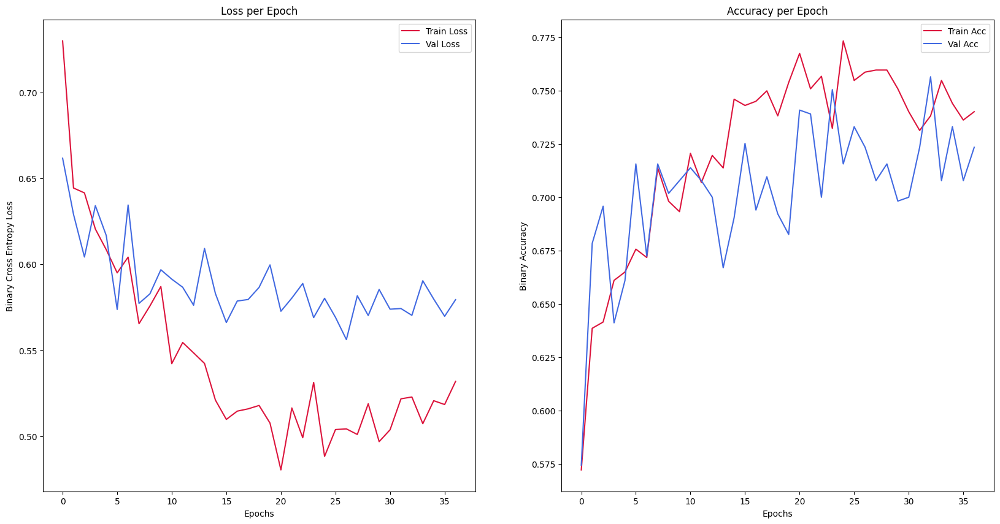

In [ ]:
# Train
model, loss_hist, acc_hist, vloss_hist, vacc_hist = train_binary_classifier(
    model=model,
    dataloaders={'train': train_loader, 'vali': val_loader},
    loss_func=loss_func,
    metric_func=binary_accuracy,
    opt=opt,
    scheduler=scheduler,
    save_best_model=save_best_model,
    early_stopper=early_stopper,
    num_epochs=200,
    batch_size=batch_size,
    device=device,
    show_plot=True
)

# Test

In [ ]:
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay

def evaluate_and_test_model(model, test_loader, loss_func, metric_func, device):
    model.eval()
    test_loss = 0.0
    test_metric = 0.0
    counter = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            counter += 1
            inputs = (inputs[0].to(device), inputs[1].to(device))  # CC and MLO
            labels = labels.to(device).float()

            outputs = model(*inputs)

            # Metrics
            loss = loss_func(outputs, labels)
            acc = metric_func(outputs, labels)

            test_loss += loss.item()
            test_metric += acc.item()

            all_preds.append(outputs.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

    test_loss /= counter
    test_metric /= counter

    print(f"\n🧪 Loss: {test_loss:.4f} | Accuracy: {test_metric:.4f}")

    # Flatten predictions and labels
    y_true = np.concatenate(all_labels)
    y_scores = np.concatenate(all_preds)

    # ROC Curve and AUC
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
    plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Confusion Matrix at threshold 0.5
    y_pred_binary = (y_scores >= 0.5).astype(int)
    cm = confusion_matrix(y_true, y_pred_binary)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
    disp.plot(cmap=plt.cm.Blues)
    plt.title("Confusion Matrix (Threshold = 0.5)")
    plt.tight_layout()
    plt.show()

    return test_loss, test_metric, roc_auc, cm



Loaded best model from epoch 27

Test Set ROC and AUC

🧪 Loss: 0.5596 | Accuracy: 0.7019


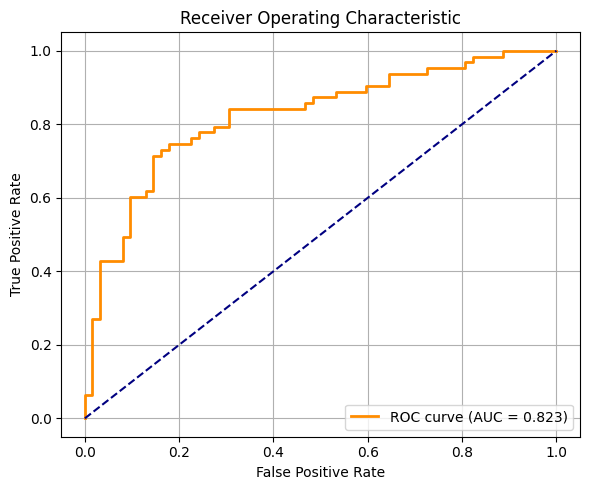

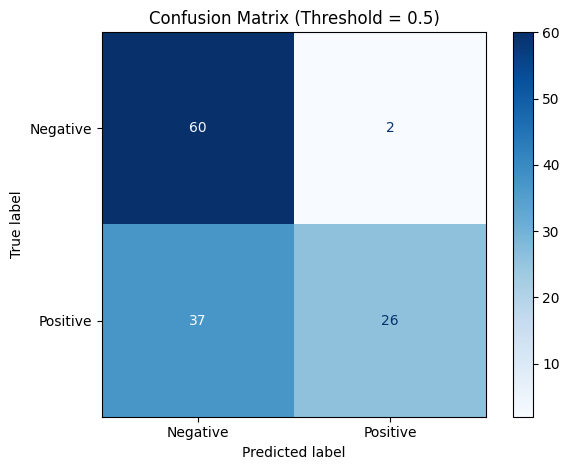

In [ ]:
checkpoint = torch.load('best_model.pt', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model = model.to(device)
print(f"\nLoaded best model from epoch {checkpoint['epoch']}")

print()
print("Test Set ROC and AUC")
test_loss, test_acc, test_auc, test_cm = evaluate_and_test_model(
    model=model,
    test_loader=test_loader,
    loss_func=loss_func,
    metric_func=binary_accuracy,
    device=device
)


Validation Set ROC and AUC

🧪 Loss: 0.5562 | Accuracy: 0.7236


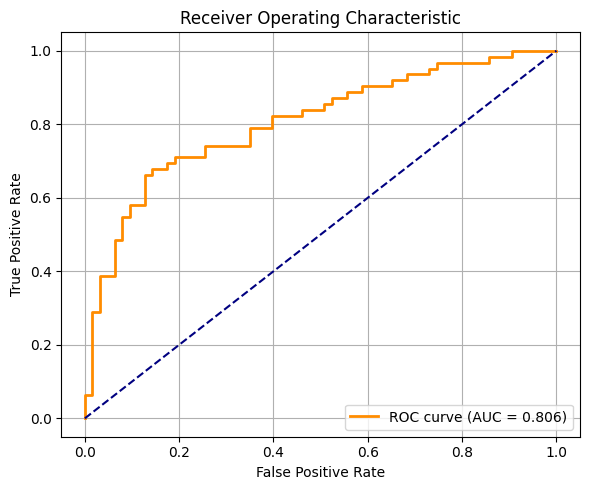

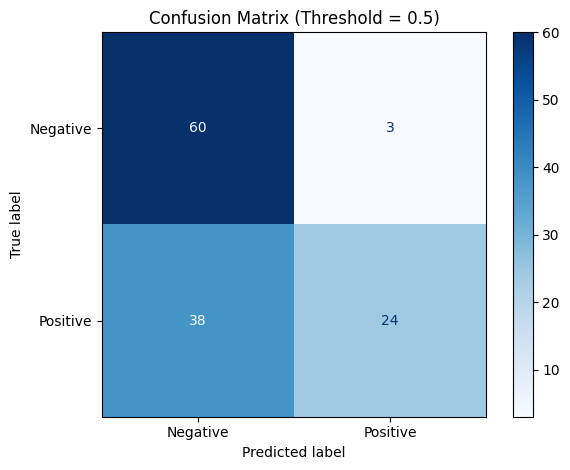

In [ ]:
print("Validation Set ROC and AUC")

val_loss, val_acc, val_auc, val_cm = evaluate_and_test_model(
    model=model,
    test_loader=val_loader,
    loss_func=loss_func,
    metric_func=binary_accuracy,
    device=device
)

# Grad-Cam

In [ ]:
# ====== Grad-CAM (robust + box-safe) ======
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

# =========================================================
# A) Grad-CAM helper using hooks on the last conv blocks
# =========================================================
import torch
import torch.nn.functional as F
import numpy as np

class DualBranchGradCAM:
    """
    Single-layer Grad-CAM using activation-tensor hooks (no module full_backward_hook).
    """
    def __init__(self, model, target_cc_layer, target_mlo_layer):
        self.model = model
        self.hooks = []
        self.cc_act = None
        self.cc_grad = None
        self.mlo_act = None
        self.mlo_grad = None

        def make_fwd(act_attr_name, grad_attr_name):
            def fwd_hook(_, __, out):
                # save activation
                setattr(self, act_attr_name, out)
                # capture grad on the tensor itself (avoids full_backward_hook warning)
                def _grab_grad(g):
                    setattr(self, grad_attr_name, g)
                out.retain_grad()
                out.register_hook(_grab_grad)
            return fwd_hook

        # forward hooks on chosen layers (one per branch)
        self.hooks.append(target_cc_layer.register_forward_hook(make_fwd('cc_act','cc_grad')))
        self.hooks.append(target_mlo_layer.register_forward_hook(make_fwd('mlo_act','mlo_grad')))

    def remove(self):
        for h in self.hooks: h.remove()
        self.hooks = []

    @torch.no_grad()
    def _make_cam(self, act, grad):
        # act/grad: [B,C,H,W] -> [B,H,W] in [0,1]
        w = grad.mean(dim=(2,3), keepdim=True)
        cam = (w * act).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam_min = cam.amin(dim=(2,3), keepdim=True)
        cam_max = cam.amax(dim=(2,3), keepdim=True)
        cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)
        return cam.squeeze(1).cpu().numpy()

    def compute(self, logits, target_class=None):
        self.model.zero_grad(set_to_none=True)

        # pick scalar to backprop
        if logits.ndim == 2 and logits.size(1) > 1:
            if target_class is None:
                target = torch.argmax(logits, dim=1)
            else:
                target = torch.full((logits.size(0),), int(target_class), device=logits.device)
            scalar = logits.gather(1, target.view(-1,1)).sum()
            prob = torch.softmax(logits, dim=1)[:, target[0]].item()
        else:
            scalar = logits.view(-1).sum()
            prob = torch.sigmoid(logits.view(-1)[0]).item()

        scalar.backward(retain_graph=False)

        if any(x is None for x in [self.cc_act, self.cc_grad, self.mlo_act, self.mlo_grad]):
            raise RuntimeError("Grad-CAM hooks failed. Check chosen target layers.")

        cc_cam = self._make_cam(self.cc_act, self.cc_grad)[0]
        mlo_cam = self._make_cam(self.mlo_act, self.mlo_grad)[0]
        return cc_cam, mlo_cam, prob


def compute_gradcam(model, cc_tensor, mlo_tensor, device, gradcam_helper, target_class=None):
    model.eval()
    with torch.enable_grad():
        cc_tensor = cc_tensor.to(device, non_blocking=True)
        mlo_tensor = mlo_tensor.to(device, non_blocking=True)
        logits = model(cc_tensor, mlo_tensor)  # [B,1] binary logit in this model
        cc_cam, mlo_cam, prob = gradcam_helper.compute(logits, target_class=target_class)
    return cc_cam, mlo_cam, prob


In [ ]:
checkpoint = torch.load('best_model.pt', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model = model.to(device)
print(f"\nLoaded best model from epoch {checkpoint['epoch']}")

model.eval()
cc_target_layer = model.cc_backbone.features[-1] # or -2 / -3 for earlier, higher-res blocks
mlo_target_layer = model.mlo_backbone.features[-1]

gradcam_helper = DualBranchGradCAM(model, cc_target_layer, mlo_target_layer)


Loaded best model from epoch 27


In [ ]:

# --- Load doctor-provided boxes (unchanged) ---
bbox_df = pd.read_csv(os.path.join(dataset_folder, "finding_annotations.csv")).dropna(how='any')
print('annotations #: ', len(bbox_df))
bbox_dict = {
    row['image_id']: {
        "orig_size": (row['width'], row['height']),
        "bbox": (row['xmin'], row['ymin'], row['xmax'], row['ymax'])
    }
    for _, row in bbox_df.iterrows()
}

# =========================================================
# B) Coordinate & geometry helpers (padded-space centric)
# =========================================================
def padded_dims_from_info(crop_box, pad):
    cx1, cy1, cx2, cy2 = crop_box
    pad_left, pad_top, pad_right, pad_bottom = pad
    w = (cx2 - cx1) + pad_left + pad_right
    h = (cy2 - cy1) + pad_top + pad_bottom
    return int(w), int(h)

def map_doctor_box_to_padded(bbox, orig_size, crop_box, pad, flip=False, xmax_ymax_inclusive=True):
    """
    Return doctor box in *padded space* (after crop+pad, BEFORE resize).
    This space is the reference for metrics to avoid scaling drift.
    """
    x_min, y_min, x_max, y_max = bbox

    if xmax_ymax_inclusive:
        x_max += 1
        y_max += 1

    orig_w, orig_h = orig_size
    if flip:
        x_min, x_max = orig_w - x_max, orig_w - x_min

    cx1, cy1, cx2, cy2 = crop_box
    pad_left, pad_top, pad_right, pad_bottom = pad

    # crop
    x_min -= cx1; x_max -= cx1
    y_min -= cy1; y_max -= cy1
    # pad
    x_min += pad_left; x_max += pad_left
    y_min += pad_top;  y_max += pad_top

    # round for stability
    x_min = int(round(x_min)); x_max = int(round(x_max))
    y_min = int(round(y_min)); y_max = int(round(y_max))
    return (x_min, y_min, x_max, y_max)

def scale_box(box, from_size, to_size):
    """Scale (x1,y1,x2,y2) from one size to another (exclusive upper bound semantics)."""
    if box is None: return None
    x1,y1,x2,y2 = box
    fw, fh = from_size
    tw, th = to_size
    sx, sy = tw / max(fw,1e-8), th / max(fh,1e-8)
    return (int(round(x1 * sx)), int(round(y1 * sy)),
            int(round(x2 * sx)), int(round(y2 * sy)))

def box_iou(a, b):
    """IoU with exclusive upper bounds."""
    if a is None or b is None: return None
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    if ax1 >= ax2 or ay1 >= ay2 or bx1 >= bx2 or by1 >= by2:
        return 0.0
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0, ix2 - ix1), max(0, iy2 - iy1)
    inter = iw * ih
    ua = (ax2 - ax1) * (ay2 - ay1)
    ub = (bx2 - bx1) * (by2 - by1)
    union = max(ua + ub - inter, 1e-8)
    return float(inter / union)

# =========================================================
# C) CAM → predicted box in padded space
# =========================================================
def cam_top_mass_threshold(cam, mass_ratio=0.5):
    """
    Compute a threshold so that pixels >= t contain ~mass_ratio of total CAM mass.
    """
    flat = cam.flatten()
    if flat.sum() <= 0:
        return 1.0  # everything zero; threshold at 1 gives empty mask
    order = np.argsort(flat)[::-1]  # descending
    sorted_vals = flat[order]
    csum = np.cumsum(sorted_vals)
    cutoff_idx = np.searchsorted(csum, mass_ratio * csum[-1], side='left')
    t = sorted_vals[min(cutoff_idx, len(sorted_vals)-1)]
    return float(t)

def cam_to_pred_box(cam_padded, mass_ratio=0.5, min_area=25):
    """
    cam_padded: CAM resized to padded space (H,W) in [0,1].
    Returns a bounding box (x1,y1,x2,y2) around the largest Connected Component above threshold.
    """
    t = cam_top_mass_threshold(cam_padded, mass_ratio)
    mask = (cam_padded >= t).astype(np.uint8)
    if mask.sum() < min_area:
        # Fallback: lower threshold or return None
        # Lower threshold to the 90th percentile of non-zeros
        nz = cam_padded[cam_padded > 0]
        if nz.size == 0:
            return None
        t2 = np.percentile(nz, 90)
        mask = (cam_padded >= t2).astype(np.uint8)
        if mask.sum() < min_area:
            return None

    num_labels, labels = cv2.connectedComponents(mask)
    if num_labels <= 1:
        ys, xs = np.where(mask > 0)
        if ys.size == 0: return None
        return (int(xs.min()), int(ys.min()), int(xs.max()+1), int(ys.max()+1))

    # Largest CC (skip background = 0)
    best_label, best_area = 1, 0
    for lab in range(1, num_labels):
        area = int((labels == lab).sum())
        if area > best_area:
            best_label, best_area = lab, area

    ys, xs = np.where(labels == best_label)
    if ys.size == 0: return None
    return (int(xs.min()), int(ys.min()), int(xs.max()+1), int(ys.max()+1))

# =========================================================
# D) Metrics in padded space
# =========================================================
def fraction_inside(cam_padded, doctor_box_padded, threshold=0.2):
    """
    Fraction of CAM mass (>=threshold) inside doctor box in padded space.
    """
    if doctor_box_padded is None:
        return None
    x1,y1,x2,y2 = doctor_box_padded
    if x1 >= x2 or y1 >= y2:
        return 0.0
    cam_thr = np.where(cam_padded >= threshold, cam_padded, 0.0)
    tot = cam_thr.sum()
    if tot <= 0: return 0.0
    inside = cam_thr[y1:y2, x1:x2].sum()
    return float(inside / (tot + 1e-8))

# =========================================================
# E) Overlay (display only) – accepts doctor box in padded space and (optional) heatmap-derived box in padded sapce
# =========================================================
def show_overlay_with_bboxes(image_tensor, cam_in_image_space,
                             doctor_box_padded=None, pred_box_padded=None,
                             padded_size=None,
                             title="Grad-CAM + BBoxes",
                             effnet_mean=None, effnet_std=None):
    """
    Draws both doctor and predicted boxes (both given in *padded* space).
    - doctor box: blue
    - predicted CAM box: green
    """
    import numpy as np, cv2, matplotlib.pyplot as plt

    # --- prep image (unnormalize if needed) ---
    img = image_tensor.detach().squeeze(0).cpu().numpy()
    if img.ndim == 3 and img.shape[0] == 3:
        if effnet_mean is not None and effnet_std is not None:
            mean = np.array(effnet_mean).reshape(3,1,1)
            std  = np.array(effnet_std).reshape(3,1,1)
            img = img * std + mean
        img = np.transpose(img, (1,2,0))
    elif img.ndim == 2:
        img = img[..., None]
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)

    h, w = img.shape[:2]
    cam_resized = cv2.resize(cam_in_image_space.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR)
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)[..., ::-1] / 255.0

    if img.shape[-1] == 1:
        img = np.repeat(img, 3, axis=-1)
    overlay = np.clip(0.6 * img + 0.4 * heatmap, 0, 1)
    overlay = (overlay * 255).astype(np.uint8)
    overlay = np.ascontiguousarray(overlay)  # OpenCV requirement

    def _draw_box(padded_box, color_bgr, label_text):
        if padded_box is None or padded_size is None:
            return
        pad_w, pad_h = padded_size
        if pad_w <= 0 or pad_h <= 0: return
        x1,y1,x2,y2 = padded_box
        if not (np.isfinite([x1,y1,x2,y2]).all() and x2 > x1 and y2 > y1):
            return
        sx, sy = w / pad_w, h / pad_h
        dx1, dy1 = int(round(x1 * sx)), int(round(y1 * sy))
        dx2, dy2 = int(round(x2 * sx)), int(round(y2 * sy))
        dx1 = np.clip(dx1, 0, w-1); dx2 = np.clip(dx2, 0, w-1)
        dy1 = np.clip(dy1, 0, h-1); dy2 = np.clip(dy2, 0, h-1)
        if dx2 <= dx1 or dy2 <= dy1: return
        thickness = max(2, int(0.003 * max(w, h)))
        cv2.rectangle(overlay, (dx1, dy1), (dx2, dy2), color_bgr, thickness)
        if label_text:
            cv2.putText(overlay, label_text, (dx1, max(0, dy1-5)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, color_bgr, 1, lineType=cv2.LINE_AA)

    # blue doctor, green predicted
    _draw_box(doctor_box_padded,  (255, 0, 0), "doctor")
    if pred_box_padded is not None:
        _draw_box(pred_box_padded,    (0, 255, 0), "pred")

    plt.imshow(overlay)
    plt.title(title)
    plt.axis("off")
    plt.show()


# =========================================================
# F) End-to-end evaluation using padded space as the reference
# =========================================================
def evaluate_and_visualize_gradcam_padded(
    model, df, image_dict, info_dict, bbox_dict,
    device, gradcam_helper,
    dataset_name="test", max_images_to_show=10,
    mass_ratio_for_cam_box=0.5, frac_threshold=0.2, show=True
):
    results = []
    shown = 0

    df_pos = df[df["binary_class"] == 1].reset_index(drop=True)
    df_pos_w_bbox = df_pos[df_pos.apply(lambda r: r["CC"] in bbox_dict or r["MLO"] in bbox_dict, axis=1)].reset_index(drop=True)

    print(f"➡️  {dataset_name.upper()} | Positives: {len(df_pos)} | With bbox: {len(df_pos_w_bbox)}")

    for _, row in df_pos_w_bbox.iterrows():
        if shown >= max_images_to_show: break

        cc_id, mlo_id = row["CC"], row["MLO"]
        laterality = row["laterality"]

        # Build normalized tensors (same as your pipeline)
        try:
            cc_np, mlo_np = image_dict[(cc_id, mlo_id)]
        except KeyError:
            print(f"{dataset_name.upper()} - missing pair: {cc_id},{mlo_id}")
            continue

        cc_t = torch.from_numpy(np.clip(cc_np, 0, train_pixel_max) / train_pixel_max).unsqueeze(0)
        mlo_t = torch.from_numpy(np.clip(mlo_np, 0, train_pixel_max) / train_pixel_max).unsqueeze(0)
        cc_t = cc_t.expand(3, -1, -1).unsqueeze(0).to(device)
        mlo_t = mlo_t.expand(3, -1, -1).unsqueeze(0).to(device)

        eff_mean = torch.tensor(effnet_mean, dtype=cc_t.dtype, device=device).view(1,3,1,1)
        eff_std  = torch.tensor(effnet_std,  dtype=cc_t.dtype, device=device).view(1,3,1,1)
        cc_t = (cc_t - eff_mean) / eff_std
        mlo_t = (mlo_t - eff_mean) / eff_std

        # CAMs at activation resolution
        with torch.enable_grad():
            cc_cam, mlo_cam, prob = compute_gradcam(model, cc_t, mlo_t, device, gradcam_helper)

        # Padded dims and mapping
        try:
            info_cc, info_mlo = info_dict[(cc_id, mlo_id)]
        except KeyError:
            print(f"{dataset_name.upper()} - missing info for: {cc_id},{mlo_id}")
            continue

        padW_cc, padH_cc = padded_dims_from_info(info_cc["crop_box"], info_cc["pad"])
        padW_mlo, padH_mlo = padded_dims_from_info(info_mlo["crop_box"], info_mlo["pad"])

        # Resize CAMs to padded space
        cc_cam_padded  = cv2.resize(cc_cam.astype(np.float32), (padW_cc, padH_cc), interpolation=cv2.INTER_LINEAR)
        mlo_cam_padded = cv2.resize(mlo_cam.astype(np.float32), (padW_mlo, padH_mlo), interpolation=cv2.INTER_LINEAR)

        # Doctor boxes in padded space
        cc_info = bbox_dict.get(cc_id)
        mlo_info = bbox_dict.get(mlo_id)
        flip_flag = (laterality == "R")

        cc_doc_pad = map_doctor_box_to_padded(
            cc_info["bbox"], cc_info["orig_size"], info_cc["crop_box"], info_cc["pad"], flip=flip_flag
        ) if cc_info else None

        mlo_doc_pad = map_doctor_box_to_padded(
            mlo_info["bbox"], mlo_info["orig_size"], info_mlo["crop_box"], info_mlo["pad"], flip=flip_flag
        ) if mlo_info else None

        # Metrics (padded space)
        cc_frac = fraction_inside(cc_cam_padded, cc_doc_pad, threshold=frac_threshold) if cc_doc_pad else None
        mlo_frac = fraction_inside(mlo_cam_padded, mlo_doc_pad, threshold=frac_threshold) if mlo_doc_pad else None

        # CAM-predicted boxes (padded)
        cc_cam_box = cam_to_pred_box(cc_cam_padded, mass_ratio=mass_ratio_for_cam_box)
        mlo_cam_box = cam_to_pred_box(mlo_cam_padded, mass_ratio=mass_ratio_for_cam_box)

        # IoU (doctor vs CAM box) in padded space
        cc_iou = box_iou(cc_doc_pad, cc_cam_box) if cc_doc_pad and cc_cam_box else None
        mlo_iou = box_iou(mlo_doc_pad, mlo_cam_box) if mlo_doc_pad and mlo_cam_box else None

        results.append({
            "cc_id": cc_id,
            "mlo_id": mlo_id,
            "laterality": laterality,
            "prediction": prob,
            "cc_fraction_in": cc_frac,
            "mlo_fraction_in": mlo_frac,
            "cc_iou": cc_iou,
            "mlo_iou": mlo_iou,
            "dataset": dataset_name
        })

        if show:
            # For display, scale CAM to image size and scale padded doctor box -> image
            cc_cam_img = cv2.resize(cc_cam, (cc_t.shape[-1], cc_t.shape[-2]), interpolation=cv2.INTER_LINEAR)
            mlo_cam_img = cv2.resize(mlo_cam, (mlo_t.shape[-1], mlo_t.shape[-2]), interpolation=cv2.INTER_LINEAR)

            show_overlay_with_bboxes(
                cc_t, cc_cam_img,
                doctor_box_padded=cc_doc_pad, pred_box_padded=cc_cam_box, padded_size=(padW_cc, padH_cc),
                title=f"{dataset_name.upper()} CC | Pred: {prob:.2f} | Frac: {'N/A' if cc_frac is None else f'{cc_frac:.2f}'} | IoU: {'N/A' if cc_iou is None else f'{cc_iou:.2f}'}",
                effnet_mean=effnet_mean, effnet_std=effnet_std
            )
            show_overlay_with_bboxes(
                mlo_t, mlo_cam_img,
                doctor_box_padded=mlo_doc_pad, pred_box_padded=mlo_cam_box, padded_size=(padW_mlo, padH_mlo),
                title=f"{dataset_name.upper()} MLO | Pred: {prob:.2f} | Frac: {'N/A' if mlo_frac is None else f'{mlo_frac:.2f}'} | IoU: {'N/A' if mlo_iou is None else f'{mlo_iou:.2f}'}",
                effnet_mean=effnet_mean, effnet_std=effnet_std
            )
            shown += 1

    return pd.DataFrame(results)


annotations #:  2129


➡️  TEST | Positives: 63 | With bbox: 63


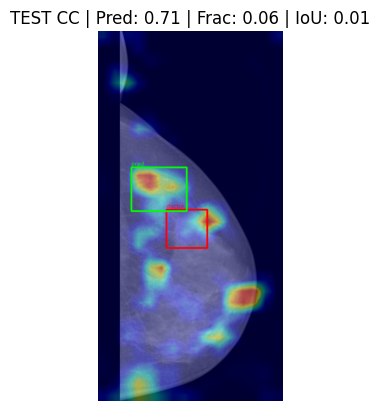

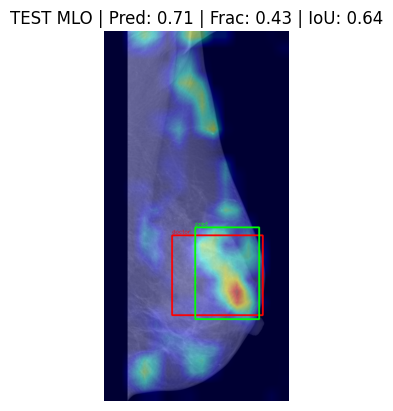

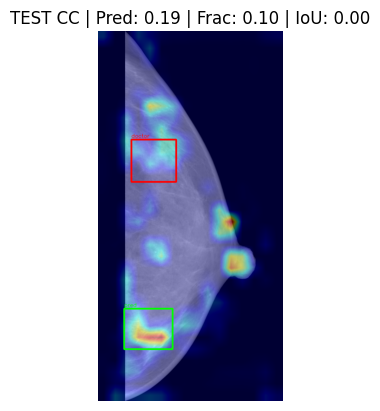

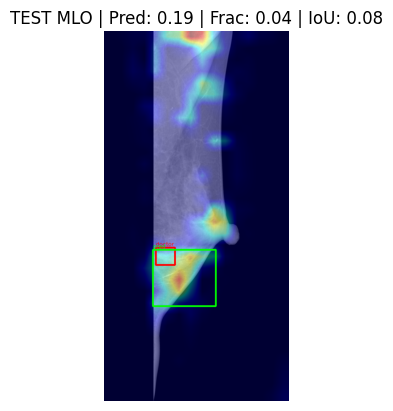

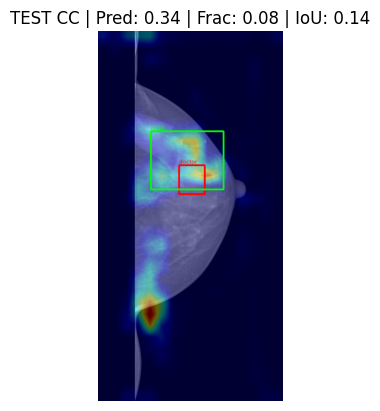

...

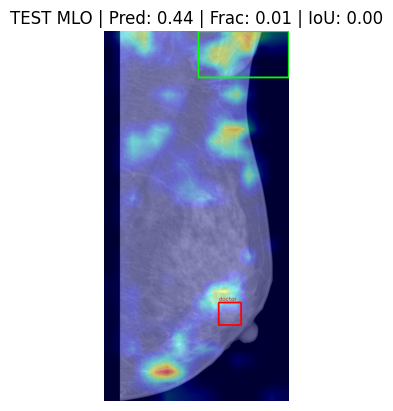

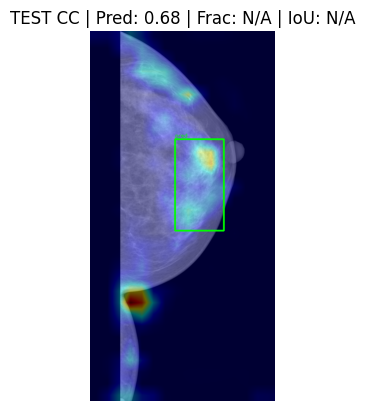

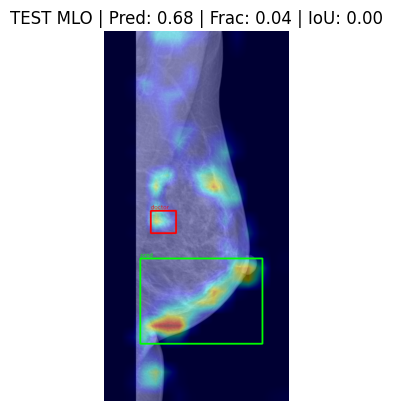

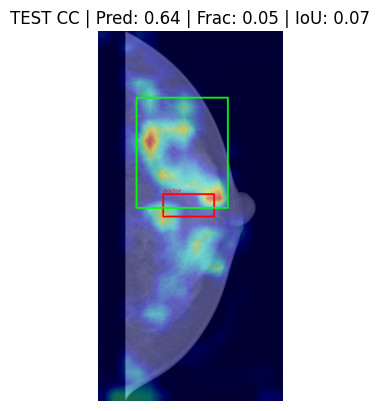

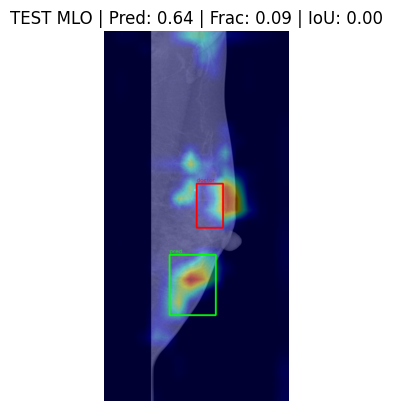

In [ ]:
df_test_results = evaluate_and_visualize_gradcam_padded(
    model, test_df, image_dict, info_dict, bbox_dict,
    device, gradcam_helper,
    dataset_name="test", max_images_to_show=10,
    mass_ratio_for_cam_box=0.5, frac_threshold=0.2, show=True
)

➡️  VAL | Positives: 62 | With bbox: 62


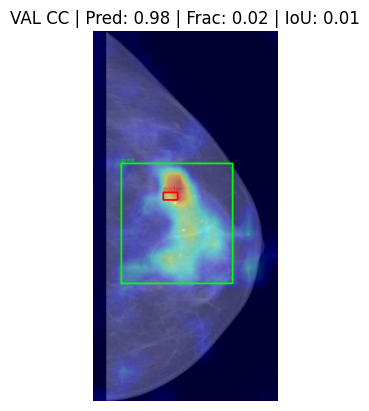

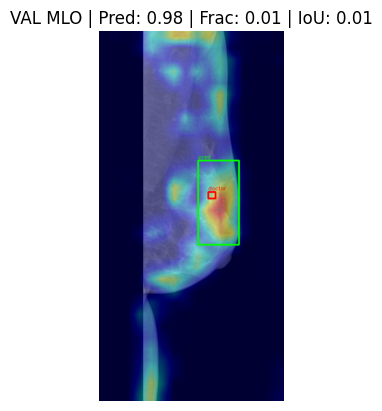

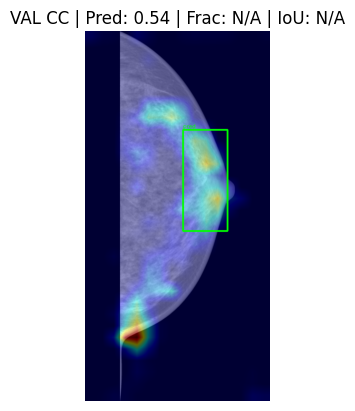

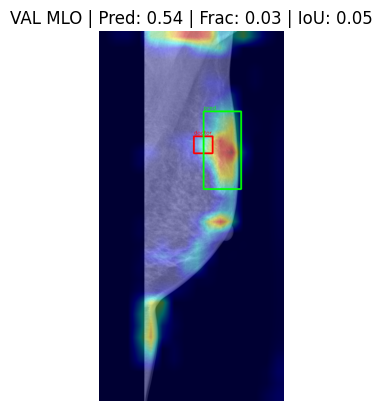

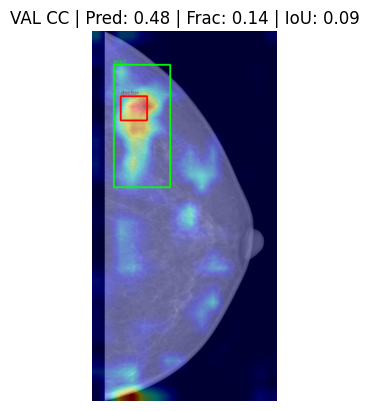

...

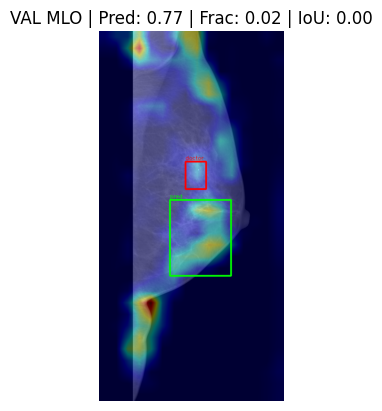

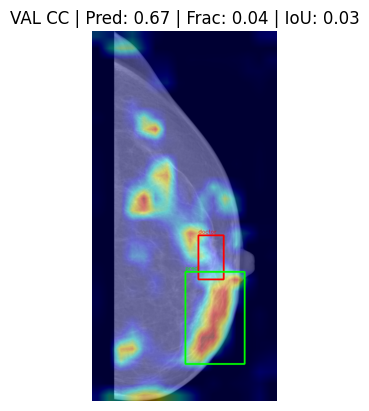

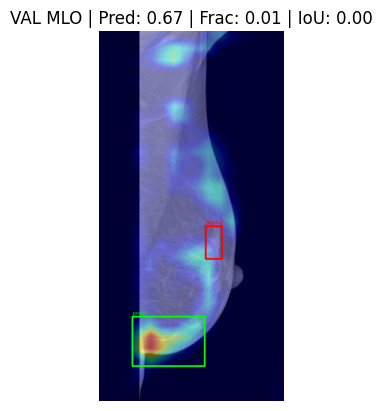

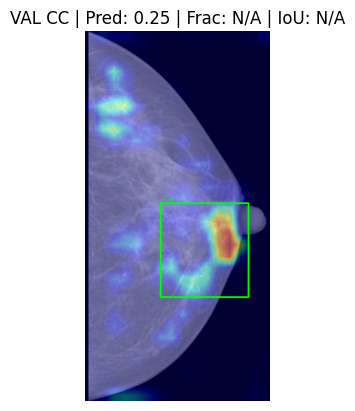

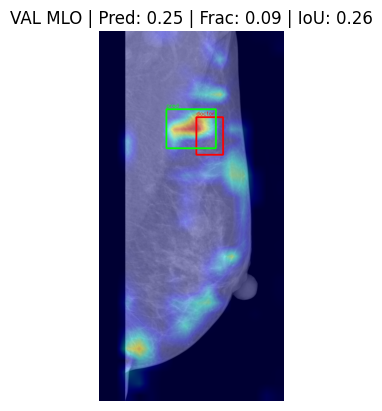

In [ ]:
df_val_results = evaluate_and_visualize_gradcam_padded(
    model, val_df, image_dict, info_dict, bbox_dict,
    device, gradcam_helper,
    dataset_name="val", max_images_to_show=10,
    mass_ratio_for_cam_box=0.5, frac_threshold=0.2, show=True
)

➡️  TRAIN | Positives: 523 | With bbox: 523


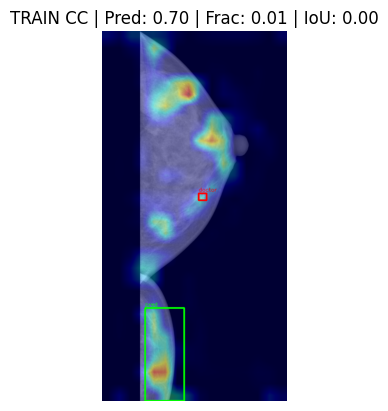

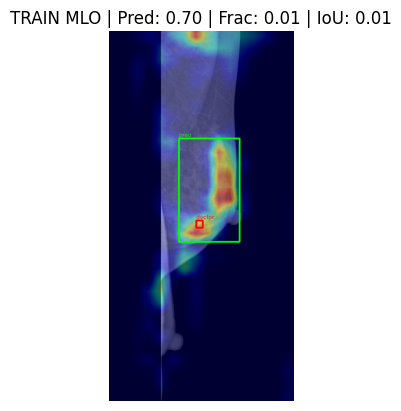

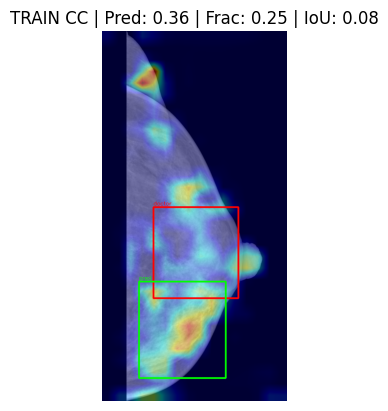

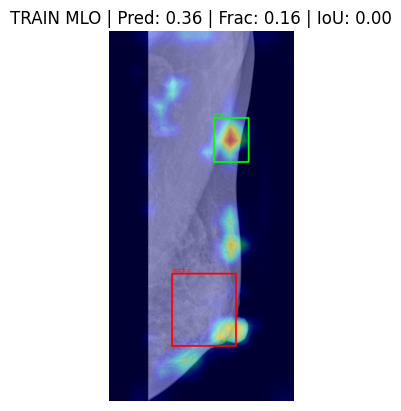

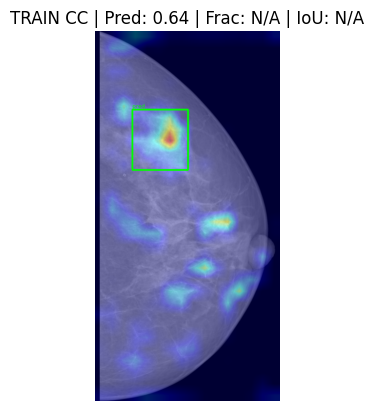

...

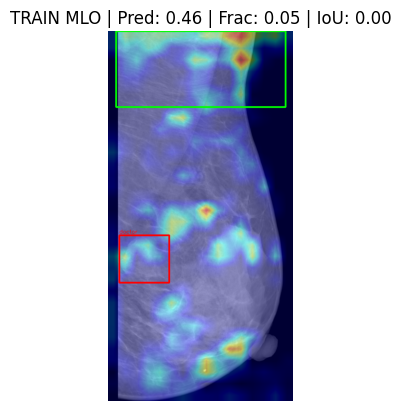

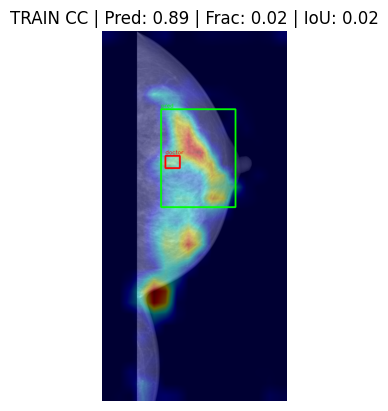

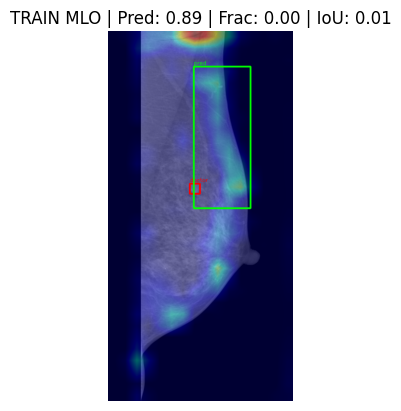

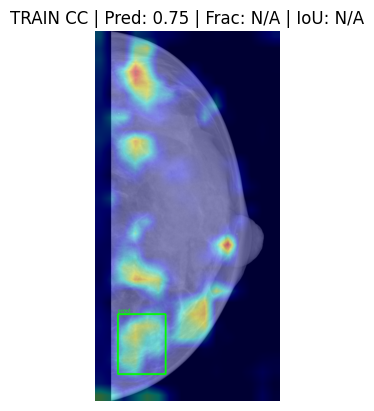

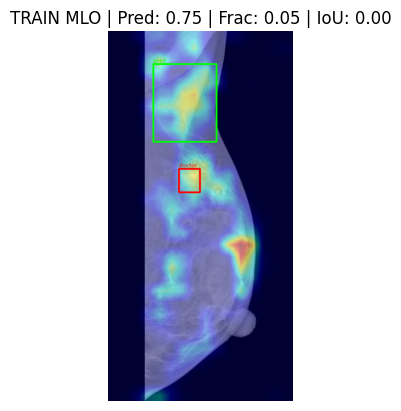

In [ ]:

df_train_results = evaluate_and_visualize_gradcam_padded(
    model, train_df, image_dict, info_dict, bbox_dict,
    device, gradcam_helper,
    dataset_name="train", max_images_to_show=10, show=True
)


In [ ]:
# Histogram by view
import matplotlib.pyplot as plt

def plot_view_fractions(df_results, cc_column="cc_fraction_in", mlo_column="mlo_fraction_in", bins=10, title= "Grad-CAM Fraction Inside Doctor Box"):
    """
    Plot overlapping histograms for CC and MLO fraction-in or IoU values.

    Args:
        df_results (pd.DataFrame): DataFrame with columns like 'cc_fraction_in' and 'mlo_fraction_in'
        cc_column (str): Name of the CC column (default 'cc_fraction_in')
        mlo_column (str): Name of the MLO column (default 'mlo_fraction_in')
        bins (int): Number of histogram bins
        title (str): Plot title
    """
    cc_values = df_results[cc_column].dropna()
    mlo_values = df_results[mlo_column].dropna()

    plt.figure(figsize=(10, 5))
    plt.hist(cc_values, bins=bins, alpha=0.6, label='CC', color='blue', edgecolor='black')
    plt.hist(mlo_values, bins=bins, alpha=0.6, label='MLO', color='orange', edgecolor='black')
    plt.title(title)
    plt.xlabel("Fraction inside the box")
    plt.ylabel("Count")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


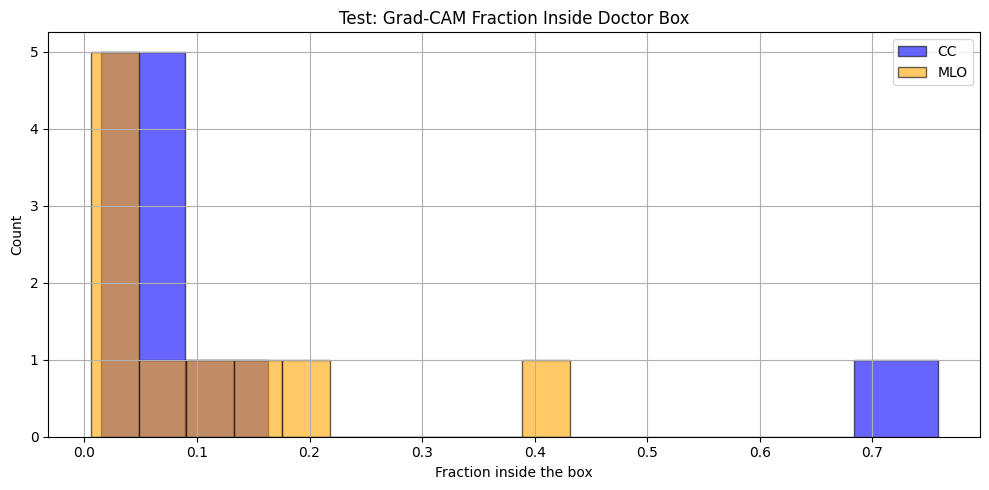

In [ ]:
plot_view_fractions(df_test_results, cc_column="cc_fraction_in", mlo_column="mlo_fraction_in", title="Test: Grad-CAM Fraction Inside Doctor Box")

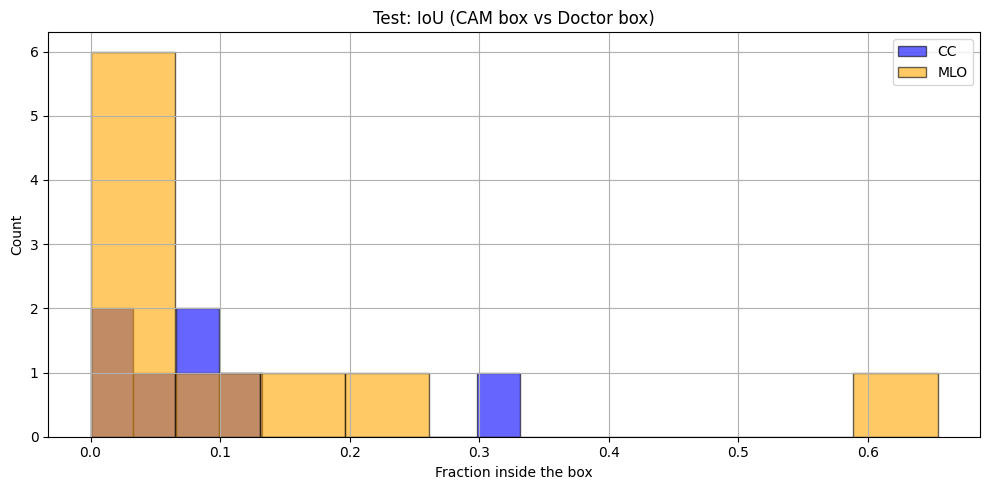

In [ ]:
plot_view_fractions(df_test_results, cc_column="cc_iou", mlo_column="mlo_iou", title="Test: IoU (CAM box vs Doctor box)")


In [ ]:
import numpy as np
import pandas as pd
import cv2
from collections import defaultdict
from tqdm import tqdm
import matplotlib.pyplot as plt

# ---- Metrics (padded space) ----
def fraction_inside_energy(cam_padded, box, tau):
    if box is None: return None
    x1,y1,x2,y2 = box
    if x1>=x2 or y1>=y2: return 0.0
    cam_thr = np.where(cam_padded >= tau, cam_padded, 0.0)
    tot = cam_thr.sum()
    if tot <= 0: return 0.0
    return float(cam_thr[y1:y2, x1:x2].sum() / (tot + 1e-8))

def fraction_inside_area(cam_padded, box, tau):
    if box is None: return None
    x1,y1,x2,y2 = box
    if x1>=x2 or y1>=y2: return 0.0
    mask = (cam_padded >= tau).astype(np.uint8)
    tot = int(mask.sum())
    if tot == 0: return 0.0
    return float(mask[y1:y2, x1:x2].sum() / max(tot,1))

def soft_iou(cam_padded, box):
    if box is None: return None
    x1,y1,x2,y2 = box
    H,W = cam_padded.shape
    B = np.zeros_like(cam_padded, dtype=np.float32); B[y1:y2, x1:x2] = 1.0
    num = np.minimum(cam_padded, B).sum()
    den = np.maximum(cam_padded, B).sum() + 1e-8
    return float(num / den)

def pointing_game(cam_padded, box):
    if box is None: return None
    y,x = np.unravel_index(np.argmax(cam_padded), cam_padded.shape)
    x1,y1,x2,y2 = box
    return 1.0 if (x1 <= x < x2 and y1 <= y < y2) else 0.0

# ---- Threshold pickers (per-image) ----
def choose_tau_percentile(cam_padded, p=90):
    nz = cam_padded[cam_padded > 0]
    if nz.size == 0: return 1.0
    return float(np.percentile(nz, p))

# ---- Utilities to (re)compute CAMs in padded space & collect boxes ----
def compute_cams_for_set(df, image_dict, info_dict, device, gradcam_helper, laterality_col='laterality'):
    """
    Returns:
      cams: dict view_id -> cam_padded (np[H_pad,W_pad] in [0,1])
      probs: dict pair_key -> prob
      boxes: dict view_id -> doctor box in padded coords (or None)
      pad_sizes: dict view_id -> (W_pad, H_pad)
    """
    cams, boxes, pad_sizes = {}, {}, {}
    probs = {}
    for _, row in tqdm(df.iterrows(), total=len(df), desc="CAMs"):
        cc_id, mlo_id = row["CC"], row["MLO"]
        laterality = row[laterality_col]
        try:
            cc_np, mlo_np = image_dict[(cc_id, mlo_id)]
            info_cc, info_mlo = info_dict[(cc_id, mlo_id)]
        except KeyError:
            continue

        # tensors as in your pipeline
        cc_t = torch.from_numpy(np.clip(cc_np, 0, train_pixel_max) / train_pixel_max).unsqueeze(0).expand(3,-1,-1).unsqueeze(0).to(device)
        mlo_t= torch.from_numpy(np.clip(mlo_np,0, train_pixel_max) / train_pixel_max).unsqueeze(0).expand(3,-1,-1).unsqueeze(0).to(device)
        eff_mean = torch.tensor(effnet_mean, dtype=cc_t.dtype, device=device).view(1,3,1,1)
        eff_std  = torch.tensor(effnet_std,  dtype=cc_t.dtype, device=device).view(1,3,1,1)
        cc_t = (cc_t - eff_mean) / eff_std
        mlo_t= (mlo_t - eff_mean) / eff_std

        with torch.enable_grad():
            cc_cam, mlo_cam, prob = compute_gradcam(model, cc_t, mlo_t, device, gradcam_helper)
        probs[(cc_id,mlo_id)] = prob

        # resize to padded space
        padW_cc, padH_cc = padded_dims_from_info(info_cc["crop_box"], info_cc["pad"])
        padW_mlo, padH_mlo = padded_dims_from_info(info_mlo["crop_box"], info_mlo["pad"])
        cams[cc_id]  = cv2.resize(cc_cam.astype(np.float32), (padW_cc, padH_cc), interpolation=cv2.INTER_LINEAR)
        cams[mlo_id] = cv2.resize(mlo_cam.astype(np.float32), (padW_mlo, padH_mlo), interpolation=cv2.INTER_LINEAR)
        pad_sizes[cc_id]  = (padW_cc, padH_cc)
        pad_sizes[mlo_id] = (padW_mlo, padH_mlo)

        # map doctor boxes
        flip_flag = (laterality == "R")
        cc_info = bbox_dict.get(cc_id);  mlo_info = bbox_dict.get(mlo_id)
        boxes[cc_id]  = map_doctor_box_to_padded(cc_info["bbox"], cc_info["orig_size"], info_cc["crop_box"], info_cc["pad"], flip=flip_flag) if cc_info else None
        boxes[mlo_id] = map_doctor_box_to_padded(mlo_info["bbox"], mlo_info["orig_size"], info_mlo["crop_box"], info_mlo["pad"], flip=flip_flag) if mlo_info else None
    return cams, boxes, pad_sizes, probs

def box_area_fraction(box, pad_size):
    if box is None or pad_size is None: return None
    x1,y1,x2,y2 = box
    w = max(0, x2 - x1); h = max(0, y2 - y1)
    W,H = pad_size
    return (w*h) / max(W*H, 1)

# ---- Baselines ----
def analytic_area_baseline(box, pad_size):
    "Expected fraction_inside under uniform mass."
    return box_area_fraction(box, pad_size)

def empirical_shuffled_box_baseline(view_id, cams, boxes, pad_sizes, pool_ids, K=20, tau_policy=('percentile', 90)):
    """
    For a given CAM(view_id), pair with K random boxes from other ids (same view pool)
    and compute mean energy-inside baseline.
    """
    cam = cams[view_id]; pad_size = pad_sizes[view_id]
    # pick τ per image
    if tau_policy[0] == 'percentile':
        tau = choose_tau_percentile(cam, p=tau_policy[1])
    else:
        tau = 0.2

    others = [i for i in pool_ids if i != view_id and boxes.get(i) is not None]
    if not others: return np.nan
    sample = np.random.default_rng().choice(others, size=min(K, len(others)), replace=False)
    vals = []
    for oid in sample:
        vals.append(fraction_inside_energy(cam, boxes[oid], tau))
    return float(np.nanmean(vals)) if vals else np.nan

# ---- Build a tidy analysis table (one row per VIEW) ----
def build_analysis_table(df, cams, boxes, pad_sizes, probs, tau_policy=('percentile', 90)):
    """
    Returns a long-form DataFrame with columns:
    ['pair','view','view_id','prob','tau','frac_energy','frac_area','soft_iou','pointing',
     'area_baseline','shuffle_baseline','box_area_frac']
    """
    rows = []
    for _, row in df.iterrows():
        pair = (row['CC'], row['MLO'])
        prob = probs.get(pair, np.nan)
        for view, view_id in [('CC', row['CC']), ('MLO', row['MLO'])]:
            if view_id not in cams or view_id not in boxes: continue
            cam = cams[view_id]; box = boxes[view_id]; pad_size = pad_sizes[view_id]
            if box is None: continue

            # τ per image
            if tau_policy[0] == 'percentile':
                tau = choose_tau_percentile(cam, p=tau_policy[1])
            else:
                tau = 0.2

            frac_e = fraction_inside_energy(cam, box, tau)
            frac_a = fraction_inside_area(cam, box, tau)
            siou   = soft_iou(cam, box)
            point  = pointing_game(cam, box)

            area_base = analytic_area_baseline(box, pad_size)
            # pool ids by view type (keeps size/location distribution of that view)
            pool_ids = [r['CC'] for _, r in df.iterrows()] if view=='CC' else [r['MLO'] for _, r in df.iterrows()]
            shuffle_base = empirical_shuffled_box_baseline(view_id, cams, boxes, pad_sizes, pool_ids, K=20, tau_policy=tau_policy)

            rows.append({
                'pair': pair, 'view': view, 'view_id': view_id,
                'prob': prob, 'tau': tau,
                'frac_energy': frac_e, 'frac_area': frac_a,
                'soft_iou': siou, 'pointing': point,
                'area_baseline': area_base, 'shuffle_baseline': shuffle_base,
                'box_area_frac': box_area_fraction(box, pad_size)
            })
    return pd.DataFrame(rows)

# ---- Plotting helpers ----
def plot_metric_vs_baseline(df_long, metric='frac_energy', title=None):
    vals = df_long[metric].dropna()
    base = df_long['shuffle_baseline'].dropna()
    plt.figure(figsize=(8,5))
    plt.hist(vals, bins=30, alpha=0.6, label=f'{metric}', edgecolor='k')
    plt.hist(base, bins=30, alpha=0.6, label='shuffle baseline', edgecolor='k')
    plt.xlabel(metric); plt.ylabel('count'); plt.title(title or f'{metric} vs shuffled baseline')
    plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

def calibration_plot(df_long, metric='frac_energy', n_bins=10, title=None):
    # bin by predicted prob
    df = df_long[['prob', metric]].dropna().copy()
    df['bin'] = pd.qcut(df['prob'], q=n_bins, duplicates='drop')
    grp = df.groupby('bin')[['prob', metric]].mean()
    plt.figure(figsize=(7,5))
    plt.plot(grp['prob'], grp[metric], marker='o')
    plt.xlabel('mean model probability'); plt.ylabel(f'mean {metric}')
    plt.title(title or f'Calibration of {metric} vs model confidence'); plt.grid(True); plt.tight_layout(); plt.show()


CAMs: 100%|██████████████████████████████████████████████████████████████████████████████████| 125/125 [00:03<00:00, 38.90it/s]


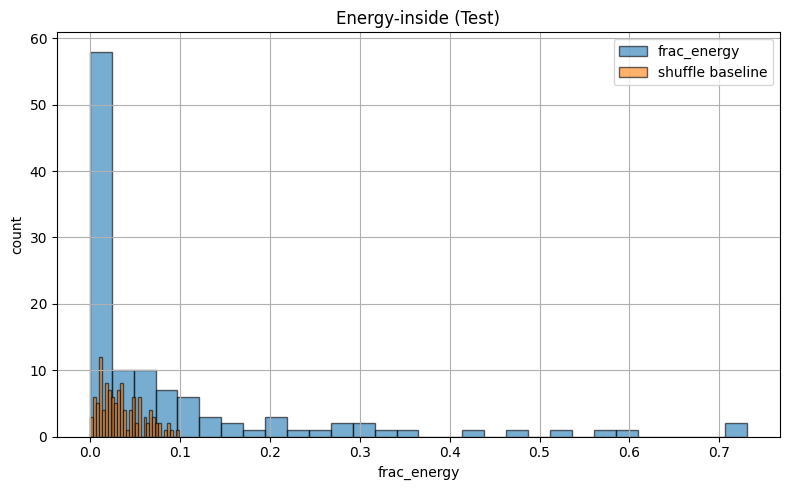

/tmp/ipykernel_2751977/2271926644.py:183: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grp = df.groupby('bin')[['prob', metric]].mean()


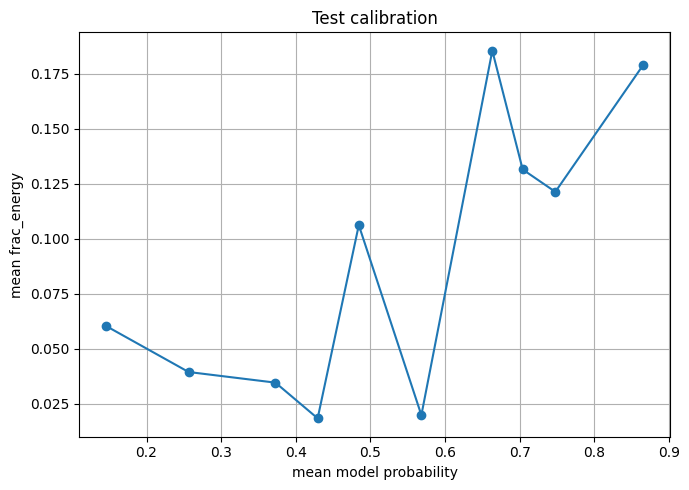

                   frac_energy  soft_iou  pointing
view box_size_bin                                 
CC   0                   0.007     0.007     0.071
     1                   0.067     0.034     0.100
     2                   0.054     0.037     0.000
     3                   0.263     0.094     0.471
MLO  0                   0.005     0.005     0.000
     1                   0.033     0.020     0.000
     2                   0.094     0.052     0.067
     3                   0.187     0.086     0.333


In [ ]:
# 1) Compute or cache CAMs in padded space for the set you care about (e.g., test)
cams_test, boxes_test, pad_sizes_test, probs_test = compute_cams_for_set(
    test_df, image_dict, info_dict, device, gradcam_helper
)

# 2) Build long-form table
df_long_test = build_analysis_table(test_df, cams_test, boxes_test, pad_sizes_test, probs_test,
                                   tau_policy=('percentile', 90))   # top 10% kept

# 3) Plot real vs baseline
plot_metric_vs_baseline(df_long_test, metric='frac_energy', title='Energy-inside (Test)')

# 4) Calibration vs model probability
calibration_plot(df_long_test, metric='frac_energy', n_bins=10, title='Test calibration')

# 5) Quick summary by view & quartiles of box size
df_long_test['box_size_bin'] = pd.qcut(df_long_test['box_area_frac'], 4, labels=False, duplicates='drop')
print(df_long_test.groupby(['view','box_size_bin'])[['frac_energy','soft_iou','pointing']].mean().round(3))


CAMs: 100%|██████████████████████████████████████████████████████████████████████████████████| 125/125 [00:03<00:00, 33.53it/s]


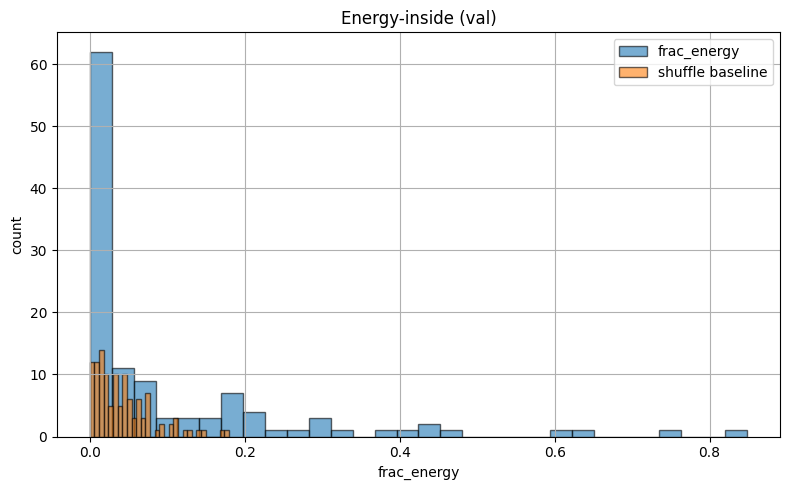

/tmp/ipykernel_2751977/2271926644.py:183: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grp = df.groupby('bin')[['prob', metric]].mean()


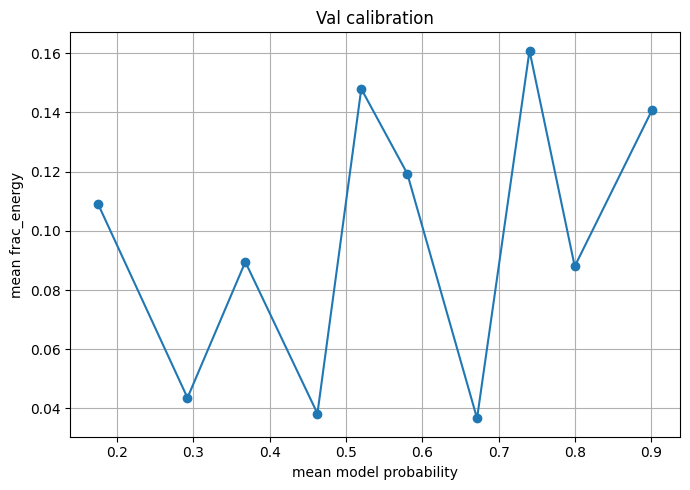

                   frac_energy  soft_iou  pointing
view box_size_bin                                 
CC   0                   0.010     0.007     0.000
     1                   0.051     0.027     0.154
     2                   0.071     0.047     0.167
     3                   0.310     0.103     0.294
MLO  0                   0.011     0.008     0.000
     1                   0.028     0.022     0.062
     2                   0.124     0.063     0.273
     3                   0.177     0.081     0.083


In [ ]:
# 1) Compute or cache CAMs in padded space for the set you care about (e.g., validation)
cams_val, boxes_val, pad_sizes_val, probs_val = compute_cams_for_set(
    val_df, image_dict, info_dict, device, gradcam_helper
)

# 2) Build long-form table
df_long_val = build_analysis_table(val_df, cams_val, boxes_val, pad_sizes_val, probs_val,
                                   tau_policy=('percentile', 90))   # top 10% kept

# 3) Plot real vs baseline
plot_metric_vs_baseline(df_long_val, metric='frac_energy', title='Energy-inside (val)')

# 4) Calibration vs model probability
calibration_plot(df_long_val, metric='frac_energy', n_bins=10, title='Val calibration')

# 5) Quick summary by view & quartiles of box size
df_long_val['box_size_bin'] = pd.qcut(df_long_val['box_area_frac'], 4, labels=False, duplicates='drop')
print(df_long_val.groupby(['view','box_size_bin'])[['frac_energy','soft_iou','pointing']].mean().round(3))


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ----------------------------
# Helpers to gather CAM values
# ----------------------------
def _flatten_cam_values(cams, ids=None, exclude_zeros=True):
    """
    cams: dict image_id -> np.ndarray(H_pad, W_pad) with values in [0,1]
    ids:  iterable of keys to include; if None, use all
    """
    vals = []
    keys = ids if ids is not None else cams.keys()
    for k in keys:
        if k in cams:
            v = cams[k].ravel()
            if exclude_zeros:
                v = v[v > 0.15]
            if v.size:
                vals.append(v)
    return np.concatenate(vals) if vals else np.array([])

def _per_image_percentile(cams, ids, p=90, exclude_zeros=True):
    """
    Return a DataFrame with per-image percentile of CAM values.
    """
    rows = []
    for k in ids:
        if k not in cams:
            continue
        v = cams[k].ravel()
        if exclude_zeros:
            v = v[v > 0]
        if v.size:
            thr = float(np.percentile(v, p))
            rows.append((k, thr))
    return pd.DataFrame(rows, columns=["image_id", f"p{p}"])

# ------------------------------------------
# 1) Histogram(s) of CAM pixel values
# ------------------------------------------
def plot_cam_histograms(cams, df=None, bins=100, exclude_zeros=True, overlay_cc_mlo=True, title=None):
    """
    If df is provided, overlays CC vs MLO distributions.
    Otherwise, plots a single histogram for all CAM pixels.
    """
    if df is None or not overlay_cc_mlo:
        all_vals = _flatten_cam_values(cams, exclude_zeros=exclude_zeros)
        plt.figure(figsize=(8,5))
        plt.hist(all_vals, bins=bins, edgecolor='k', alpha=0.8)
        plt.xlabel("CAM value"); plt.ylabel("Count")
        plt.title(title or "Histogram of CAM pixel values")
        plt.grid(True); plt.tight_layout(); plt.show()
        return

    # Split by view using df
    cc_ids  = df['CC'].unique().tolist()
    mlo_ids = df['MLO'].unique().tolist()
    cc_vals  = _flatten_cam_values(cams, cc_ids, exclude_zeros=exclude_zeros)
    mlo_vals = _flatten_cam_values(cams, mlo_ids, exclude_zeros=exclude_zeros)

    plt.figure(figsize=(9,5))
    plt.hist(cc_vals,  bins=bins, alpha=0.6, label='CC',  edgecolor='k')
    plt.hist(mlo_vals, bins=bins, alpha=0.6, label='MLO', edgecolor='k')
    plt.xlabel("CAM value"); plt.ylabel("Count")
    plt.title(title or "CAM value histograms (CC vs MLO)")
    plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

# -------------------------------------------------
# 2) CDF with annotated percentile thresholds
# -------------------------------------------------
def plot_cam_cdf_with_percentiles(cams, df=None, percentiles=(80, 90, 95), exclude_zeros=True, title=None):
    """
    Plots empirical CDF of pooled CAM pixel values and draws vertical lines
    at chosen percentiles; prints the numeric thresholds.
    """
    if df is not None:
        ids = df['CC'].tolist() + df['MLO'].tolist()
    else:
        ids = None
    vals = _flatten_cam_values(cams, ids, exclude_zeros=exclude_zeros)
    if vals.size == 0:
        print("No CAM values to plot.")
        return

    v = np.sort(vals)
    cdf = np.linspace(0, 1, len(v), endpoint=True)

    plt.figure(figsize=(8,5))
    plt.plot(v, cdf, lw=2)
    for p in percentiles:
        thr = np.percentile(v, p)
        plt.axvline(thr, ls='--', alpha=0.7)
        plt.text(thr, 0.02, f'p{p}={thr:.3f}', rotation=90, va='bottom', ha='right')
        print(f"Percentile {p:>2}: threshold ~ {thr:.4f}")
    plt.xlabel("CAM value"); plt.ylabel("Empirical CDF")
    plt.title(title or "CAM value CDF with percentile thresholds")
    plt.grid(True); plt.tight_layout(); plt.show()

# ----------------------------------------------------------------
# 3) Per-image percentile distribution (box/violin/hist options)
# ----------------------------------------------------------------
def plot_per_image_percentile_distribution(cams, df, p=90, exclude_zeros=True, kind='violin', title=None):
    """
    Computes per-image p-th percentile across all CC+MLO ids in df and plots distribution.
    kind: 'violin' | 'box' | 'hist'
    """
    ids = df['CC'].tolist() + df['MLO'].tolist()
    d = _per_image_percentile(cams, ids, p=p, exclude_zeros=exclude_zeros)
    col = f"p{p}"
    if d.empty:
        print("No per-image percentiles available.")
        return

    plt.figure(figsize=(7,5))
    if kind == 'violin':
        plt.violinplot(d[col].values, showmeans=True, showextrema=True)
        plt.xticks([1],[f'p{p}'])
        plt.ylabel("CAM threshold")
        plt.title(title or f"Per-image p{p} percentile distribution")
    elif kind == 'box':
        plt.boxplot(d[col].values, showmeans=True)
        plt.xticks([1],[f'p{p}'])
        plt.ylabel("CAM threshold")
        plt.title(title or f"Per-image p{p} percentile distribution")
    else:
        plt.hist(d[col].values, bins=30, edgecolor='k', alpha=0.8)
        plt.xlabel("CAM threshold"); plt.ylabel("Count")
        plt.title(title or f"Per-image p{p} percentile distribution")
    plt.grid(True); plt.tight_layout(); plt.show()

    print(f"Per-image p{p}: mean={d[col].mean():.4f}, std={d[col].std():.4f}, "
          f"q25={d[col].quantile(0.25):.4f}, median={d[col].median():.4f}, q75={d[col].quantile(0.75):.4f}")

# ----------------------------------------------------------------
# 4) (Optional) Sweep percentiles -> avg metric (energy-inside)
# ----------------------------------------------------------------
def sweep_percentiles_for_fraction_inside(cams, boxes, df, percentiles=range(70, 100, 5), exclude_zeros=True):
    """
    For each p, compute per-image threshold (p-th percentile) and measure mean energy-inside.
    Returns a DataFrame with columns ['percentile','mean_frac','std_frac','n'].
    """
    from math import isfinite

    # Build a list of entries per view id
    entries = []
    for _, row in df.iterrows():
        for view, vid in [('CC', row['CC']), ('MLO', row['MLO'])]:
            cam = cams.get(vid); box = boxes.get(vid)
            if cam is None or box is None:
                continue
            entries.append((vid, cam, box))

    out = []
    for p in percentiles:
        vals = []
        for vid, cam, box in entries:
            v = cam.ravel()
            if exclude_zeros:
                v = v[v > 0]
            if v.size == 0:
                continue
            tau = np.percentile(v, p)
            # energy-weighted fraction inside
            x1,y1,x2,y2 = box
            if x1>=x2 or y1>=y2:
                continue
            cam_thr = np.where(cam >= tau, cam, 0.0)
            tot = cam_thr.sum()
            if tot <= 0:
                continue
            inside = cam_thr[y1:y2, x1:x2].sum()
            frac = float(inside / (tot + 1e-8))
            if np.isfinite(frac):
                vals.append(frac)
        if vals:
            out.append({'percentile': p,
                        'mean_frac': float(np.mean(vals)),
                        'std_frac': float(np.std(vals)),
                        'n': len(vals)})
    return pd.DataFrame(out)

def plot_sweep(df_sweep, title="Energy-inside vs percentile"):
    if df_sweep.empty:
        print("No sweep results.")
        return
    plt.figure(figsize=(8,5))
    plt.plot(df_sweep['percentile'], df_sweep['mean_frac'], marker='o')
    # ±1 std band
    y = df_sweep['mean_frac'].values
    s = df_sweep['std_frac'].values
    p = df_sweep['percentile'].values
    plt.fill_between(p, y - s, y + s, alpha=0.2)
    plt.xlabel("Percentile p (per-image)"); plt.ylabel("Mean energy-inside")
    plt.title(title); plt.grid(True); plt.tight_layout(); plt.show()


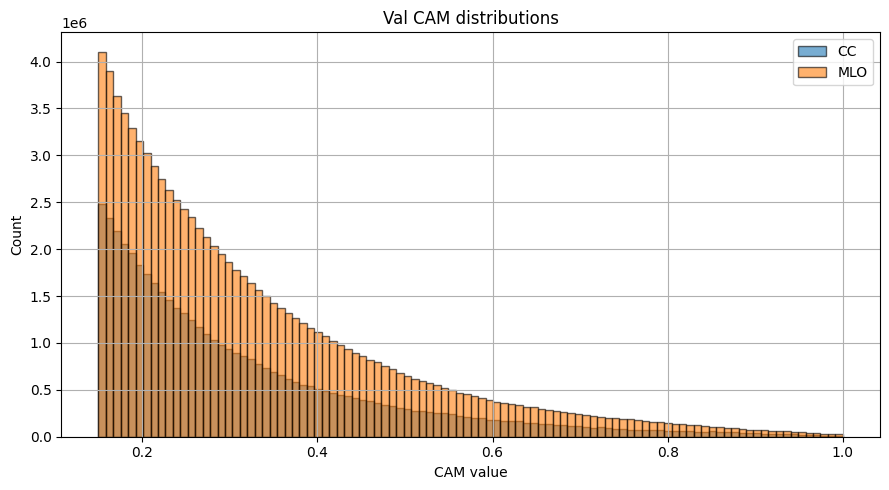

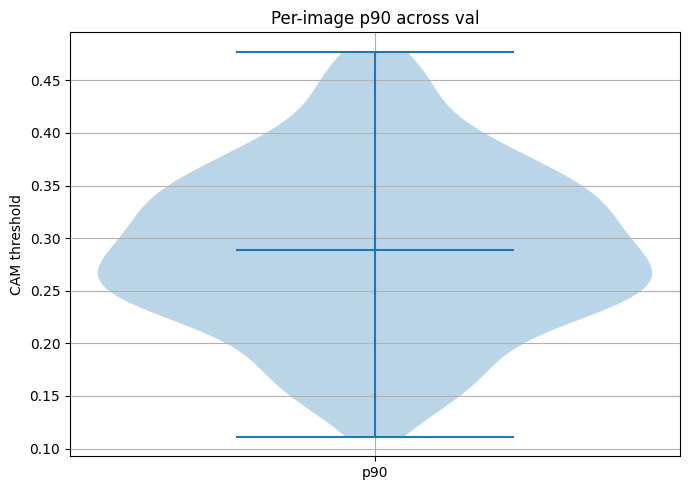

Per-image p90: mean=0.2892, std=0.0792, q25=0.2374, median=0.2844, q75=0.3434


In [ ]:
# assuming you already have CAMs in padded space for val:
# cams_val, boxes_val, pad_sizes_val, probs_val = compute_cams_for_set(val_df, image_dict, info_dict, device, gradcam_helper)

# 1) Histograms (overall and CC/MLO overlay)
plot_cam_histograms(cams_val, df=val_df, bins=100, overlay_cc_mlo=True, title="Val CAM distributions")

# 2) CDF with percentiles (prints numeric thresholds)
#plot_cam_cdf_with_percentiles(cams_val, df=val_df, percentiles=(80,90,95), title="Val CAM CDF")

# 3) Per-image p-th percentile distribution
plot_per_image_percentile_distribution(cams_val, val_df, p=90, kind='violin', title="Per-image p90 across val")



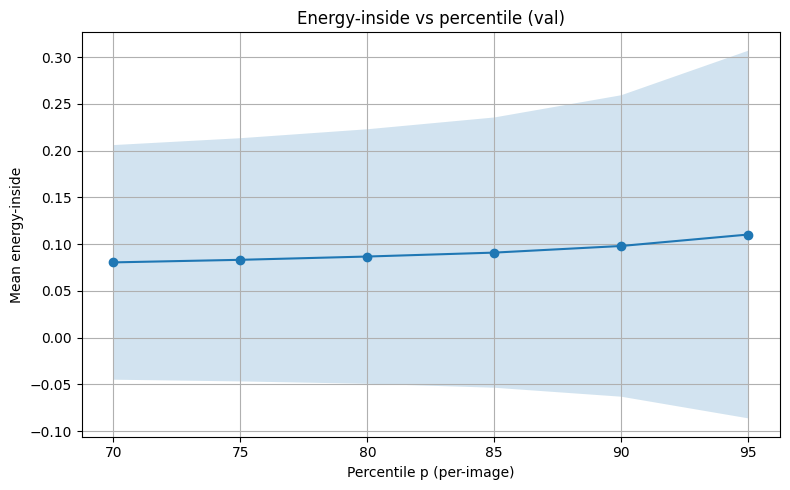

   percentile  mean_frac  std_frac    n
0          70   0.080397  0.125463  117
1          75   0.083149  0.130069  117
2          80   0.086664  0.136117  117
3          85   0.090857  0.144529  117
4          90   0.097957  0.161217  117
5          95   0.110194  0.196598  117


In [ ]:
# 4) (Optional) Sweep p to pick a sensible default for τ policy
df_sweep = sweep_percentiles_for_fraction_inside(cams_val, boxes_val, val_df, percentiles=range(70,100,5))
plot_sweep(df_sweep, title="Energy-inside vs percentile (val)")
print(df_sweep)


# livia metrics

Number of unique image IDs in test_df: 250
Number of unique image IDs in bbox_dict: 1753
Number of image IDs in test_df missing from bbox_dict: 135


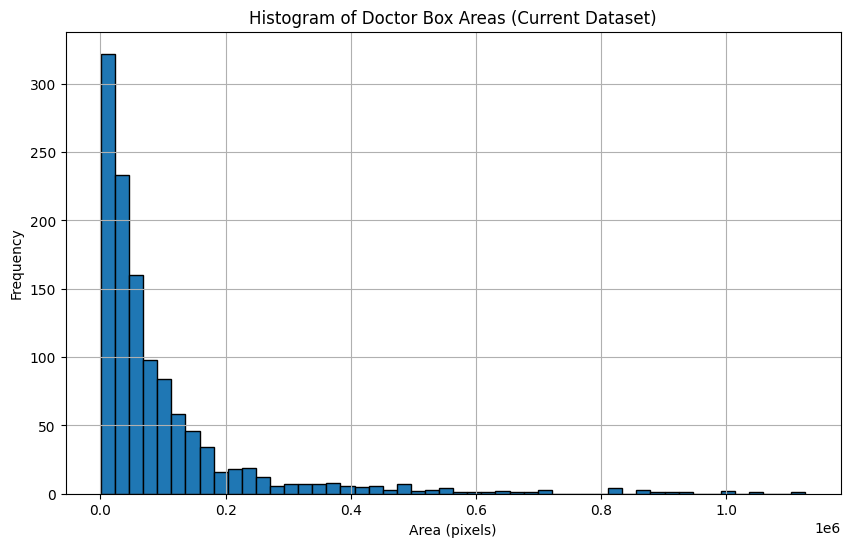

In [ ]:
# Check which image IDs from test_df are not in bbox_dict

test_image_ids = set(test_df['CC'].tolist() + test_df['MLO'].tolist())
bbox_image_ids = set(bbox_dict.keys())

missing_image_ids = test_image_ids - bbox_image_ids

print(f"Number of unique image IDs in test_df: {len(test_image_ids)}")
print(f"Number of unique image IDs in bbox_dict: {len(bbox_image_ids)}")
print(f"Number of image IDs in test_df missing from bbox_dict: {len(missing_image_ids)}")

# Calculate the area of each doctor box and store them
box_areas = []

# Get the set of image IDs in the current dataset
dataset_image_ids = set(dataset['CC'].tolist() + dataset['MLO'].tolist())

for image_id, box_info in bbox_dict.items():
    # Only consider image IDs that are in the current dataset
    if image_id in dataset_image_ids:
        x_min, y_min, x_max, y_max = box_info['bbox']
        width = x_max - x_min
        height = y_max - y_min
        area = width * height
        box_areas.append(area)

# Plot a histogram of the box areas
plt.figure(figsize=(10, 6))
plt.hist(box_areas, bins=50, edgecolor='black')
plt.title("Histogram of Doctor Box Areas (Current Dataset)")
plt.xlabel("Area (pixels)")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

Number of images in the filtered test set with a valid doctor box AND large area: 4
➡️  FILTERED_TEST_LARGE_BOX | Positives: 4 | With bbox: 4


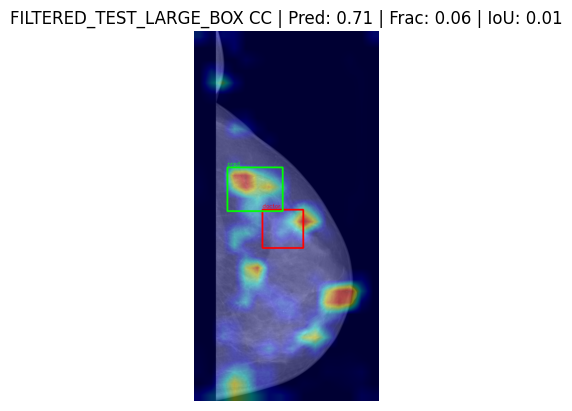

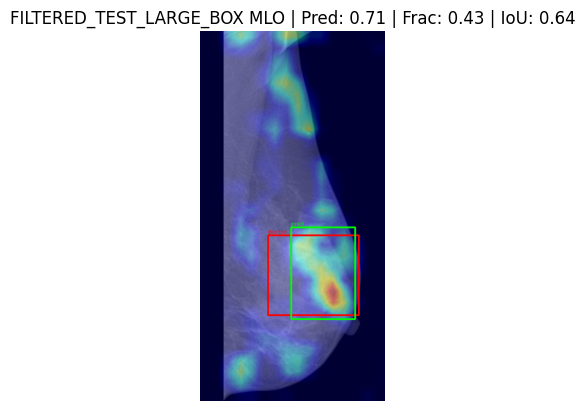

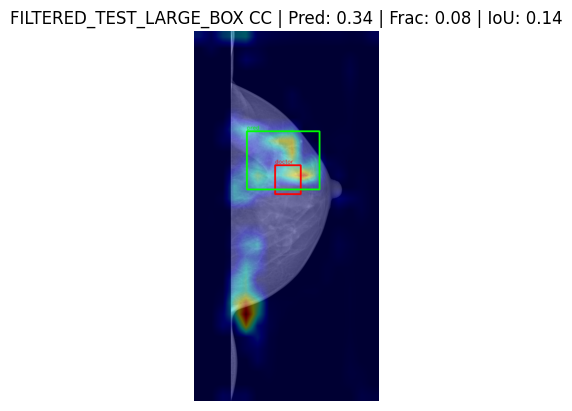

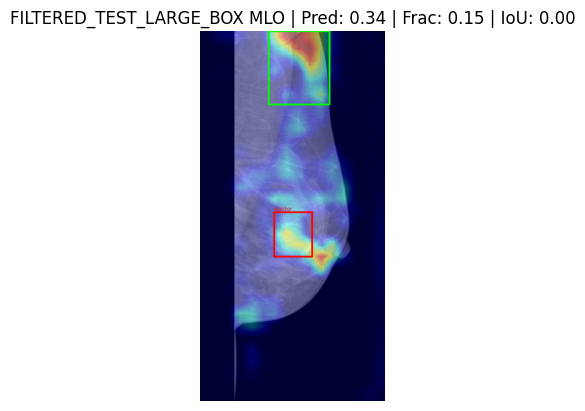

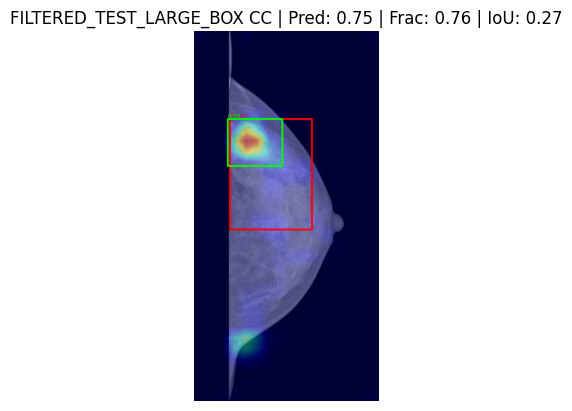

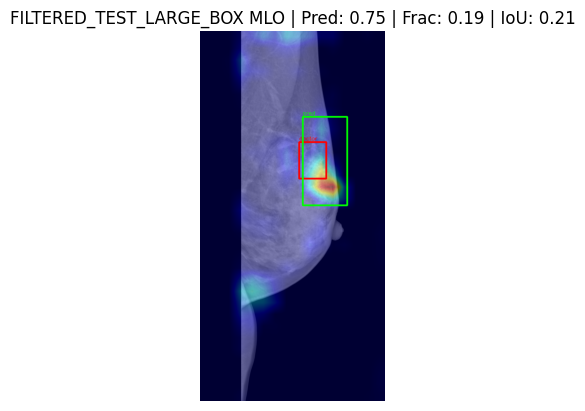

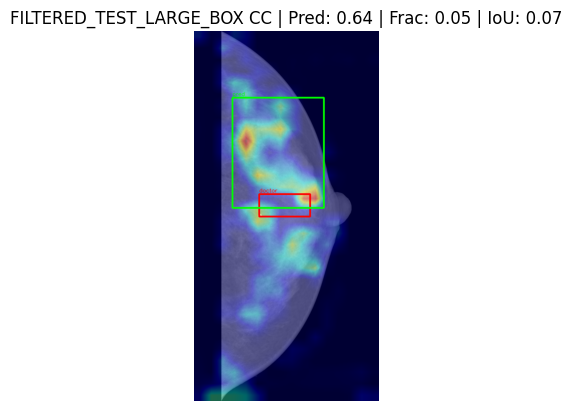

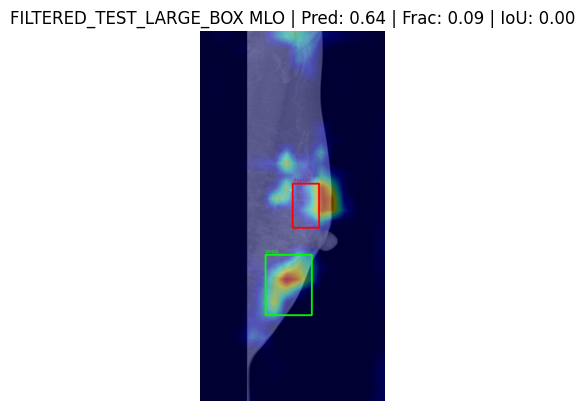

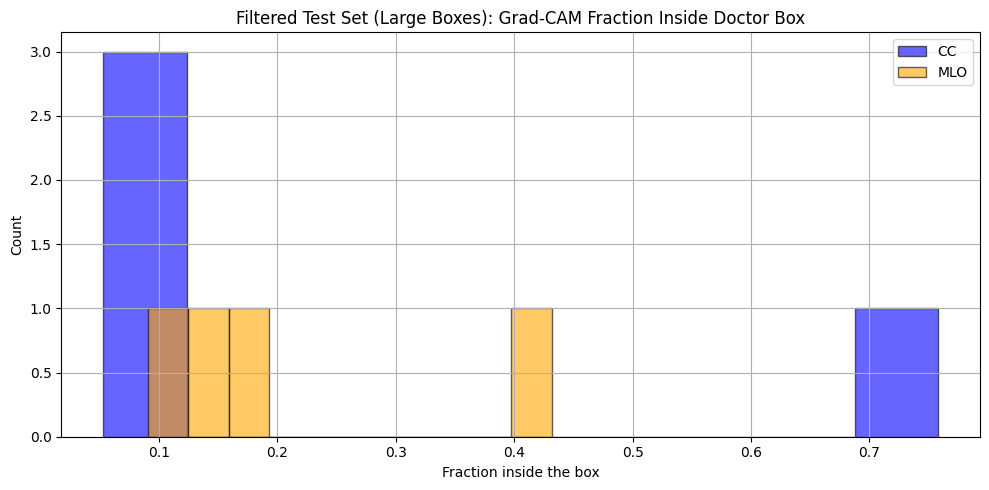

Number of images in the filtered test set (true label 1 and predicted label 1): 5
➡️  TRUE_POSITIVES_TEST | Positives: 5 | With bbox: 5


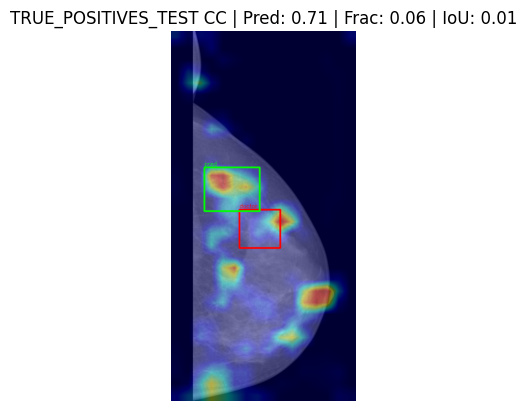

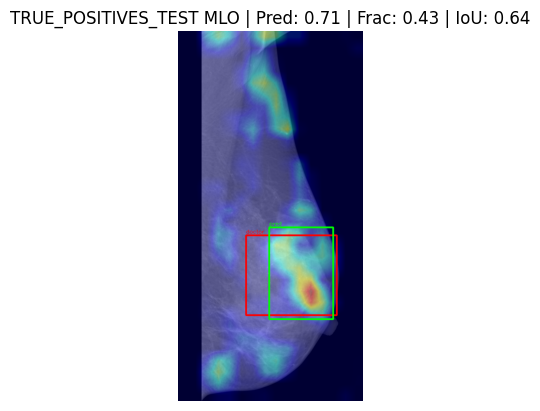

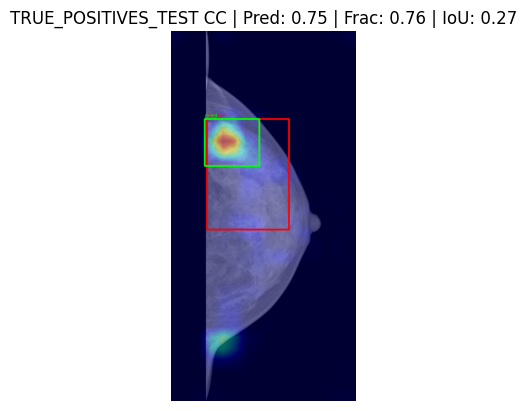

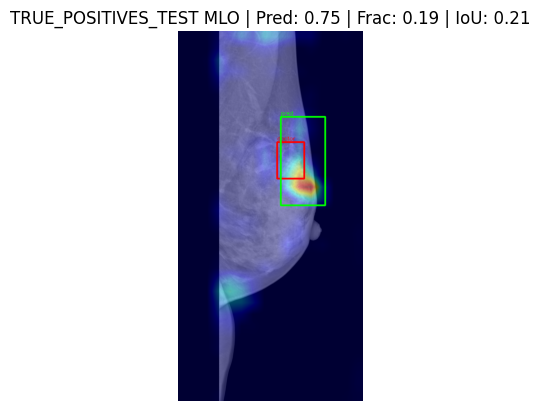

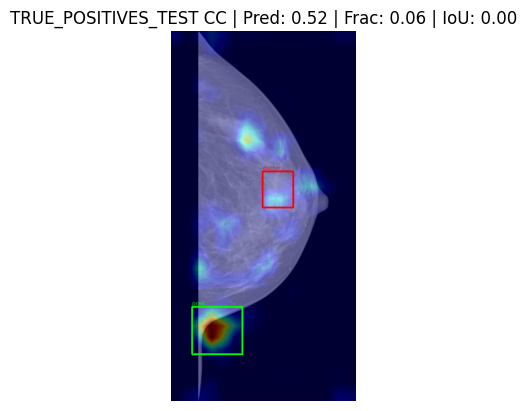

...

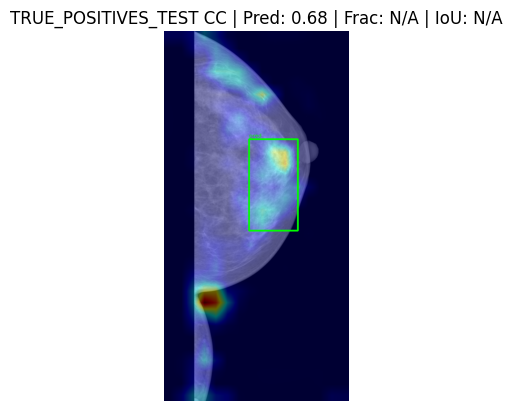

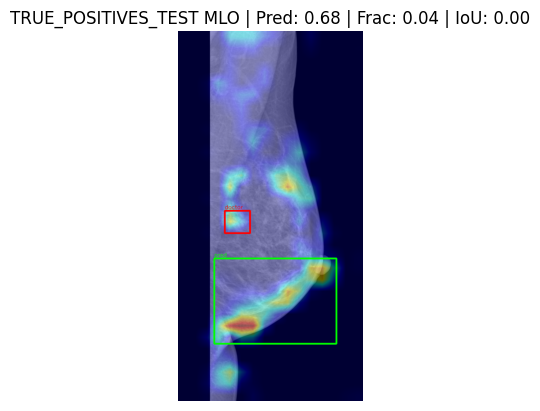

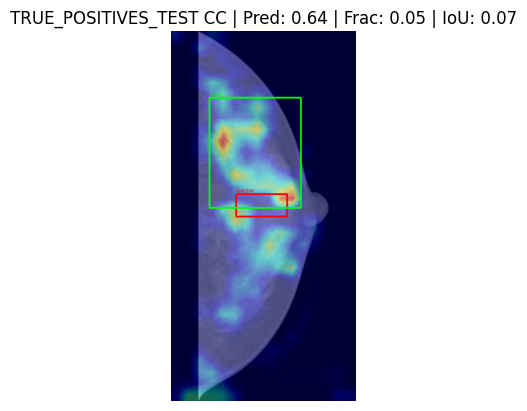

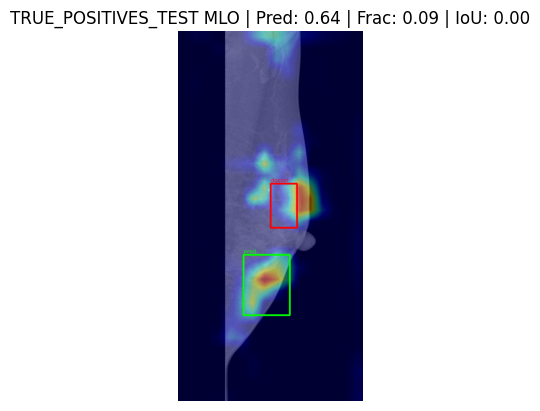

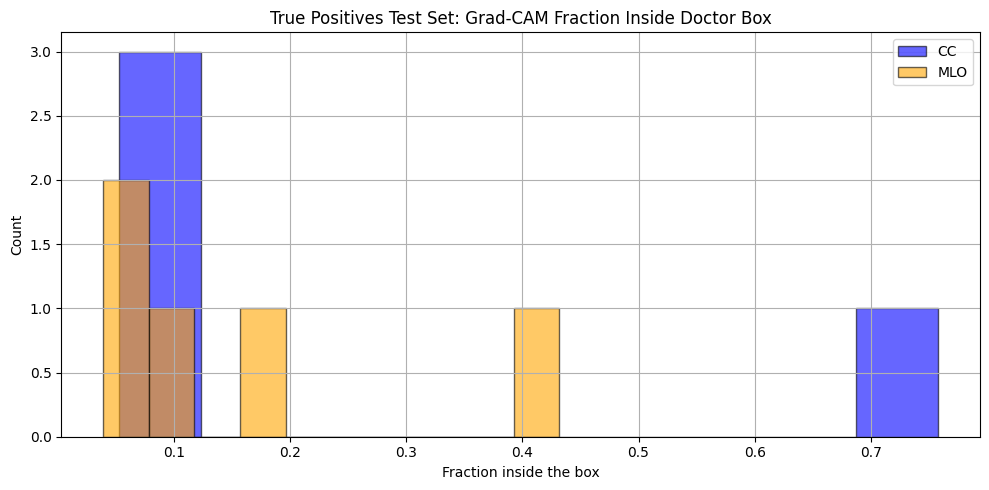

In [ ]:
# Filter the test set to include only images with a valid Grad-CAM fraction inside the doctor box (meaning they had a bbox)
test_df_filtered_large_box = test_df[
    test_df.apply(
        lambda row:
        (row['CC'] in df_test_results['cc_id'].tolist() and
         df_test_results[df_test_results['cc_id'] == row['CC']]['cc_fraction_in'].iloc[0] is not None) or
        (row['MLO'] in df_test_results['mlo_id'].tolist() and
         df_test_results[df_test_results['mlo_id'] == row['MLO']]['mlo_fraction_in'].iloc[0] is not None),
        axis=1
    )
].reset_index(drop=True)

# Calculate the area of the original doctor box and add it to the filtered dataframe
def calculate_original_box_area(row, bbox_dict):
    cc_id = row['CC']
    mlo_id = row['MLO']
    cc_area = None
    mlo_area = None

    if cc_id in bbox_dict:
        x_min, y_min, x_max, y_max = bbox_dict[cc_id]['bbox']
        cc_area = (x_max - x_min) * (y_max - y_min)

    if mlo_id in bbox_dict:
        x_min, y_min, x_max, y_max = bbox_dict[mlo_id]['bbox']
        mlo_area = (x_max - x_min) * (y_max - y_min)

    return cc_area, mlo_area

test_df_filtered_large_box[['cc_original_area', 'mlo_original_area']] = test_df_filtered_large_box.apply(
    lambda row: pd.Series(calculate_original_box_area(row, bbox_dict)), axis=1
)

# Filter based on large box area (area > 100000)
# Since a pair can have one large and one small box, we filter if *either* has a large box
test_df_filtered_large_box = test_df_filtered_large_box[
    (test_df_filtered_large_box['cc_original_area'] > 100000) |
    (test_df_filtered_large_box['mlo_original_area'] > 100000)
].reset_index(drop=True)


print(f"Number of images in the filtered test set with a valid doctor box AND large area: {len(test_df_filtered_large_box)}")

# Evaluate and visualize Grad-CAM for the filtered test set
df_test_results_filtered_large_box = evaluate_and_visualize_gradcam_padded(
    model, test_df_filtered_large_box, image_dict, info_dict, bbox_dict,
    device, gradcam_helper,
    dataset_name="filtered_test_large_box", max_images_to_show=10,
    mass_ratio_for_cam_box=0.5, frac_threshold=0.2, show=True
)

# Plot the fraction inside the doctor box for the filtered results
plot_view_fractions(df_test_results_filtered_large_box, cc_column="cc_fraction_in", mlo_column="mlo_fraction_in", title= "Filtered Test Set (Large Boxes): Grad-CAM Fraction Inside Doctor Box")

# Filter the test set to include only images with true label 1 and predicted label 1
# We need the original test_df to get image IDs and other info, and df_test_results for predictions
test_df_positive_predicted_positive = test_df[
    test_df['CC'].isin(df_test_results[df_test_results['prediction'] >= 0.5]['cc_id'].tolist()) |
    test_df['MLO'].isin(df_test_results[df_test_results['prediction'] >= 0.5]['mlo_id'].tolist())
].reset_index(drop=True)


print(f"Number of images in the filtered test set (true label 1 and predicted label 1): {len(test_df_positive_predicted_positive)}")

# Evaluate and visualize Grad-CAM for the filtered test set
df_test_results_positive_predicted_positive = evaluate_and_visualize_gradcam_padded(
    model, test_df_positive_predicted_positive, image_dict, info_dict, bbox_dict,
    device, gradcam_helper,
    dataset_name="true_positives_test", max_images_to_show=10,
    mass_ratio_for_cam_box=0.5, frac_threshold=0.2, show=True
)


# Plot the fraction inside the doctor box for the filtered results
plot_view_fractions(df_test_results_positive_predicted_positive, cc_column="cc_fraction_in", mlo_column="mlo_fraction_in", title= "True Positives Test Set: Grad-CAM Fraction Inside Doctor Box")

Number of images in the filtered test set with a valid doctor box AND large area: 10
➡️  FILTERED_TEST_LARGE_BOX | Positives: 10 | With bbox: 10


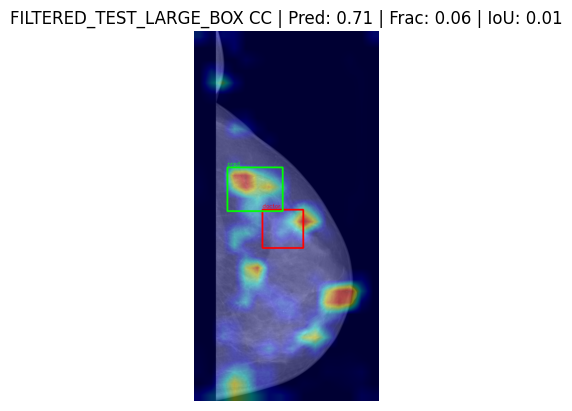

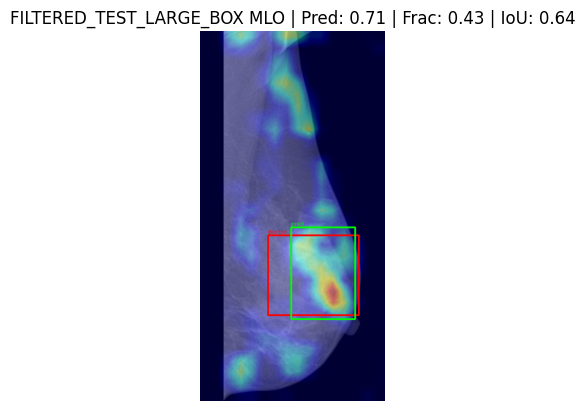

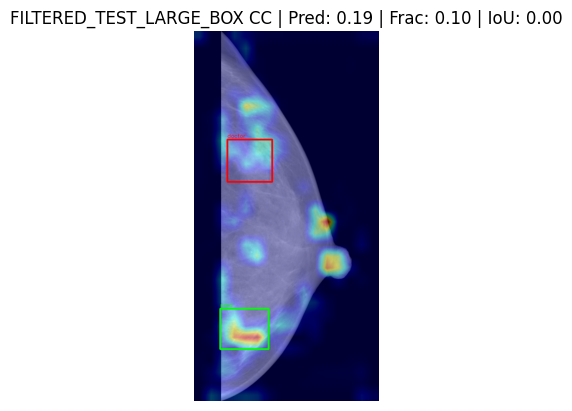

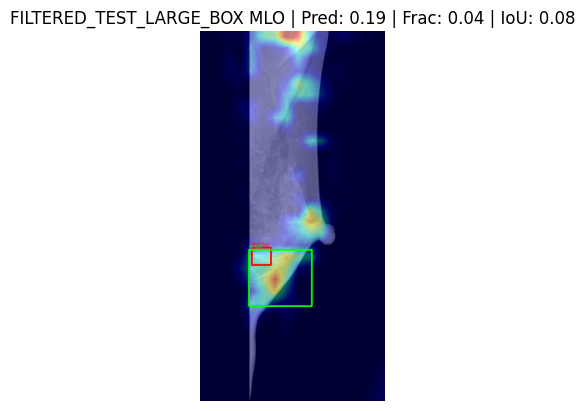

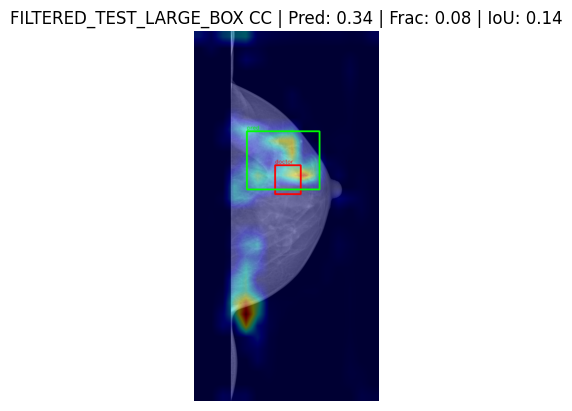

...

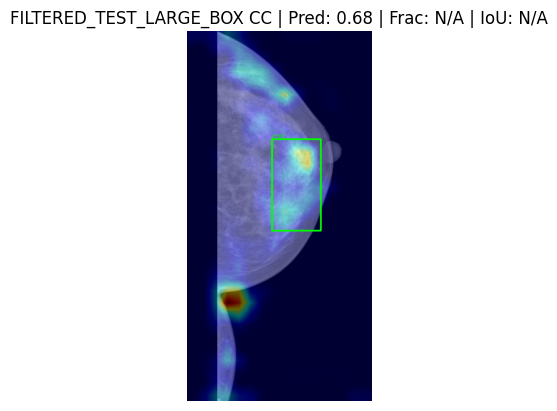

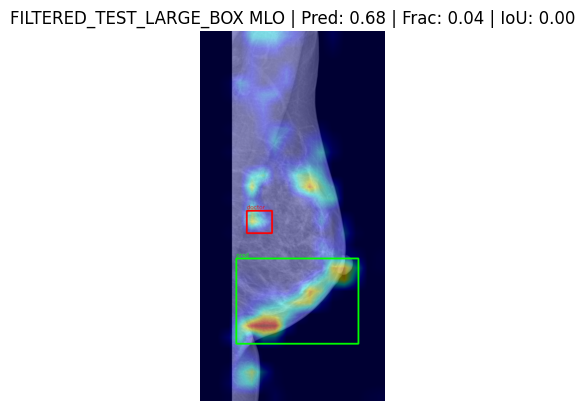

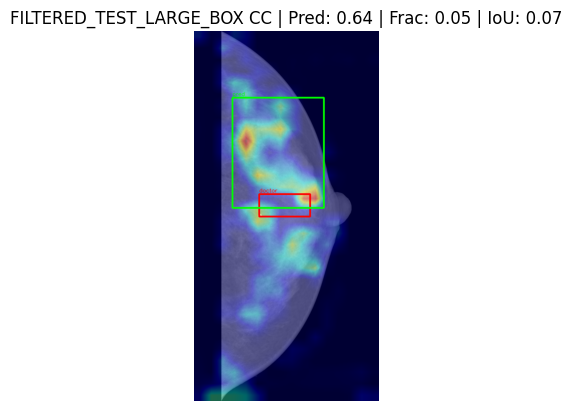

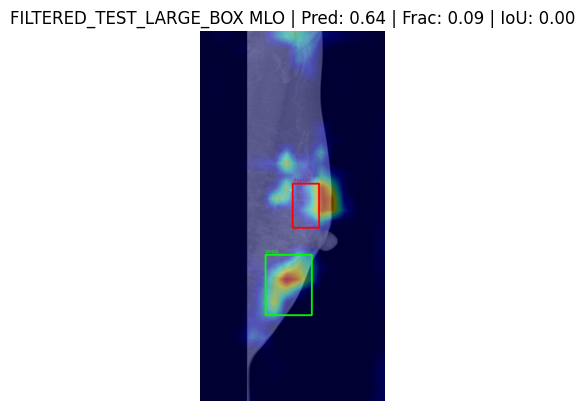

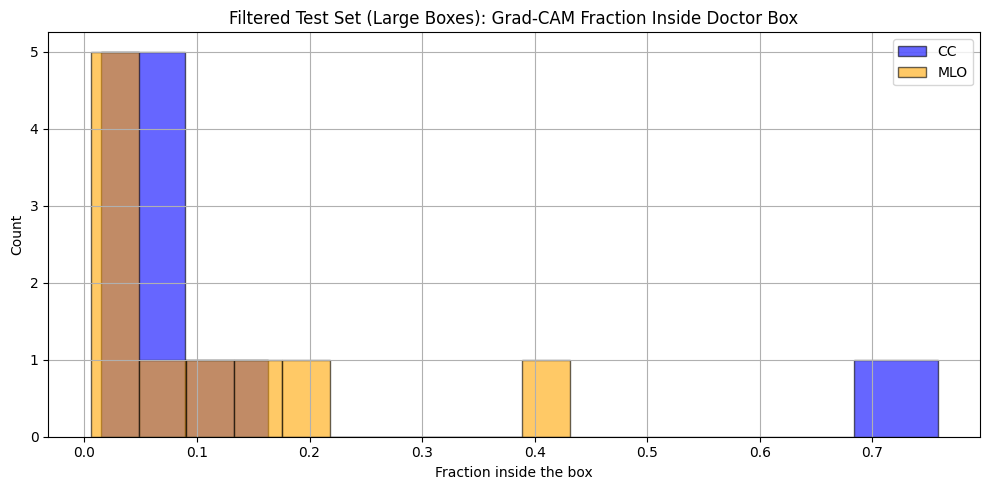

In [ ]:
# Filter the test set to include only images with a valid Grad-CAM fraction inside the doctor box (meaning they had a bbox)
test_df_filtered_large_box = test_df[
    test_df.apply(
        lambda row:
        (row['CC'] in df_test_results['cc_id'].tolist() and
         df_test_results[df_test_results['cc_id'] == row['CC']]['cc_fraction_in'].iloc[0] is not None) or
        (row['MLO'] in df_test_results['mlo_id'].tolist() and
         df_test_results[df_test_results['mlo_id'] == row['MLO']]['mlo_fraction_in'].iloc[0] is not None),
        axis=1
    )
].reset_index(drop=True)

# Calculate the area of the original doctor box and add it to the filtered dataframe
def calculate_original_box_area(row, bbox_dict):
    cc_id = row['CC']
    mlo_id = row['MLO']
    cc_area = None
    mlo_area = None

    if cc_id in bbox_dict:
        x_min, y_min, x_max, y_max = bbox_dict[cc_id]['bbox']
        cc_area = (x_max - x_min) * (y_max - y_min)

    if mlo_id in bbox_dict:
        x_min, y_min, x_max, y_max = bbox_dict[mlo_id]['bbox']
        mlo_area = (x_max - x_min) * (y_max - y_min)

    return cc_area, mlo_area

test_df_filtered_large_box[['cc_original_area', 'mlo_original_area']] = test_df_filtered_large_box.apply(
    lambda row: pd.Series(calculate_original_box_area(row, bbox_dict)), axis=1
)

# Filter based on large box area (area > 0.9)
# Since a pair can have one large and one small box, we filter if *either* has a large box
test_df_filtered_large_box = test_df_filtered_large_box[
    (test_df_filtered_large_box['cc_original_area'] > 0.9) |
    (test_df_filtered_large_box['mlo_original_area'] > 0.9)
].reset_index(drop=True)


print(f"Number of images in the filtered test set with a valid doctor box AND large area: {len(test_df_filtered_large_box)}")

# Evaluate and visualize Grad-CAM for the filtered test set
df_test_results_filtered_large_box = evaluate_and_visualize_gradcam_padded(
    model, test_df_filtered_large_box, image_dict, info_dict, bbox_dict,
    device, gradcam_helper,
    dataset_name="filtered_test_large_box", max_images_to_show=10,
    mass_ratio_for_cam_box=0.5, frac_threshold=0.2, show=True
)

# Plot the fraction inside the doctor box for the filtered results
plot_view_fractions(df_test_results_filtered_large_box, cc_column="cc_fraction_in", mlo_column="mlo_fraction_in", title= "Filtered Test Set (Large Boxes): Grad-CAM Fraction Inside Doctor Box")

--- Train Set ---

Showing up to 10 images where a doctor box contains Grad-CAM pixel value > 0.9:


/tmp/ipykernel_2751977/3129632091.py:64: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = get_cmap('coolwarm')


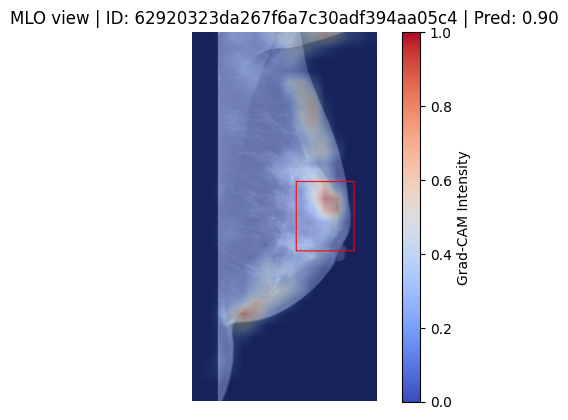

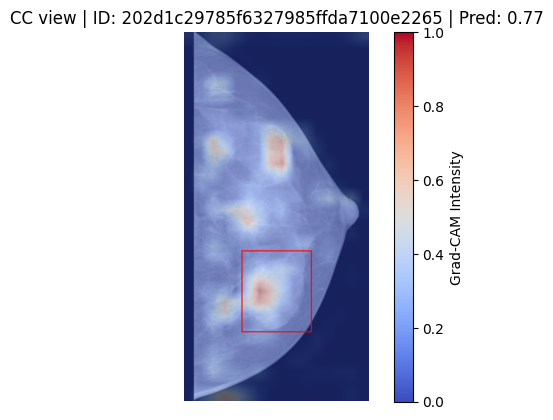

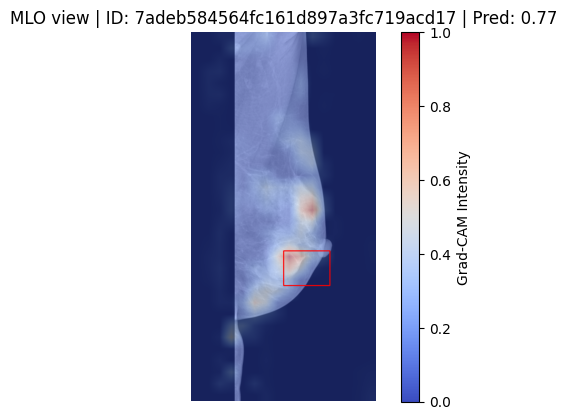

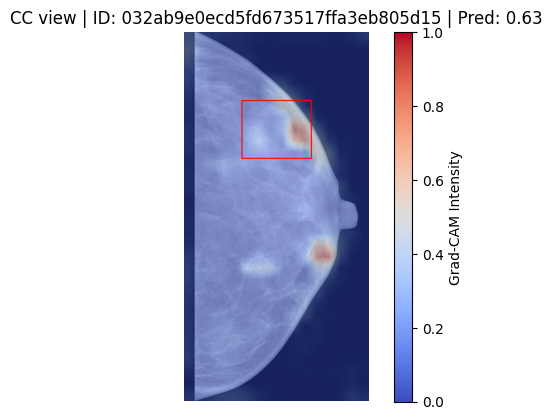

Number of doctor boxes with Grad-CAM pixel value > 0.9 in Train set: 4

--- Validation Set ---

Showing up to 10 images where a doctor box contains Grad-CAM pixel value > 0.9:


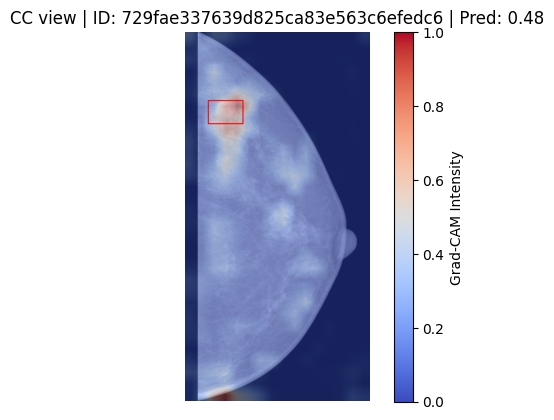

Number of doctor boxes with Grad-CAM pixel value > 0.9 in Validation set: 1

--- Test Set ---

Showing up to 10 images where a doctor box contains Grad-CAM pixel value > 0.9:


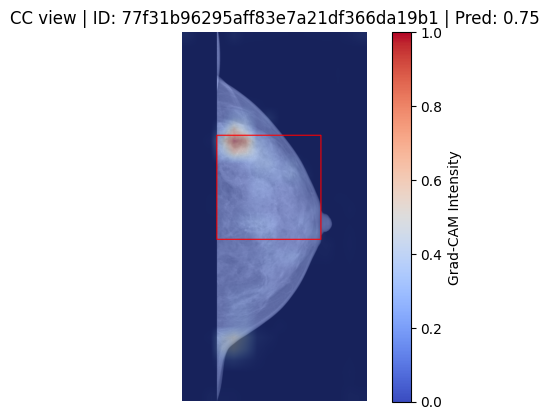

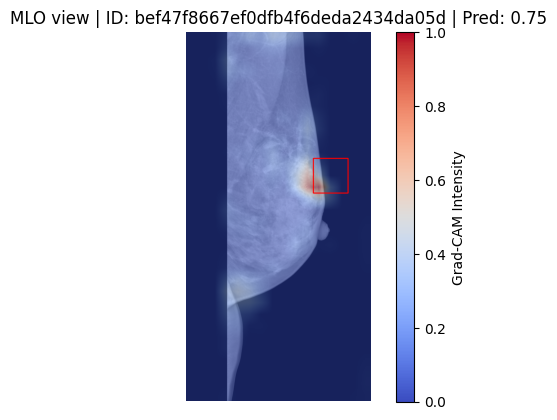

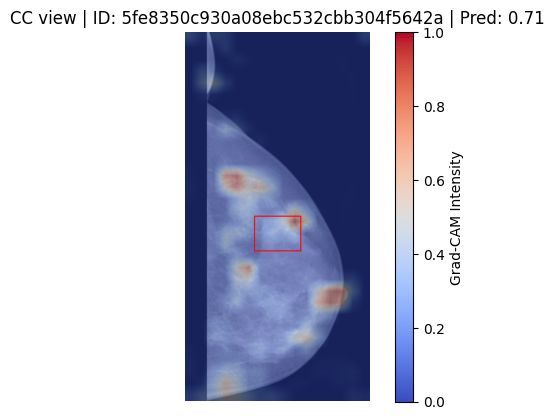

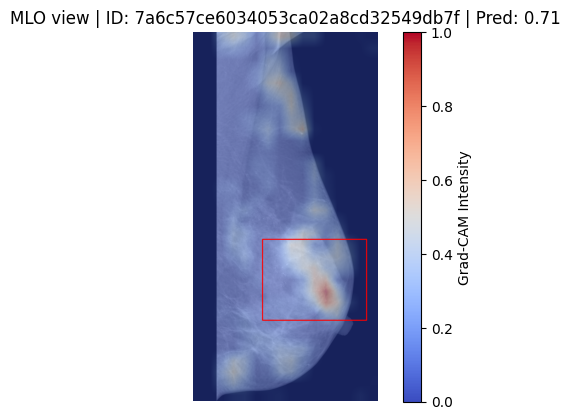

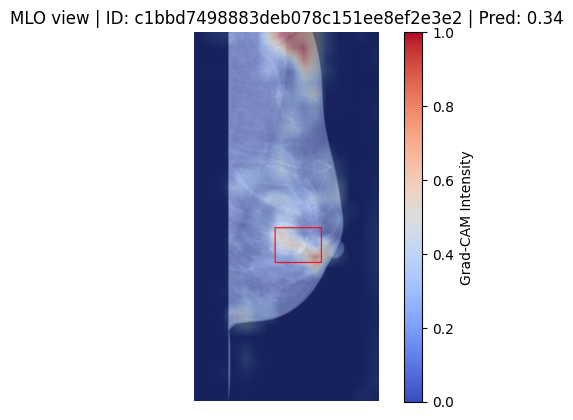

Number of doctor boxes with Grad-CAM pixel value > 0.9 in Test set: 5


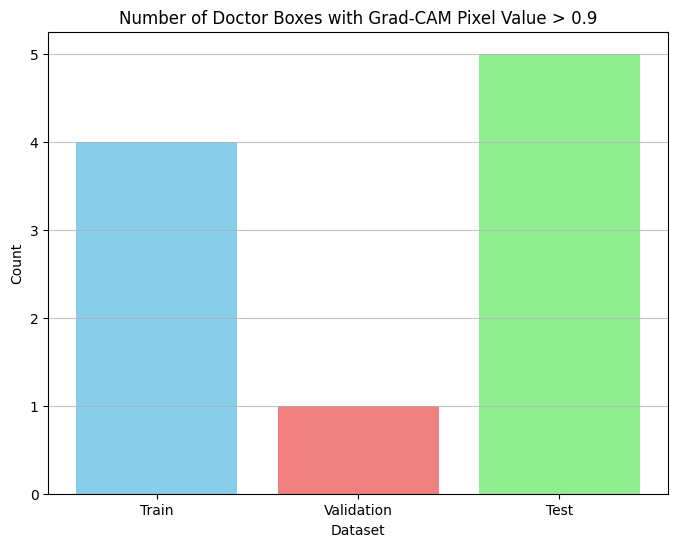

KeyError: 'label'

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def transform_doctor_box(bbox, orig_size, crop_box, pad, heatmap_size, flip=False):
    x_min, y_min, x_max, y_max = bbox
    orig_w, orig_h = orig_size

    # === Flip box in original space before anything else ===
    if flip:
        x_min, x_max = orig_w - x_max, orig_w - x_min

    # Proceed with crop, pad, resize
    cx1, cy1, cx2, cy2 = crop_box
    pad_top, pad_bottom, pad_left, pad_right = pad
    heatmap_w, heatmap_h = heatmap_size

    # Apply crop
    x_min -= cx1
    x_max -= cx1
    y_min -= cy1
    y_max -= cy1

    # Apply padding
    x_min += pad_left
    x_max += pad_left
    y_min += pad_top
    y_max += pad_top

    # Resize to heatmap size
    padded_w = (cx2 - cx1) + pad_left + pad_right
    padded_h = (cy2 - cy1) + pad_top + pad_bottom

    scale_x = heatmap_w / padded_w
    scale_y = heatmap_h / padded_h

    x_min = int(x_min * scale_x)
    x_max = int(x_max * scale_x)
    y_min = int(y_min * scale_y)
    y_max = int(y_max * scale_y)

    # Clamp
    x_min = max(0, x_min)
    y_min = max(0, y_min)
    x_max = min(heatmap_w, x_max)
    y_max = min(heatmap_h, y_max)

    return (x_min, y_min, x_max, y_max)

from matplotlib.cm import get_cmap
from matplotlib.colors import Normalize

def show_overlay_with_bboxes_old(image_tensor, cam, doctor_box=None, title="Grad-CAM + BBoxes"):
    fig, ax = plt.subplots()
    img = image_tensor.squeeze().cpu().numpy()
    if img.ndim == 3 and img.shape[0] == 3:
        img = np.transpose(img, (1, 2, 0))
    elif img.ndim == 2:
        img = np.expand_dims(img, -1)
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    cam_resized = cv2.resize(cam, (img.shape[1], img.shape[0]))

    # Use coolwarm colormap for heatmap (blue to red)
    cmap = get_cmap('coolwarm')
    norm = Normalize(vmin=0, vmax=1)
    heatmap = cmap(norm(cam_resized))[..., :3] # Get RGB channels

    if img.shape[-1] == 1:
        img = np.repeat(img, 3, axis=-1)
    overlay = np.clip(0.4 * heatmap + 0.6 * img, 0, 1)
    overlay = np.uint8(255 * overlay)

    if doctor_box:
        # Scale doctor_box back to image display size for visualization
        heatmap_h, heatmap_w = cam.shape # Heatmap shape is (H, W)
        img_h, img_w = img.shape[:2]

        scale_x = img_w / heatmap_w
        scale_y = img_h / heatmap_h

        display_box = (
            int(doctor_box[0] * scale_x),
            int(doctor_box[1] * scale_y),
            int(doctor_box[2] * scale_x),
            int(doctor_box[3] * scale_y)
        )

        cv2.rectangle(overlay, display_box[:2], display_box[2:], (255, 0, 0), 2)

    im = ax.imshow(overlay)
    ax.set_title(title)
    ax.axis("off")

    # Add color bar
    cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax)
    cbar.set_label('Grad-CAM Intensity')

    plt.show()

def count_boxes_with_high_gradcam_and_show(df_results, image_dict, info_dict, bbox_dict, model, device, threshold=0.9, max_images_to_show=10):
    """
    Counts the number of doctor boxes (CC or MLO) that contain at least one
    Grad-CAM pixel value greater than the specified threshold and shows the corresponding images.

    Args:
        df_results (pd.DataFrame): DataFrame containing 'cc_id', 'mlo_id', and 'laterality'.
        image_dict (dict): {(cc_id, mlo_id): (cc_image, mlo_image)}
        info_dict (dict): {(cc_id, mlo_id): (info_cc, info_mlo)}
        bbox_dict (dict): {image_id: {"orig_size": (w, h), "bbox": (xmin, ymin, xmax, ymax)}}
        model (torch.nn.Module): The trained model.
        device (torch.device): The device the model is on.
        threshold (float): The threshold for the Grad-CAM pixel value.
        max_images_to_show (int): Maximum number of images to display.

    Returns:
        int: The number of boxes meeting the criterion.
    """
    count = 0
    images_to_show = []

    for index, row in df_results.iterrows():
        cc_id, mlo_id = row['cc_id'], row['mlo_id']
        laterality = row['laterality']
        pred = row['prediction'] # Get prediction from df_results

        try:
            cc_img_np, mlo_img_np = image_dict[(cc_id, mlo_id)]
            cc_tensor = torch.from_numpy(np.clip(cc_img_np, 0, train_pixel_max) / train_pixel_max).unsqueeze(0)
            mlo_tensor = torch.from_numpy(np.clip(mlo_img_np, 0, train_pixel_max) / train_pixel_max).unsqueeze(0)
            cc_tensor = cc_tensor.expand(3, -1, -1).unsqueeze(0).to(device)
            mlo_tensor = mlo_tensor.expand(3, -1, -1).unsqueeze(0).to(device)

            effnet_mean_t = torch.tensor(effnet_mean).view(1, 3, 1, 1).to(device)
            effnet_std_t = torch.tensor(effnet_std).view(1, 3, 1, 1).to(device)
            cc_tensor = (cc_tensor - effnet_mean_t) / effnet_std_t
            mlo_tensor = (mlo_tensor - effnet_mean_t) / effnet_std_t

        except KeyError:
            continue # Skip if image data is missing


        with torch.enable_grad():
            cc_cam, mlo_cam, prob = compute_gradcam(model, cc_tensor, mlo_tensor, device, gradcam_helper)


        try:
            info_cc, info_mlo = info_dict[(cc_id, mlo_id)]
        except KeyError:
            continue # Skip if info is missing

        cc_info = bbox_dict.get(cc_id)
        mlo_info = bbox_dict.get(mlo_id)

        # Check CC box
        cc_box_meets_threshold = False
        if cc_info:
            cc_doctor_box_heatmap = transform_doctor_box(
                cc_info["bbox"], cc_info["orig_size"], info_cc["crop_box"],
                info_cc["pad"], cc_cam.shape[::-1], flip=(laterality == "R")
            )
            x_min, y_min, x_max, y_max = cc_doctor_box_heatmap
            if x_min < x_max and y_min < y_max: # Check for valid box
                cam_inside_box = cc_cam[y_min:y_max, x_min:x_max]
                if np.any(cam_inside_box > threshold):
                    count += 1
                    cc_box_meets_threshold = True
                    images_to_show.append({
                        "view": "CC",
                        "image_tensor": cc_tensor,
                        "cam": cc_cam,
                        "doctor_box": cc_doctor_box_heatmap,
                        "id": cc_id,
                        "pred": pred
                    })


        # Check MLO box
        mlo_box_meets_threshold = False
        if mlo_info:
            mlo_doctor_box_heatmap = transform_doctor_box(
                mlo_info["bbox"], mlo_info["orig_size"], info_mlo["crop_box"],
                info_mlo["pad"], mlo_cam.shape[::-1], flip=(laterality == "R")
            )
            x_min, y_min, x_max, y_max = mlo_doctor_box_heatmap
            if x_min < x_max and y_min < y_max: # Check for valid box
                cam_inside_box = mlo_cam[y_min:y_max, x_min:x_max]
                if np.any(cam_inside_box > threshold):
                    count += 1
                    mlo_box_meets_threshold = True
                    images_to_show.append({
                        "view": "MLO",
                        "image_tensor": mlo_tensor,
                        "cam": mlo_cam,
                        "doctor_box": mlo_doctor_box_heatmap,
                        "id": mlo_id,
                        "pred": pred
                    })

    # Sort images to show by prediction score
    images_to_show = sorted(images_to_show, key=lambda x: -x["pred"])

    # Show the images
    print(f"\nShowing up to {max_images_to_show} images where a doctor box contains Grad-CAM pixel value > {threshold}:")
    for i, img_info in enumerate(images_to_show[:max_images_to_show]):
        show_overlay_with_bboxes_old(
            img_info["image_tensor"], img_info["cam"],
            doctor_box=img_info["doctor_box"],
            title=f"{img_info['view']} view | ID: {img_info['id']} | Pred: {img_info['pred']:.2f}"
        )


    return count


# Calculate counts and show images for each dataset
print("--- Train Set ---")
train_high_gradcam_count = count_boxes_with_high_gradcam_and_show(df_train_results, image_dict, info_dict, bbox_dict, model, device)
print(f"Number of doctor boxes with Grad-CAM pixel value > 0.9 in Train set: {train_high_gradcam_count}")

print("\n--- Validation Set ---")
val_high_gradcam_count = count_boxes_with_high_gradcam_and_show(df_val_results, image_dict, info_dict, bbox_dict, model, device)
print(f"Number of doctor boxes with Grad-CAM pixel value > 0.9 in Validation set: {val_high_gradcam_count}")

print("\n--- Test Set ---")
test_high_gradcam_count = count_boxes_with_high_gradcam_and_show(df_test_results, image_dict, info_dict, bbox_dict, model, device)
print(f"Number of doctor boxes with Grad-CAM pixel value > 0.9 in Test set: {test_high_gradcam_count}")


# Create a bar chart (using the counts calculated above)
labels = ['Train', 'Validation', 'Test']
counts = [train_high_gradcam_count, val_high_gradcam_count, test_high_gradcam_count]

plt.figure(figsize=(8, 6))
plt.bar(labels, counts, color=['skyblue', 'lightcoral', 'lightgreen'])
plt.title('Number of Doctor Boxes with Grad-CAM Pixel Value > 0.9')
plt.xlabel('Dataset')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.75)
plt.show()

# Filter train results for true positives and false negatives
df_train_true_positives = df_train_results[(df_train_results['label'] == 1) & (df_train_results['prediction'] >= 0.5)].reset_index(drop=True)
df_train_false_negatives = df_train_results[(df_train_results['label'] == 1) & (df_train_results['prediction'] < 0.5)].reset_index(drop=True)

print(f"--- Train Set True Positives (Threshold 0.9) ---")
train_tp_high_gradcam_count = count_boxes_with_high_gradcam_and_show(df_train_true_positives, image_dict, info_dict, bbox_dict, model, device, threshold=0.9, max_images_to_show=5)
print(f"Number of doctor boxes with Grad-CAM pixel value > 0.9 in Train True Positives: {train_tp_high_gradcam_count}")

print(f"\n--- Train Set False Negatives (Threshold 0.9) ---")
train_fn_high_gradcam_count = count_boxes_with_high_gradcam_and_show(df_train_false_negatives, image_dict, info_dict, bbox_dict, model, device, threshold=0.9, max_images_to_show=5)
print(f"Number of doctor boxes with Grad-CAM pixel value > 0.9 in Train False Negatives: {train_fn_high_gradcam_count}")

# Create a bar chart
labels = ['Train True Positives (0.9)', 'Train False Negatives (0.9)']
counts = [train_tp_high_gradcam_count, train_fn_high_gradcam_count]

plt.figure(figsize=(8, 6))
plt.bar(labels, counts, color=['lightgreen', 'salmon'])
plt.title('Doctor Boxes with Grad-CAM Pixel Value > 0.9 in Train Set')
plt.xlabel('Category')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.75)
plt.show()

print(f"\n--- Train Set True Positives (Threshold 0.6) ---")
train_tp_high_gradcam_count_0_6 = count_boxes_with_high_gradcam_and_show(df_train_true_positives, image_dict, info_dict, bbox_dict, model, device, threshold=0.6, max_images_to_show=5)
print(f"Number of doctor boxes with Grad-CAM pixel value > 0.6 in Train True Positives: {train_tp_high_gradcam_count_0_6}")

print(f"\n--- Train Set False Negatives (Threshold 0.6) ---")
train_fn_high_gradcam_count_0_6 = count_boxes_with_high_gradcam_and_show(df_train_false_negatives, image_dict, info_dict, bbox_dict, model, device, threshold=0.6, max_images_to_show=5)
print(f"Number of doctor boxes with Grad-CAM pixel value > 0.6 in Train False Negatives: {train_fn_high_gradcam_count_0_6}")

# Create a bar chart
labels_0_6 = ['Train True Positives (0.6)', 'Train False Negatives (0.6)']
counts_0_6 = [train_tp_high_gradcam_count_0_6, train_fn_high_gradcam_count_0_6]

plt.figure(figsize=(8, 6))
plt.bar(labels_0_6, counts_0_6, color=['lightgreen', 'salmon'])
plt.title('Doctor Boxes with Grad-CAM Pixel Value > 0.6 in Train Set')
plt.xlabel('Category')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.75)
plt.show()

# CAPTUM

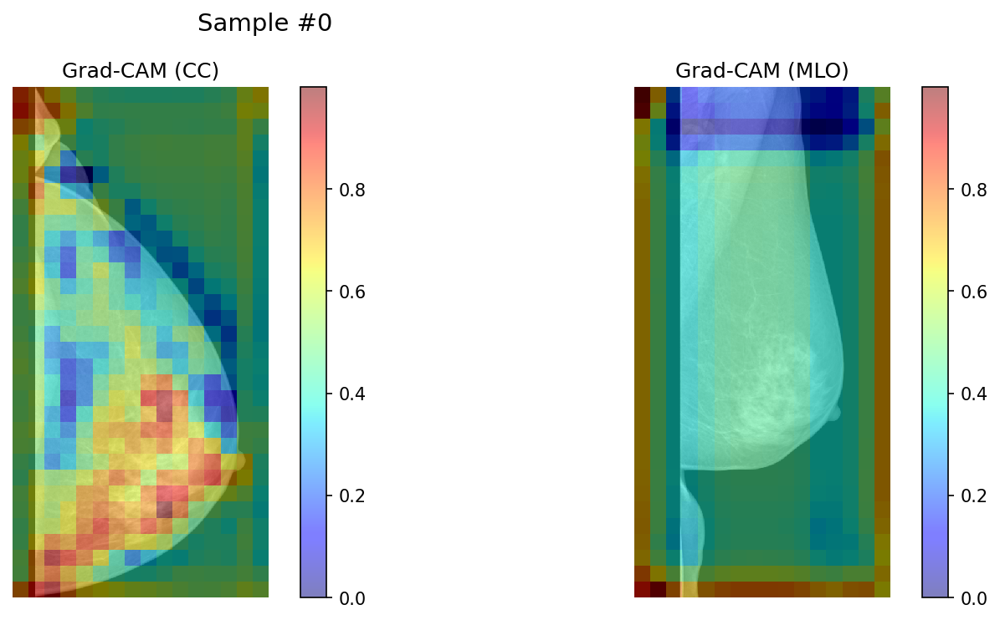

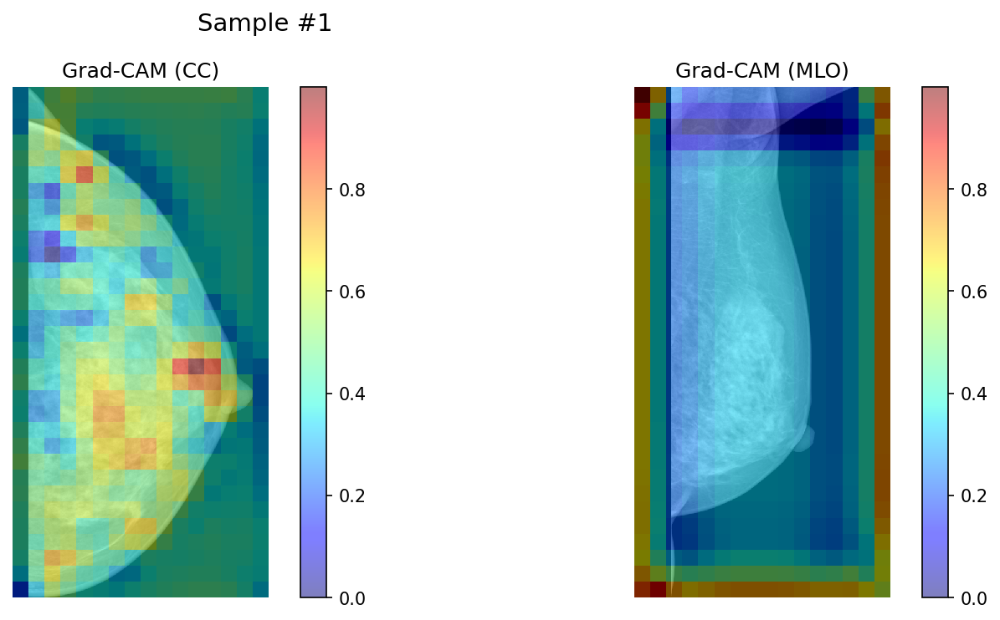

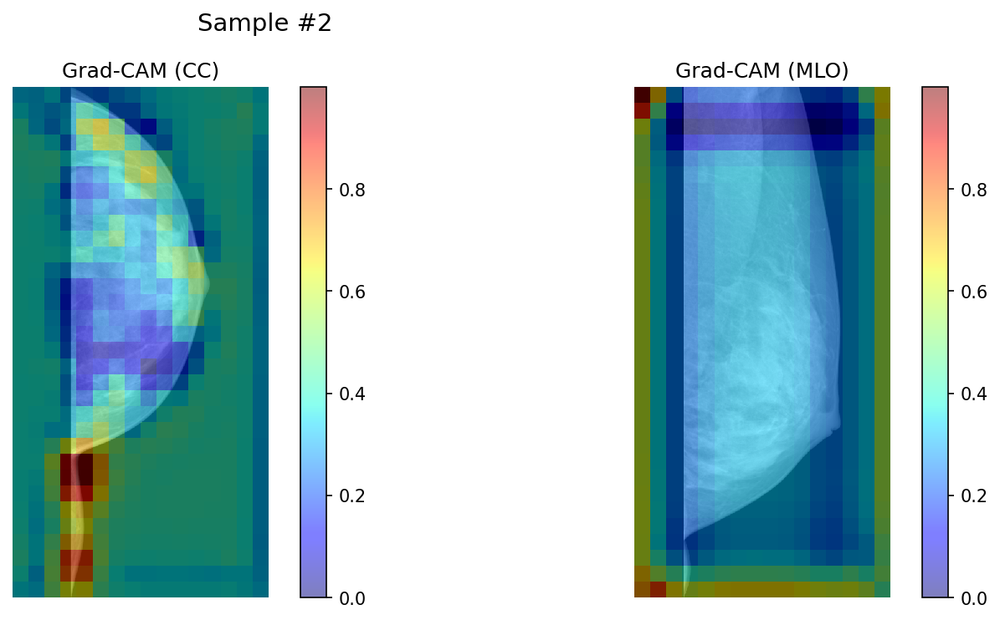

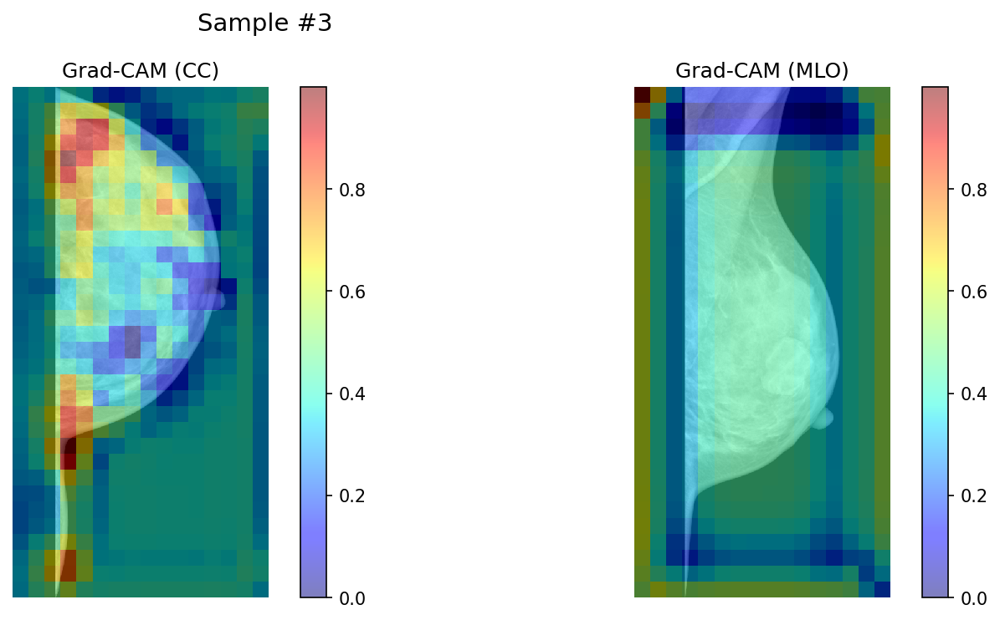

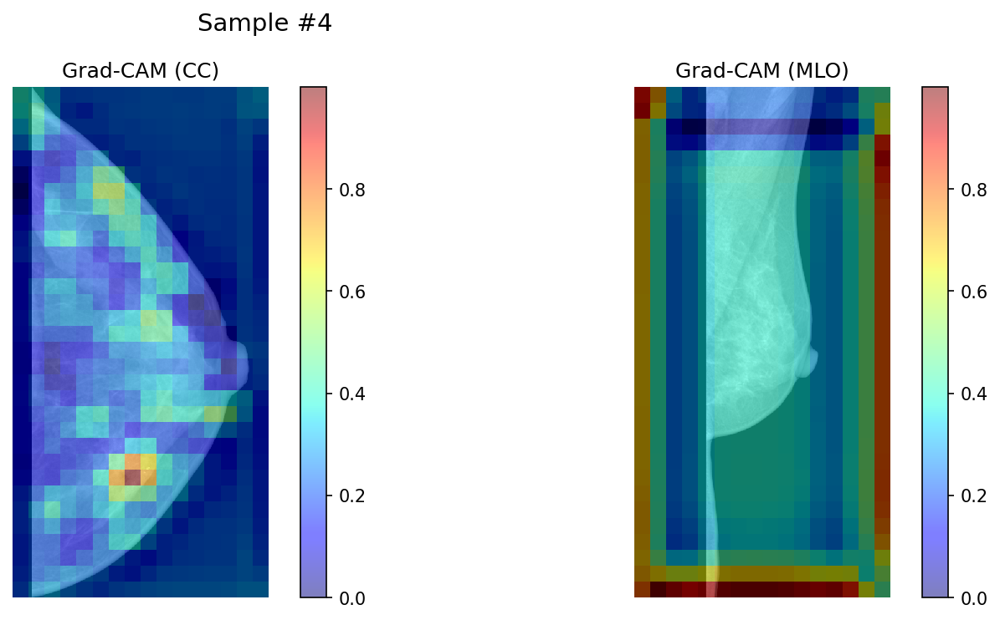

In [ ]:
import random

def show_random_gradcams(model, dataloader, device, num_samples=5):
    model.eval()
    shown = 0
    all_data = []

    # Raccogli tutti i sample in RAM (oppure fermati a pochi batch)
    for batch in dataloader:
        # Correctly unpack the batch
        inputs, labels = batch
        cc_imgs, mlo_imgs = inputs
        for i in range(len(cc_imgs)):
            all_data.append((cc_imgs[i], mlo_imgs[i], labels[i]))
        if len(all_data) > 100:  # limita RAM
            break

    # Campiona a caso
    random_samples = random.sample(all_data, num_samples)
    for idx, (cc, mlo, _) in enumerate(random_samples):
        visualize_gradcam_pair(model, cc, mlo, device, idx=idx)

import torch
import matplotlib.pyplot as plt
from captum.attr import LayerGradCam, LayerAttribution
import torch.nn.functional as F
import numpy as np

# ImageNet normalization used by torchvision models
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def denormalize(image_tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1).to(image_tensor.device)
    std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1).to(image_tensor.device)
    return image_tensor * std + mean

def normalize_cam(cam_tensor):
    cam_min = cam_tensor.min()
    cam_max = cam_tensor.max()
    return (cam_tensor - cam_min) / (cam_max - cam_min + 1e-8)

def visualize_gradcam_pair(model, cc_img, mlo_img, device, target_class=None, idx=None):
    model.eval()
    model.to(device)
    cc_img = cc_img.unsqueeze(0).to(device)
    mlo_img = mlo_img.unsqueeze(0).to(device)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=150)

    for i, (img, view) in enumerate(zip([cc_img, mlo_img], ['cc', 'mlo'])):
        # Use a deeper layer to improve CAM resolution (e.g., features[-3] instead of -1)
        layer = model.get_target_layer(view).children()
        layer = list(layer)[-3]  # override to a higher-res layer

        gradcam = LayerGradCam(model.forward_for_cam, layer)
        attribution = gradcam.attribute(img, target=target_class)

        # Resize CAM to match input image size dynamically
        _, _, H, W = img.shape
        cam = LayerAttribution.interpolate(attribution, (H, W))
        cam = normalize_cam(cam)  # Normalize CAM to [0, 1]

        # Denormalize and convert to grayscale
        denorm_img = denormalize(img).squeeze().permute(1, 2, 0).detach().cpu().numpy()
        gray_img = denorm_img.mean(axis=2)  # Convert to grayscale for visibility
        cam_np = cam.squeeze().detach().cpu().numpy()

        axes[i].imshow(gray_img, cmap='gray', interpolation='nearest')
        heatmap = axes[i].imshow(cam_np, cmap='jet', alpha=0.5, interpolation='nearest')
        axes[i].set_title(f"Grad-CAM ({view.upper()})")
        axes[i].axis('off')
        plt.colorbar(heatmap, ax=axes[i], fraction=0.046, pad=0.04)

    if idx is not None:
        fig.suptitle(f"Sample #{idx}", fontsize=14)

    plt.tight_layout()
    plt.show()


show_random_gradcams(model, test_loader, device, num_samples=5)

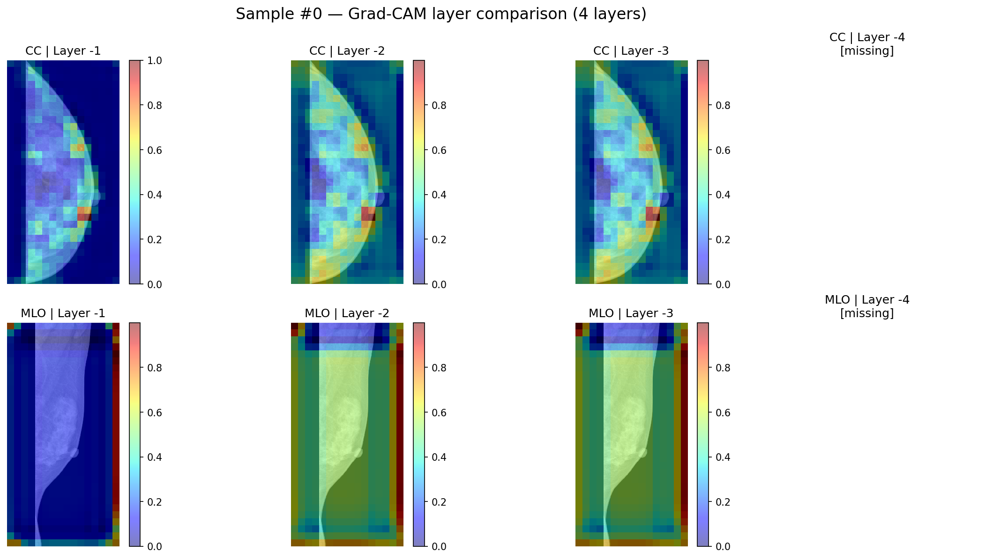

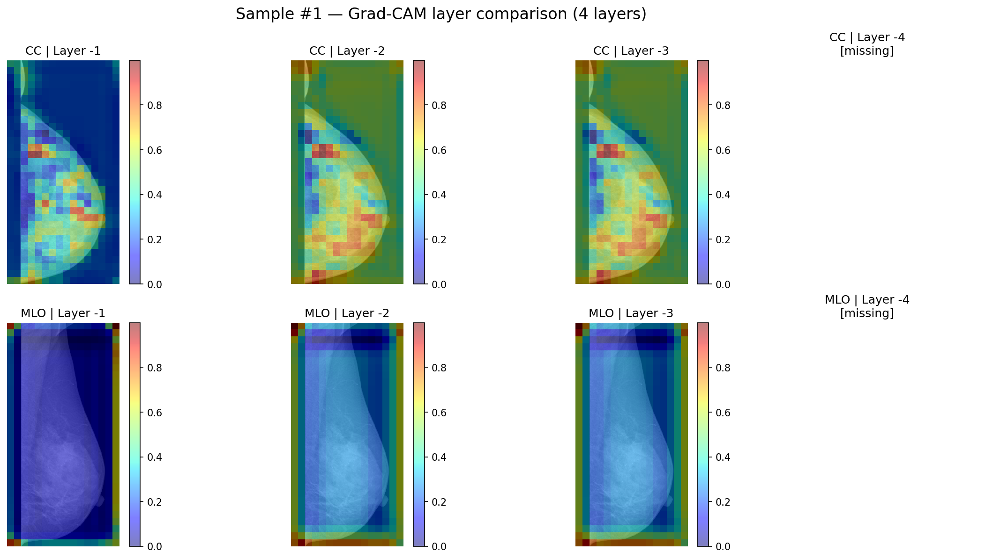

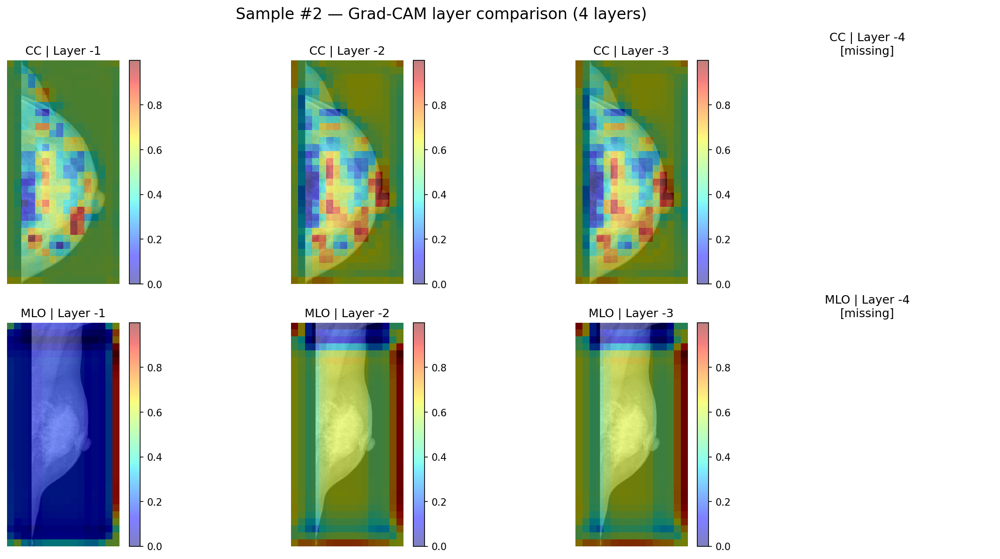

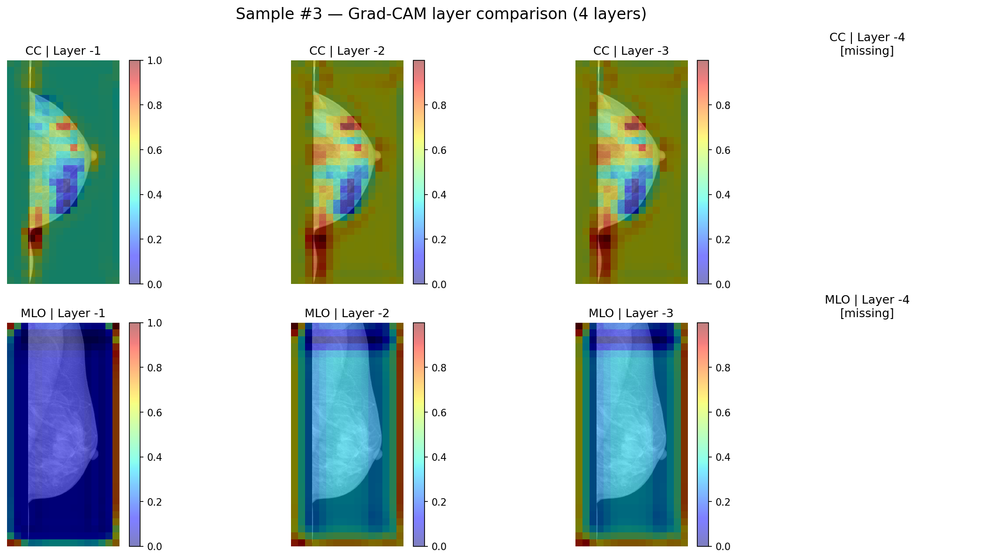

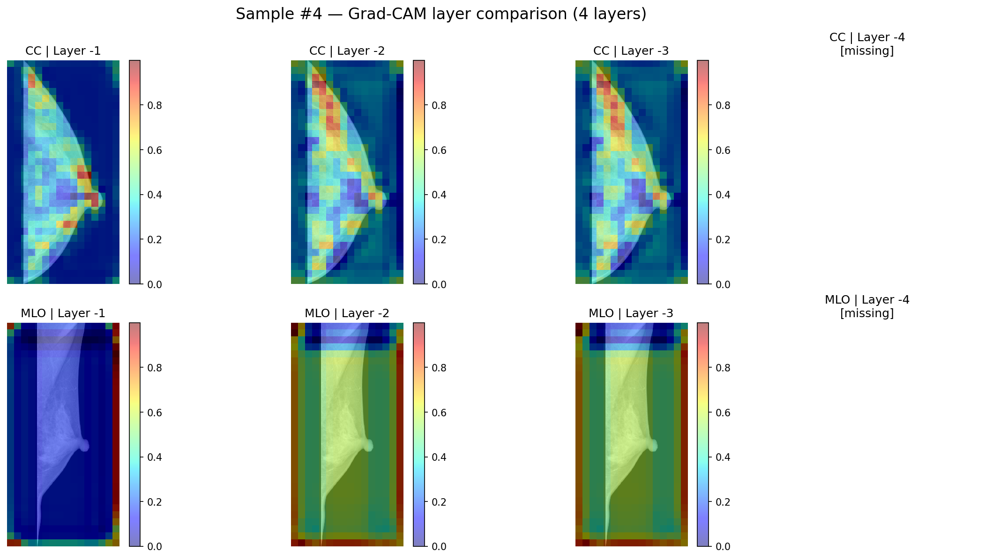

In [ ]:
import torch
import matplotlib.pyplot as plt
from captum.attr import LayerGradCam, LayerAttribution
import numpy as np

# Normalizzazione ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def denormalize(img):
    mean = torch.tensor(IMAGENET_MEAN).view(1,3,1,1).to(img.device)
    std = torch.tensor(IMAGENET_STD).view(1,3,1,1).to(img.device)
    return img * std + mean

def normalize_cam(cam):
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

def visualize_layer_comparison(model, cc_img, mlo_img, device, target_class=None, idx=None):
    model.eval().to(device)
    cc_img = cc_img.unsqueeze(0).to(device)
    mlo_img = mlo_img.unsqueeze(0).to(device)
    views = [('cc', cc_img), ('mlo', mlo_img)]
    layer_offsets = [ -1, -2, -3, -4 ]

    fig, axes = plt.subplots(2, 4, figsize=(16, 8), dpi=150)

    for row, (view, img) in enumerate(views):
        base_layer = model.get_target_layer(view)
        children = list(base_layer.children())

        for col, li in enumerate(layer_offsets):
            ax = axes[row, col]
            if abs(li) > len(children):
                ax.axis('off')
                ax.set_title(f"{view.upper()} | Layer {li}\n[missing]")
                continue

            layer = children[li]
            try:
                lgc = LayerGradCam(model.forward_for_cam, layer)
                attr = lgc.attribute(img, target=target_class)
                B,C,H,W = img.shape
                cam = LayerAttribution.interpolate(attr, (H,W))

                cam = normalize_cam(cam).squeeze().detach().cpu().numpy()

                #cam_np = normalize_cam(attribution.squeeze()).detach().cpu().numpy()

                den = denormalize(img).squeeze().permute(1,2,0).cpu().numpy().mean(axis=2)

                ax.imshow(den, cmap='gray', interpolation='nearest')
                hm = ax.imshow(cam, cmap='jet', alpha=0.5, interpolation='nearest')
                ax.set_title(f"{view.upper()} | Layer {li}")
                ax.axis('off')
                plt.colorbar(hm, ax=ax, fraction=0.046, pad=0.04)
            except Exception:
                ax.axis('off')
                ax.set_title(f"{view.upper()} | Layer {li}\n[error]")

    if idx is not None:
        fig.suptitle(f"Sample #{idx} — Grad‑CAM layer comparison (4 layers)", fontsize=16)
    plt.tight_layout()
    plt.show()


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

all_data = []
# Collect samples from the test loader
for inputs, labels in test_loader:
    cc_imgs, mlo_imgs = inputs
    for i in range(len(cc_imgs)):
        all_data.append((cc_imgs[i], mlo_imgs[i], labels[i]))
    # Limit the number of samples collected to avoid excessive memory usage
    if len(all_data) > 100:
        break

# Select 5 random samples from the collected data
num_samples_to_show = 5
random_samples = random.sample(all_data, min(num_samples_to_show, len(all_data)))

# Visualize layer comparison for each selected sample
for idx, (cc, mlo, _) in enumerate(random_samples):
    visualize_layer_comparison(model, cc, mlo, device, target_class=None, idx=idx)

In [ ]:
import cv2
import numpy as np
import torch
#from google.colab.patches import cv2_imshow

def genera_mask_from_tensor(tensor_img: torch.Tensor, threshold_value: int = 120):
    """
    Converte un tensore PyTorch in immagine NumPy,
    lo porta in scala di grigi e genera una maschera binaria.
    """
    # Porta su CPU e in numpy
    img = tensor_img.detach().cpu().numpy()

    # Se ha 3 canali (C,H,W) → (H,W,C)
    if img.ndim == 3 and img.shape[0] in [1,3]:
        img = np.transpose(img, (1, 2, 0))

    # Normalizza valori se necessario (0–1 → 0–255)
    if img.max() <= 1.0:
        img = (img * 255).astype(np.uint8)
    else:
        img = img.astype(np.uint8)

    # Scala di grigi
    if img.ndim == 3 and img.shape[2] == 3:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    elif img.ndim == 3 and img.shape[2] == 1:
        gray = img.squeeze(-1)
    else:  # già in scala di grigi
        gray = img

    # Threshold
    _, mask = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_BINARY)

    return gray, mask

# Uso dentro al tuo loop
for idx, (cc, mlo, _) in enumerate(random_samples):
    gray_cc, mask_cc = genera_mask_from_tensor(cc, threshold_value=120)
    gray_mlo, mask_mlo = genera_mask_from_tensor(mlo, threshold_value=120)

    print(f"Sample {idx} - CC")
    cv2.imshow("", gray_cc)
    cv2.imshow(mask_cc)

    print(f"Sample {idx} - MLO")
    cv2.imshow(gray_mlo)
    cv2.imshow(mask_mlo)


Sample 0 - CC


error: OpenCV(4.9.0) :-1: error: (-5:Bad argument) in function 'imshow'
> Overload resolution failed:
>  - imshow() missing required argument 'mat' (pos 2)
>  - imshow() missing required argument 'mat' (pos 2)
>  - imshow() missing required argument 'mat' (pos 2)


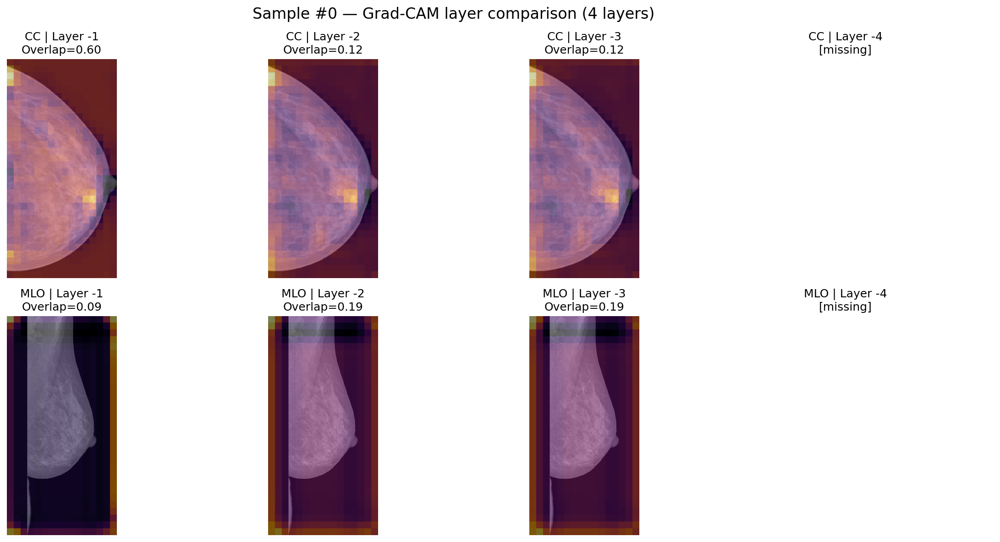

Sample 0 -> [{'sample_idx': 0, 'view': 'cc', 'layer_offset': -1, 'fraction': 0.6009126703402943}, {'sample_idx': 0, 'view': 'cc', 'layer_offset': -2, 'fraction': 0.11860758433241216}, {'sample_idx': 0, 'view': 'cc', 'layer_offset': -3, 'fraction': 0.11860758433241216}, {'sample_idx': 0, 'view': 'mlo', 'layer_offset': -1, 'fraction': 0.0877242026097209}, {'sample_idx': 0, 'view': 'mlo', 'layer_offset': -2, 'fraction': 0.19140297403803236}, {'sample_idx': 0, 'view': 'mlo', 'layer_offset': -3, 'fraction': 0.19140297403803236}]


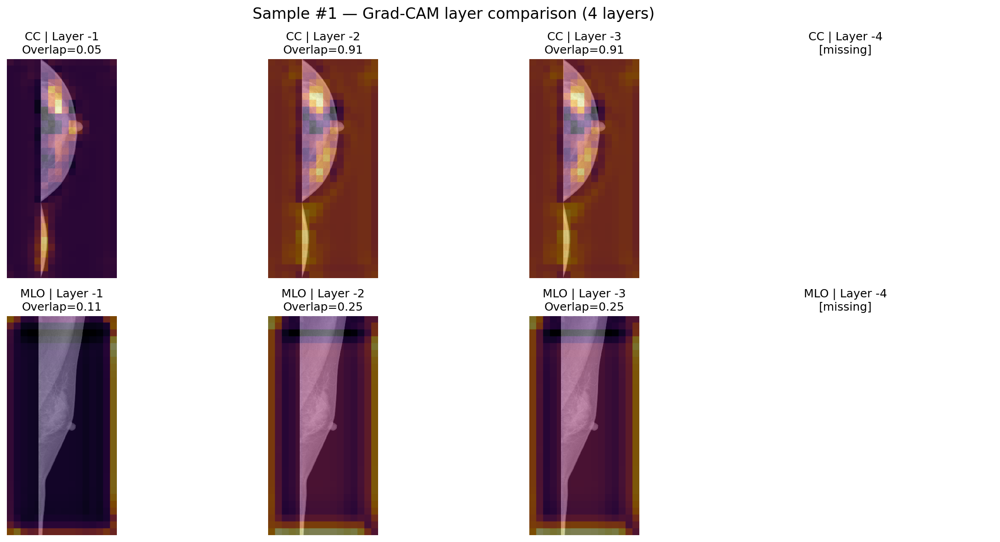

Sample 1 -> [{'sample_idx': 1, 'view': 'cc', 'layer_offset': -1, 'fraction': 0.048965835848445056}, {'sample_idx': 1, 'view': 'cc', 'layer_offset': -2, 'fraction': 0.908745672751084}, {'sample_idx': 1, 'view': 'cc', 'layer_offset': -3, 'fraction': 0.908745672751084}, {'sample_idx': 1, 'view': 'mlo', 'layer_offset': -1, 'fraction': 0.11264605450106047}, {'sample_idx': 1, 'view': 'mlo', 'layer_offset': -2, 'fraction': 0.24967939915183504}, {'sample_idx': 1, 'view': 'mlo', 'layer_offset': -3, 'fraction': 0.24967939915183504}]


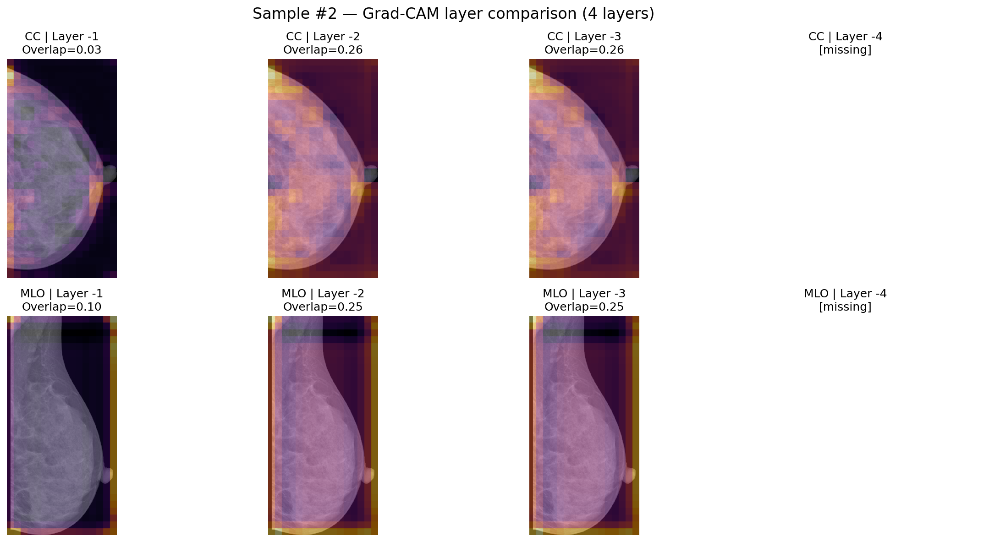

Sample 2 -> [{'sample_idx': 2, 'view': 'cc', 'layer_offset': -1, 'fraction': 0.030099994262195957}, {'sample_idx': 2, 'view': 'cc', 'layer_offset': -2, 'fraction': 0.2632112919968008}, {'sample_idx': 2, 'view': 'cc', 'layer_offset': -3, 'fraction': 0.2632112919968008}, {'sample_idx': 2, 'view': 'mlo', 'layer_offset': -1, 'fraction': 0.09577078990907534}, {'sample_idx': 2, 'view': 'mlo', 'layer_offset': -2, 'fraction': 0.25127836010016313}, {'sample_idx': 2, 'view': 'mlo', 'layer_offset': -3, 'fraction': 0.25127836010016313}]


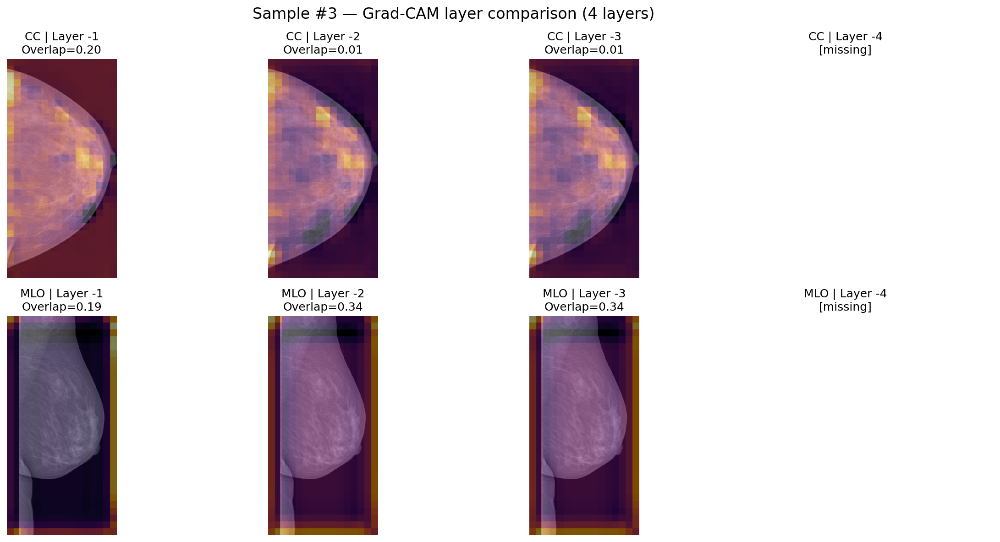

Sample 3 -> [{'sample_idx': 3, 'view': 'cc', 'layer_offset': -1, 'fraction': 0.1986846451845301}, {'sample_idx': 3, 'view': 'cc', 'layer_offset': -2, 'fraction': 0.007102315384846036}, {'sample_idx': 3, 'view': 'cc', 'layer_offset': -3, 'fraction': 0.007102315384846036}, {'sample_idx': 3, 'view': 'mlo', 'layer_offset': -1, 'fraction': 0.18766300908991976}, {'sample_idx': 3, 'view': 'mlo', 'layer_offset': -2, 'fraction': 0.33743846165716246}, {'sample_idx': 3, 'view': 'mlo', 'layer_offset': -3, 'fraction': 0.33743846165716246}]


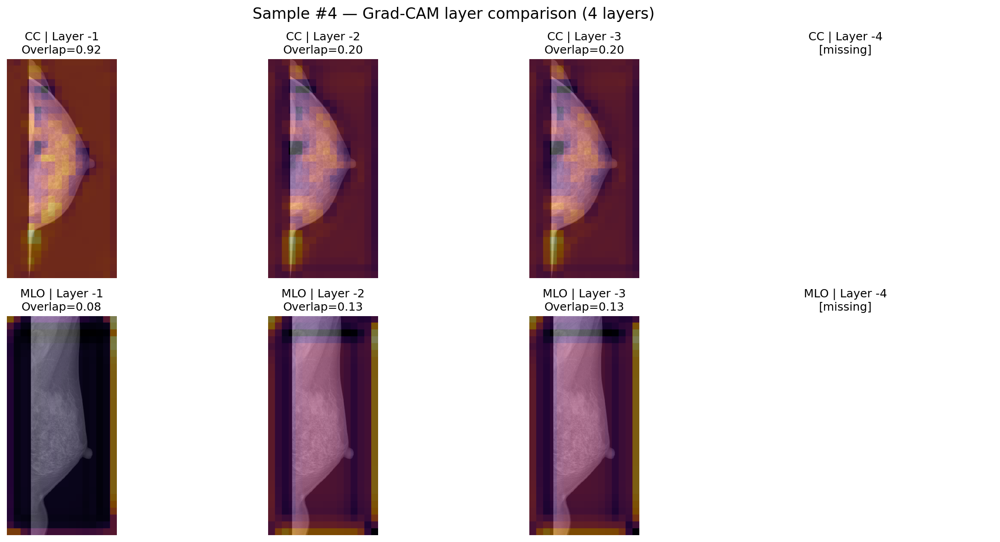

Sample 4 -> [{'sample_idx': 4, 'view': 'cc', 'layer_offset': -1, 'fraction': 0.9235942800423014}, {'sample_idx': 4, 'view': 'cc', 'layer_offset': -2, 'fraction': 0.1970658493220869}, {'sample_idx': 4, 'view': 'cc', 'layer_offset': -3, 'fraction': 0.1970658493220869}, {'sample_idx': 4, 'view': 'mlo', 'layer_offset': -1, 'fraction': 0.07705784276606621}, {'sample_idx': 4, 'view': 'mlo', 'layer_offset': -2, 'fraction': 0.13437854947452763}, {'sample_idx': 4, 'view': 'mlo', 'layer_offset': -3, 'fraction': 0.13437854947452763}]


In [ ]:
import torch
import matplotlib.pyplot as plt
from captum.attr import LayerGradCam, LayerAttribution
import numpy as np
import cv2
import pandas as pd
import os

# Normalizzazione ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def denormalize(img):
    mean = torch.tensor(IMAGENET_MEAN).view(1,3,1,1).to(img.device)
    std = torch.tensor(IMAGENET_STD).view(1,3,1,1).to(img.device)
    return img * std + mean

def normalize_cam(cam):
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

def genera_mask_from_tensor(tensor_img: torch.Tensor, threshold_value: int = 120):
    img = tensor_img.detach().cpu().numpy()
    if img.ndim == 4:
        img = img[0]
    if img.ndim == 3 and img.shape[0] in [1,3]:
        img = np.transpose(img, (1, 2, 0))
    if img.max() <= 1.0:
        img = (img * 255).astype(np.uint8)
    else:
        img = img.astype(np.uint8)
    if img.ndim == 3 and img.shape[2] == 3:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    elif img.ndim == 3 and img.shape[2] == 1:
        gray = img.squeeze(-1)
    else:
        gray = img
    _, mask = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_BINARY)
    return gray.astype(np.uint8), mask.astype(np.uint8)


def visualize_layer_comparison(model, cc_img, mlo_img, device,
                               target_class=None, idx=None,
                               cam_threshold: float = 0.5,
                               mask_threshold: int = 120,
                               csv_path: str = None):
    """
    Visualizza Grad-CAM su più layer, calcola la frazione di area della mask
    coperta da CAM sopra soglia e opzionalmente salva i risultati in un CSV.
    """
    model.eval().to(device)
    cc_img = cc_img.unsqueeze(0).to(device)
    mlo_img = mlo_img.unsqueeze(0).to(device)
    views = [('cc', cc_img), ('mlo', mlo_img)]
    layer_offsets = [ -1, -2, -3, -4 ]

    fig, axes = plt.subplots(2, 4, figsize=(16, 8), dpi=150)

    results = []  # lista per CSV

    for row, (view, img) in enumerate(views):
        base_layer = model.get_target_layer(view)
        children = list(base_layer.children())
        _, mask = genera_mask_from_tensor(img, threshold_value=mask_threshold)
        mask_bool = mask > 0

        for col, li in enumerate(layer_offsets):
            ax = axes[row, col]
            if abs(li) > len(children):
                ax.axis('off')
                ax.set_title(f"{view.upper()} | Layer {li}\n[missing]")
                continue

            layer = children[li]
            try:
                lgc = LayerGradCam(model.forward_for_cam, layer)
                attr = lgc.attribute(img, target=target_class)
                B,C,H,W = img.shape
                cam = LayerAttribution.interpolate(attr, (H,W))
                cam = normalize_cam(cam).squeeze().detach().cpu().numpy()

                # Threshold CAM
                cam_mask = cam > cam_threshold
                overlap = np.logical_and(mask_bool, cam_mask)
                fraction = overlap.sum() / (mask_bool.sum() + 1e-8)

                # Salva per CSV
                results.append({
                    "sample_idx": idx if idx is not None else -1,
                    "view": view,
                    "layer_offset": li,
                    "fraction": fraction
                })

                # Visualizzazione
                den = denormalize(img).squeeze().permute(1,2,0).cpu().numpy().mean(axis=2)
                ax.imshow(den, cmap='gray', interpolation='nearest')
                hm = ax.imshow(cam, cmap='inferno', alpha=0.5, interpolation='bilinear')
                ax.set_title(f"{view.upper()} | Layer {li}\nOverlap={fraction:.2f}")
                ax.axis('off')

            except Exception:
                ax.axis('off')
                ax.set_title(f"{view.upper()} | Layer {li}\n[error]")

    if idx is not None:
        fig.suptitle(f"Sample #{idx} — Grad-CAM layer comparison (4 layers)", fontsize=16)

    plt.tight_layout()
    plt.show()

    # Se richiesto, salva CSV
    if csv_path is not None:
        df = pd.DataFrame(results)
        if os.path.exists(csv_path):
            df.to_csv(csv_path, mode='a', header=False, index=False)
        else:
            df.to_csv(csv_path, index=False)

    return results


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

all_data = []
# Collect samples from the test loader
for inputs, labels in test_loader:
    cc_imgs, mlo_imgs = inputs
    for i in range(len(cc_imgs)):
        all_data.append((cc_imgs[i], mlo_imgs[i], labels[i]))
    if len(all_data) > 100:
        break

# Select 5 random samples from the collected data
num_samples_to_show = 5
random_samples = random.sample(all_data, min(num_samples_to_show, len(all_data)))

# Percorso CSV
csv_path = "fractions_results.csv"

# Visualize + salva frazioni su CSV
for idx, (cc, mlo, _) in enumerate(random_samples):
    results = visualize_layer_comparison(
        model, cc, mlo, device,
        target_class=None,
        idx=idx,
        cam_threshold=0.5,       # soglia per Grad-CAM
        mask_threshold=120,      # soglia per mask anatomica
        csv_path=csv_path        # salvataggio risultati
    )
    print(f"Sample {idx} ->", results)


In [ ]:
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score, confusion_matrix

# === Load doctor-provided bounding boxes ===
bbox_df = pd.read_csv(os.path.join(dataset_folder, "finding_annotations.csv")).dropna(how='any')
print('annotations #: ', len(bbox_df))
bbox_dict = {
    row['image_id']: {
        "orig_size": (row['width'], row['height']),
        "bbox": (row['xmin'], row['ymin'], row['xmax'], row['ymax'])
    }
    for _, row in bbox_df.iterrows()
}

#transform_doctor_box function is crucial for converting the original bounding box
#coordinates (from the full-resolution DICOM image) to the coordinates corresponding to the preprocessed and resized images used by the model.
 #This involves accounting for cropping and padding applied during image loading.
# === Mapping bbox to preprocessed image space ===

def transform_doctor_box(bbox, orig_size, crop_box, pad, heatmap_size, flip=False):
    x_min, y_min, x_max, y_max = bbox
    orig_w, orig_h = orig_size

    # === Flip box in original space before anything else ===
    if flip:
        x_min, x_max = orig_w - x_max, orig_w - x_min

    # Proceed with crop, pad, resize
    cx1, cy1, cx2, cy2 = crop_box
    pad_top, pad_bottom, pad_left, pad_right = pad
    heatmap_w, heatmap_h = heatmap_size

    # Apply crop
    x_min -= cx1
    x_max -= cx1
    y_min -= cy1
    y_max -= cy1

    # Apply padding
    x_min += pad_left
    x_max += pad_left
    y_min += pad_top
    y_max += pad_top

    # Resize to heatmap size
    padded_w = (cx2 - cx1) + pad_left + pad_right
    padded_h = (cy2 - cy1) + pad_top + pad_bottom

    scale_x = heatmap_w / padded_w
    scale_y = heatmap_h / padded_h

    x_min = int(x_min * scale_x)
    x_max = int(x_max * scale_x)
    y_min = int(y_min * scale_y)
    y_max = int(y_max * scale_y)

    # Clamp
    x_min = max(0, x_min)
    y_min = max(0, y_min)
    x_max = min(heatmap_w, x_max)
    y_max = min(heatmap_h, y_max)

    return (x_min, y_min, x_max, y_max)



# === Grad-CAM helper ===
#calculates the Grad-CAM heatmap for both CC and MLO views of a given image pair.

def compute_gradcam(model, cc_tensor, mlo_tensor, device):
    model.eval()
    cc_tensor = cc_tensor.to(device)
    mlo_tensor = mlo_tensor.to(device)

    output = model(cc_tensor, mlo_tensor)
    model.zero_grad()
    output[0].backward()

    cc_act = model.extract_cc_activation()
    mlo_act = model.extract_mlo_activation()
    cc_grad = cc_act.grad
    mlo_grad = mlo_act.grad

    def get_heatmap(act, grad):
        weights = grad.mean(dim=(2, 3), keepdim=True)
        cam = (weights * act).sum(dim=1).squeeze()
        #uses torch.clamp to set any negative values in the calculated CAM to 0
        cam = torch.clamp(cam, min=0).detach().cpu().numpy()
        #NORMALIZZO?
        cam = (cam - cam.min()) / (cam.max() + 1e-8)
        return cam

    cc_cam = get_heatmap(cc_act, cc_grad)
    mlo_cam = get_heatmap(mlo_act, mlo_grad)
    return cc_cam, mlo_cam, torch.sigmoid(output).item()

# === IoU + Overlay ===

# Function to compute the fraction of CAM inside the doctor's box
def compute_fraction_inside(cam, doctor_box, threshold=0.2):
    """
    Computes the fraction of Grad-CAM activation inside the doctor-provided bounding box,
    after applying a threshold to ignore low-activation regions.

    Args:
        cam (ndarray): 2D CAM heatmap, normalized to [0, 1].
        doctor_box (tuple): (x_min, y_min, x_max, y_max) in CAM coordinates.
        threshold (float): Minimum activation to consider (default=0.2).

    Returns:
        float: Fraction of CAM energy inside the doctor box.
    """
    if doctor_box is None:
        return None

    x_min, y_min, x_max, y_max = doctor_box

    if x_min >= x_max or y_min >= y_max:
        return 0.0  # Invalid box

    # Apply threshold
    cam_thresholded = np.where(cam >= threshold, cam, 0)

    # Extract CAM values inside the doctor box
    cam_inside_box = cam_thresholded[y_min:y_max, x_min:x_max]

    # Compute fraction of total CAM energy within the box
    return cam_inside_box.sum() / (cam_thresholded.sum() + 1e-8)


def show_overlay_with_bboxes(image_tensor, cam, doctor_box=None, title="Grad-CAM + BBoxes"):
    img = image_tensor.squeeze().cpu().numpy()
    if img.ndim == 3 and img.shape[0] == 3:
        img = np.transpose(img, (1, 2, 0))
    elif img.ndim == 2:
        img = np.expand_dims(img, -1)
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    cam_resized = cv2.resize(cam, (img.shape[1], img.shape[0]))
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)[..., ::-1] / 255.0
    if img.shape[-1] == 1:
        img = np.repeat(img, 3, axis=-1)
    overlay = np.clip(0.4 * heatmap + 0.6 * img, 0, 1)
    overlay = np.uint8(255 * overlay)
    if doctor_box:
        # Scale doctor_box back to image display size for visualization
        heatmap_h, heatmap_w = cam.shape # Heatmap shape is (H, W)
        img_h, img_w = img.shape[:2]

        scale_x = img_w / heatmap_w
        scale_y = img_h / heatmap_h

        display_box = (
            int(doctor_box[0] * scale_x),
            int(doctor_box[1] * scale_y),
            int(doctor_box[2] * scale_x),
            int(doctor_box[3] * scale_y)
        )

        cv2.rectangle(overlay, display_box[:2], display_box[2:], (255, 0, 0), 2)
    plt.imshow(overlay)
    plt.title(title)
    plt.axis("off")
    plt.show()



In [ ]:
def evaluate_and_visualize_gradcam(
    model, df, image_dict, info_dict, bbox_dict,
    device, dataset_name="test", max_images_to_show=10
):
    results = []
    shown_count = 0

    df_positive = df[df["binary_class"] == 1].reset_index(drop=True)
    df_positive_with_bbox = df_positive[
        df_positive.apply(lambda row: row["CC"] in bbox_dict or row["MLO"] in bbox_dict, axis=1)
    ].reset_index(drop=True)

    print(f"➡️  {dataset_name.upper()} | Positives: {len(df_positive)} | With bbox: {len(df_positive_with_bbox)}")

    for index, row in df_positive_with_bbox.iterrows():
        if shown_count >= max_images_to_show:
            break

        cc_id, mlo_id = row["CC"], row["MLO"]
        true_label = row["binary_class"]
        laterality = row["laterality"]

        try:
            cc_img_np, mlo_img_np = image_dict[(cc_id, mlo_id)]
            cc_tensor = torch.from_numpy(np.clip(cc_img_np, 0, train_pixel_max) / train_pixel_max).unsqueeze(0)
            mlo_tensor = torch.from_numpy(np.clip(mlo_img_np, 0, train_pixel_max) / train_pixel_max).unsqueeze(0)
            cc_tensor = cc_tensor.expand(3, -1, -1).unsqueeze(0).to(device)
            mlo_tensor = mlo_tensor.expand(3, -1, -1).unsqueeze(0).to(device)

            effnet_mean_t = torch.tensor(effnet_mean).view(1, 3, 1, 1).to(device)
            effnet_std_t = torch.tensor(effnet_std).view(1, 3, 1, 1).to(device)
            cc_tensor = (cc_tensor - effnet_mean_t) / effnet_std_t
            mlo_tensor = (mlo_tensor - effnet_mean_t) / effnet_std_t

        except KeyError:
            print(f"{dataset_name.upper()} - Image pair missing: {cc_id}, {mlo_id}")
            continue

        cc_cam, mlo_cam, pred = compute_gradcam(model, cc_tensor, mlo_tensor, device)
        cc_heatmap_size = cc_cam.shape[::-1]
        mlo_heatmap_size = mlo_cam.shape[::-1]

        try:
            info_cc, info_mlo = info_dict[(cc_id, mlo_id)]
        except KeyError:
            print(f"{dataset_name.upper()} - Info dict missing for {cc_id}, {mlo_id}")
            continue

        cc_info = bbox_dict.get(cc_id)
        mlo_info = bbox_dict.get(mlo_id)

        cc_doctor_box_heatmap = transform_doctor_box(
            cc_info["bbox"], cc_info["orig_size"], info_cc["crop_box"],
            info_cc["pad"], cc_heatmap_size, flip=(laterality == "R")
        ) if cc_info else None

        mlo_doctor_box_heatmap = transform_doctor_box(
            mlo_info["bbox"], mlo_info["orig_size"], info_mlo["crop_box"],
            info_mlo["pad"], mlo_heatmap_size, flip=(laterality == "R")
        ) if mlo_info else None

        cc_fraction_in = compute_fraction_inside(cc_cam, cc_doctor_box_heatmap) if cc_doctor_box_heatmap else None
        mlo_fraction_in = compute_fraction_inside(mlo_cam, mlo_doctor_box_heatmap) if mlo_doctor_box_heatmap else None

        results.append({
            "cc_id": cc_id,
            "mlo_id": mlo_id,
            "label": true_label,
            "prediction": pred,
            "cc_fraction_in": cc_fraction_in,
            "mlo_fraction_in": mlo_fraction_in,
            "dataset": dataset_name
        })

        show_overlay_with_bboxes(
            cc_tensor, cc_cam,
            doctor_box=cc_doctor_box_heatmap,
            title=f"{dataset_name.upper()} CC | Pred: {pred:.2f} | Frac: {'N/A' if cc_fraction_in is None else f'{cc_fraction_in:.2f}'}"
        )
        show_overlay_with_bboxes(
            mlo_tensor, mlo_cam,
            doctor_box=mlo_doctor_box_heatmap,
            title=f"{dataset_name.upper()} MLO | Pred: {pred:.2f} | Frac: {'N/A' if mlo_fraction_in is None else f'{mlo_fraction_in:.2f}'}"
        )

        shown_count += 1

    return pd.DataFrame(results)


In [ ]:
import os
import pydicom
import matplotlib.pyplot as plt

def evaluate_and_visualize_gradcam_w_original(
    model, df, image_dict, info_dict, bbox_df, bbox_dict,
    device, dataset_name="test", max_images_to_show=10, original=False
):
    results = []
    df_positive = df[df["binary_class"] == 1].reset_index(drop=True)
    df_positive_with_bbox = df_positive[
        df_positive.apply(lambda row: row["CC"] in bbox_dict or row["MLO"] in bbox_dict, axis=1)
    ].reset_index(drop=True)

    print(f"➡️  {dataset_name.upper()} | Positives: {len(df_positive)} | With bbox: {len(df_positive_with_bbox)}")

    for index, row in df_positive_with_bbox.iterrows():
        if len(results) >= max_images_to_show:
            break

        cc_id, mlo_id = row["CC"], row["MLO"]
        true_label = row["binary_class"]
        laterality = row["laterality"]

        try:
            cc_img_np, mlo_img_np = image_dict[(cc_id, mlo_id)]
            cc_tensor = torch.from_numpy(np.clip(cc_img_np, 0, train_pixel_max) / train_pixel_max).unsqueeze(0)
            mlo_tensor = torch.from_numpy(np.clip(mlo_img_np, 0, train_pixel_max) / train_pixel_max).unsqueeze(0)
            cc_tensor = cc_tensor.expand(3, -1, -1).unsqueeze(0).to(device)
            mlo_tensor = mlo_tensor.expand(3, -1, -1).unsqueeze(0).to(device)

            effnet_mean_t = torch.tensor(effnet_mean).view(1, 3, 1, 1).to(device)
            effnet_std_t = torch.tensor(effnet_std).view(1, 3, 1, 1).to(device)
            cc_tensor = (cc_tensor - effnet_mean_t) / effnet_std_t
            mlo_tensor = (mlo_tensor - effnet_mean_t) / effnet_std_t
        except KeyError:
            continue

        cc_cam, mlo_cam, pred = compute_gradcam(model, cc_tensor, mlo_tensor, device)
        cc_heatmap_size = cc_cam.shape[::-1]
        mlo_heatmap_size = mlo_cam.shape[::-1]

        try:
            info_cc, info_mlo = info_dict[(cc_id, mlo_id)]
        except KeyError:
            continue

        cc_info = bbox_dict.get(cc_id)
        mlo_info = bbox_dict.get(mlo_id)

        cc_doctor_box_heatmap = transform_doctor_box(
            cc_info["bbox"], cc_info["orig_size"], info_cc["crop_box"],
            info_cc["pad"], cc_heatmap_size, flip=(laterality == "R")
        ) if cc_info else None

        mlo_doctor_box_heatmap = transform_doctor_box(
            mlo_info["bbox"], mlo_info["orig_size"], info_mlo["crop_box"],
            info_mlo["pad"], mlo_heatmap_size, flip=(laterality == "R")
        ) if mlo_info else None

        cc_fraction_in = compute_fraction_inside(cc_cam, cc_doctor_box_heatmap) if cc_doctor_box_heatmap else None
        mlo_fraction_in = compute_fraction_inside(mlo_cam, mlo_doctor_box_heatmap) if mlo_doctor_box_heatmap else None

        results.append({
            "cc_id": cc_id,
            "mlo_id": mlo_id,
            "label": true_label,
            "prediction": pred,
            "cc_fraction_in": cc_fraction_in,
            "mlo_fraction_in": mlo_fraction_in,
            "laterality": laterality
        })

    # === Sort by prediction (descending)
    results = sorted(results, key=lambda x: -x["prediction"])
    print(f"📊 Showing top {min(max_images_to_show, len(results))} samples by predicted score.")

    for entry in results[:max_images_to_show]:
        cc_id = entry["cc_id"]
        mlo_id = entry["mlo_id"]
        pred = entry["prediction"]
        laterality = entry["laterality"]

        # Reload tensor (for visualization)
        cc_img_np, mlo_img_np = image_dict[(cc_id, mlo_id)]
        cc_tensor = torch.from_numpy(np.clip(cc_img_np, 0, train_pixel_max) / train_pixel_max).unsqueeze(0)
        mlo_tensor = torch.from_numpy(np.clip(mlo_img_np, 0, train_pixel_max) / train_pixel_max).unsqueeze(0)
        cc_tensor = cc_tensor.expand(3, -1, -1).unsqueeze(0).to(device)
        mlo_tensor = mlo_tensor.expand(3, -1, -1).unsqueeze(0).to(device)
        cc_tensor = (cc_tensor - effnet_mean_t) / effnet_std_t
        mlo_tensor = (mlo_tensor - effnet_mean_t) / effnet_std_t

        cc_cam, mlo_cam, _ = compute_gradcam(model, cc_tensor, mlo_tensor, device)

        info_cc, info_mlo = info_dict[(cc_id, mlo_id)]
        cc_info = bbox_dict.get(cc_id)
        mlo_info = bbox_dict.get(mlo_id)

        cc_box = transform_doctor_box(
            cc_info["bbox"], cc_info["orig_size"], info_cc["crop_box"],
            info_cc["pad"], cc_cam.shape[::-1], flip=(laterality == "R")
        ) if cc_info else None

        mlo_box = transform_doctor_box(
            mlo_info["bbox"], mlo_info["orig_size"], info_mlo["crop_box"],
            info_mlo["pad"], mlo_cam.shape[::-1], flip=(laterality == "R")
        ) if mlo_info else None

        # === Show Grad-CAM
        show_overlay_with_bboxes(cc_tensor, cc_cam, doctor_box=cc_box, title=f"Grad-CAM CC | pred: {pred:.2f}| Frac: {'N/A' if cc_fraction_in is None else f'{cc_fraction_in:.2f}'}")
        show_overlay_with_bboxes(mlo_tensor, mlo_cam, doctor_box=mlo_box, title=f"Grad-CAM MLO | pred: {pred:.2f}| Frac: {'N/A' if mlo_fraction_in is None else f'{mlo_fraction_in:.2f}'}")

        # === Show ORIGINAL DICOM with doctor box
        def show_original_dicom(image_id):
            row = bbox_df[bbox_df["image_id"] == image_id].iloc[0]
            dicom_path = os.path.join(dataset_folder,'images', row["study_id"], row["image_id"] + ".dicom")
            try:
                dcm = pydicom.dcmread(dicom_path)
                img = dcm.pixel_array.astype(np.float32)
                img = (img - img.min()) / (img.max() - img.min() + 1e-8)
                img = np.uint8(255 * img)

                # Draw box
                x1, y1, x2, y2 = int(row["xmin"]), int(row["ymin"]), int(row["xmax"]), int(row["ymax"])
                img_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
                cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (255, 0, 0), 2)

                plt.figure(figsize=(6, 6))
                plt.imshow(img_rgb, cmap='gray')
                plt.title(f"Original {image_id}")
                plt.axis('off')
                plt.show()
            except Exception as e:
                print(f"Error loading {dicom_path}: {e}")

        if cc_id in bbox_df["image_id"].values:
            show_original_dicom(cc_id)
        if mlo_id in bbox_df["image_id"].values:
            show_original_dicom(mlo_id)

    return pd.DataFrame(results)


In [ ]:
df_test_results = evaluate_and_visualize_gradcam_w_original(
    model, test_df, image_dict, info_dict, bbox_df, bbox_dict,
    device, dataset_name="test", max_images_to_show=10, original=True
)

In [ ]:
plot_view_fractions(df_test_results, cc_column="cc_fraction_in", mlo_column="mlo_fraction_in", title= "Test Set: Grad-CAM Fraction Inside Doctor Box")

In [ ]:
df_test_results = evaluate_and_visualize_gradcam_w_original(
    model, test_df, image_dict, info_dict, bbox_df, bbox_dict,
    device, dataset_name="test", max_images_to_show=10
)

In [ ]:
df_val_results = evaluate_and_visualize_gradcam_w_original(
    model, val_df, image_dict, info_dict, bbox_df, bbox_dict,
    device, dataset_name="val", max_images_to_show=10
)

In [ ]:
df_train_results = evaluate_and_visualize_gradcam_w_original(
    model, train_df, image_dict, info_dict,bbox_df, bbox_dict,
    device, dataset_name="train", max_images_to_show=10
)

In [ ]:
plot_view_fractions(df_test_results, cc_column="cc_fraction_in", mlo_column="mlo_fraction_in", title= "Test Set: Grad-CAM Fraction Inside Doctor Box")
plot_view_fractions(df_val_results, cc_column="cc_fraction_in", mlo_column="mlo_fraction_in", title= "Validation Set: Grad-CAM Fraction Inside Doctor Box")
plot_view_fractions(df_train_results, cc_column="cc_fraction_in", mlo_column="mlo_fraction_in", title= "Training Set: Grad-CAM Fraction Inside Doctor Box")

In [ ]:
# Debugging the transformed doctor boxes and heatmap size

print("Debugging transformed bounding boxes and heatmap size:")
max_debug_images = 5
debug_count = 0

for batch_idx, ((cc_batch, mlo_batch), labels) in enumerate(test_loader):
    batch_size = len(cc_batch)
    for i in range(batch_size):
        if debug_count >= max_debug_images:
            break

        global_idx = batch_idx * test_loader.batch_size + i
        if global_idx >= len(test_df):
            continue

        cc_id = test_df.iloc[global_idx]['CC']
        mlo_id = test_df.iloc[global_idx]['MLO']

        # Only debug if there's a bounding box annotation
        if cc_id not in bbox_dict and mlo_id not in bbox_dict:
            continue

        print(f"\n--- Debugging Image Pair: CC ID - {cc_id}, MLO ID - {mlo_id} ---")

        # Get pre-processing info
        try:
            info_cc, info_mlo = info_dict[(cc_id, mlo_id)]
        except KeyError:
            print("Info dict entry missing. Skipping.")
            continue

        # Get original bbox info
        cc_info = bbox_dict.get(cc_id)
        mlo_info = bbox_dict.get(mlo_id)

        # Get image tensors and compute CAMs (needed for heatmap size)
        cc_tensor = cc_batch[i].unsqueeze(0).to(device)
        mlo_tensor = mlo_batch[i].unsqueeze(0).to(device)
        cc_cam, mlo_cam, pred = compute_gradcam(model, cc_tensor, mlo_tensor, device)


        # Transform doctor box and print details
        if cc_info:
            cc_doctor_box_transformed = transform_doctor_box(
                cc_info["bbox"], cc_info["orig_size"],
                info_cc["crop_box"], info_cc["pad"],
                (cc_tensor.shape[-1], cc_tensor.shape[-2])
            )
            print(f"CC Doctor Box (Original): {cc_info['bbox']}")
            print(f"CC Doctor Box (Transformed): {cc_doctor_box_transformed}")
            print(f"CC Heatmap shape: {cc_cam.shape}")
            x_min, y_min, x_max, y_max = cc_doctor_box_transformed
            if x_min >= x_max or y_min >= y_max:
                 print("WARNING: Transformed CC box is invalid.")
            if x_max > cc_cam.shape[1] or y_max > cc_cam.shape[0]:
                 print("WARNING: Transformed CC box is outside heatmap bounds.")


        if mlo_info:
            mlo_doctor_box_transformed = transform_doctor_box(
                mlo_info["bbox"], mlo_info["orig_size"],
                info_mlo["crop_box"], info_mlo["pad"],
                (mlo_tensor.shape[-1], mlo_tensor.shape[-2])
            )
            print(f"MLO Doctor Box (Original): {mlo_info['bbox']}")
            print(f"MLO Doctor Box (Transformed): {mlo_doctor_box_transformed}")
            print(f"MLO Heatmap shape: {mlo_cam.shape}")
            x_min, y_min, x_max, y_max = mlo_doctor_box_transformed
            if x_min >= x_max or y_min >= y_max:
                 print("WARNING: Transformed MLO box is invalid.")
            if x_max > mlo_cam.shape[1] or y_max > mlo_cam.shape[0]:
                 print("WARNING: Transformed MLO box is outside heatmap bounds.")


        debug_count += 1
    if debug_count >= max_debug_images:
        break

In [ ]:
# Check which image IDs from test_df are not in bbox_dict

test_image_ids = set(test_df['CC'].tolist() + test_df['MLO'].tolist())
bbox_image_ids = set(bbox_dict.keys())

missing_image_ids = test_image_ids - bbox_image_ids

print(f"Number of unique image IDs in test_df: {len(test_image_ids)}")
print(f"Number of unique image IDs in bbox_dict: {len(bbox_image_ids)}")
print(f"Number of image IDs in test_df missing from bbox_dict: {len(missing_image_ids)}")

In [ ]:
import random

def show_random_gradcams(model, dataloader, device, num_samples=5):
    model.eval()
    shown = 0
    all_data = []

    # Raccogli tutti i sample in RAM (oppure fermati a pochi batch)
    for batch in dataloader:
        # Correctly unpack the batch
        inputs, labels = batch
        cc_imgs, mlo_imgs = inputs
        for i in range(len(cc_imgs)):
            all_data.append((cc_imgs[i], mlo_imgs[i], labels[i]))
        if len(all_data) > 100:  # limita RAM
            break

    # Campiona a caso
    random_samples = random.sample(all_data, num_samples)
    for idx, (cc, mlo, _) in enumerate(random_samples):
        visualize_gradcam_pair(model, cc, mlo, device, idx=idx)

In [ ]:
import torch
import matplotlib.pyplot as plt
from captum.attr import LayerGradCam, LayerAttribution
import torch.nn.functional as F
import numpy as np

# ImageNet normalization used by torchvision models
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def denormalize(image_tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1).to(image_tensor.device)
    std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1).to(image_tensor.device)
    return image_tensor * std + mean

def normalize_cam(cam_tensor):
    cam_min = cam_tensor.min()
    cam_max = cam_tensor.max()
    return (cam_tensor - cam_min) / (cam_max - cam_min + 1e-8)

def visualize_gradcam_pair(model, cc_img, mlo_img, device, target_class=None, idx=None):
    model.eval()
    model.to(device)
    cc_img = cc_img.unsqueeze(0).to(device)
    mlo_img = mlo_img.unsqueeze(0).to(device)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=150)

    for i, (img, view) in enumerate(zip([cc_img, mlo_img], ['cc', 'mlo'])):
        # Use a deeper layer to improve CAM resolution (e.g., features[-3] instead of -1)
        layer = model.get_target_layer(view).children()
        layer = list(layer)[-3]  # override to a higher-res layer

        gradcam = LayerGradCam(model.forward_for_cam, layer)
        attribution = gradcam.attribute(img, target=target_class)

        # Resize CAM to match input image size dynamically
        _, _, H, W = img.shape
        cam = LayerAttribution.interpolate(attribution, (H, W))
        cam = normalize_cam(cam)  # Normalize CAM to [0, 1]

        # Denormalize and convert to grayscale
        denorm_img = denormalize(img).squeeze().permute(1, 2, 0).detach().cpu().numpy()
        gray_img = denorm_img.mean(axis=2)  # Convert to grayscale for visibility
        cam_np = cam.squeeze().detach().cpu().numpy()

        axes[i].imshow(gray_img, cmap='gray', interpolation='nearest')
        heatmap = axes[i].imshow(cam_np, cmap='jet', alpha=0.5, interpolation='nearest')
        axes[i].set_title(f"Grad-CAM ({view.upper()})")
        axes[i].axis('off')
        plt.colorbar(heatmap, ax=axes[i], fraction=0.046, pad=0.04)

    if idx is not None:
        fig.suptitle(f"Sample #{idx}", fontsize=14)

    plt.tight_layout()
    plt.show()


show_random_gradcams(model, test_loader, device, num_samples=5)

In [ ]:
import torch
import matplotlib.pyplot as plt
from captum.attr import LayerGradCam, LayerAttribution
import numpy as np

# Normalizzazione ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def denormalize(img):
    mean = torch.tensor(IMAGENET_MEAN).view(1,3,1,1).to(img.device)
    std = torch.tensor(IMAGENET_STD).view(1,3,1,1).to(img.device)
    return img * std + mean

def normalize_cam(cam):
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

def visualize_layer_comparison(model, cc_img, mlo_img, device, target_class=None, idx=None):
    model.eval().to(device)
    cc_img = cc_img.unsqueeze(0).to(device)
    mlo_img = mlo_img.unsqueeze(0).to(device)
    views = [('cc', cc_img), ('mlo', mlo_img)]
    layer_offsets = [ -1, -2, -3, -4 ]

    fig, axes = plt.subplots(2, 4, figsize=(16, 8), dpi=150)

    for row, (view, img) in enumerate(views):
        base_layer = model.get_target_layer(view)
        children = list(base_layer.children())

        for col, li in enumerate(layer_offsets):
            ax = axes[row, col]
            if abs(li) > len(children):
                ax.axis('off')
                ax.set_title(f"{view.upper()} | Layer {li}\n[missing]")
                continue

            layer = children[li]
            try:
                lgc = LayerGradCam(model.forward_for_cam, layer)
                attr = lgc.attribute(img, target=target_class)
                B,C,H,W = img.shape
                cam = LayerAttribution.interpolate(attr, (H,W))

                cam = normalize_cam(cam).squeeze().detach().cpu().numpy()

                #cam_np = normalize_cam(attribution.squeeze()).detach().cpu().numpy()

                den = denormalize(img).squeeze().permute(1,2,0).cpu().numpy().mean(axis=2)

                ax.imshow(den, cmap='gray', interpolation='nearest')
                hm = ax.imshow(cam, cmap='jet', alpha=0.5, interpolation='nearest')
                ax.set_title(f"{view.upper()} | Layer {li}")
                ax.axis('off')
                plt.colorbar(hm, ax=ax, fraction=0.046, pad=0.04)
            except Exception:
                ax.axis('off')
                ax.set_title(f"{view.upper()} | Layer {li}\n[error]")

    if idx is not None:
        fig.suptitle(f"Sample #{idx} — Grad‑CAM layer comparison (4 layers)", fontsize=16)
    plt.tight_layout()
    plt.show()


In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

all_data = []
# Collect samples from the test loader
for inputs, labels in test_loader:
    cc_imgs, mlo_imgs = inputs
    for i in range(len(cc_imgs)):
        all_data.append((cc_imgs[i], mlo_imgs[i], labels[i]))
    # Limit the number of samples collected to avoid excessive memory usage
    if len(all_data) > 100:
        break

# Select 5 random samples from the collected data
num_samples_to_show = 5
random_samples = random.sample(all_data, min(num_samples_to_show, len(all_data)))

# Visualize layer comparison for each selected sample
for idx, (cc, mlo, _) in enumerate(random_samples):
    visualize_layer_comparison(model, cc, mlo, device, target_class=None, idx=idx)

# End